In [1]:
import os
import h5py
import glob
import numpy as np
import pandas as pd
import math
from scipy.integrate import quad
from astropy import constants as const
from scipy.interpolate import interp1d
from scipy.interpolate import CubicSpline

from scipy.signal import savgol_filter

import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 200
mpl.rcParams['savefig.dpi'] = 300

import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    "font.size": 14,
})
import cmasher as cmr
import gc
gc.collect()

775

# From power spectra to chracteristic bubble sizes

# Old plots

In [2]:
# =========================================================
# FULL OOP PIPELINE FOR POWER SPECTRUM ANALYSIS
# =========================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.signal import savgol_filter

# =========================================================
# Matplotlib style (same as your original)
# =========================================================

mpl.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 20,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "axes.linewidth": 2.0,
    "xtick.major.width": 1.8,
    "ytick.major.width": 1.8,
    "xtick.minor.width": 1.2,
    "ytick.minor.width": 1.2,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "xtick.minor.size": 4,
    "ytick.minor.size": 4,
    "figure.dpi": 150,
    "savefig.dpi": 300,
})

# =========================================================
# Field definition
# =========================================================

class FieldType:
    def __init__(self, name, label):
        self.name = name
        self.label = label


# Define your fields
HII   = FieldType("f_HII",   r"$\Delta^2_{x_{\rm H\ II}}$")
Tb_H  = FieldType("Tb_H",    r"$\Delta^2_{T^{\rm H}_b}$")
HeIII = FieldType("f_HeIII", r"$\Delta^2_{x_{\rm He\ III}}$")
Tb_He = FieldType("Tb_He",   r"$\Delta^2_{T^{\rm He}_b}$")

# =========================================================
# Power Spectrum Object
# =========================================================

class PowerSpectrum:
    def __init__(self, z, k, delta2, field):
        self.z = z
        self.k = k
        self.delta2 = delta2
        self.field = field

        self._peak_cache = None

    def smooth(self, window=11, poly=2):
        logd = np.log10(self.delta2)
        smooth_log = savgol_filter(logd, window, poly)
        return 10**smooth_log

    def find_peak(self, peak_finder):
        if self._peak_cache is None:
            self._peak_cache = peak_finder.find(self.k, self.delta2)
        return self._peak_cache

    def bubble_size(self, peak_finder):
        k_peak, _, _ = self.find_peak(peak_finder)
        if np.isfinite(k_peak):
            return 2.0 * np.pi / k_peak
        return np.nan


# =========================================================
# Peak Finder (your robust method)
# =========================================================

class PeakFinder:
    def __init__(self,
                 kmin=0.1,
                 kmax=6.0,
                 window_length=11,
                 polyorder=2,
                 fit_points=4):

        self.kmin = kmin
        self.kmax = kmax
        self.window_length = window_length
        self.polyorder = polyorder
        self.fit_points = fit_points

    def find(self, k, delta2):

        mask = (k > self.kmin) & (k < self.kmax)
        k_fit = k[mask]
        d_fit = delta2[mask]

        if len(k_fit) < self.window_length:
            return np.nan, np.nan, None

        logk = np.log10(k_fit)
        logd = np.log10(d_fit)

        smooth_logd = savgol_filter(
            logd,
            window_length=self.window_length,
            polyorder=self.polyorder
        )

        i_peak = np.argmax(smooth_logd)

        if i_peak < self.fit_points or i_peak > len(logk) - self.fit_points - 1:
            return np.nan, np.nan, None

        sl = slice(i_peak - self.fit_points, i_peak + self.fit_points + 1)

        x_local = logk[sl]
        y_local = smooth_logd[sl]

        a, b, c = np.polyfit(x_local, y_local, 2)

        if a >= 0:
            return np.nan, np.nan, None

        logk_peak = -b / (2 * a)
        k_peak = 10**logk_peak

        logd_peak = a * logk_peak**2 + b * logk_peak + c
        d_peak = 10**logd_peak

        return k_peak, d_peak, smooth_logd


# =========================================================
# Loader
# =========================================================

class PowerSpectrumLoader:
    def __init__(self, base_path, skiprows=5):
        self.base_path = base_path
        self.skiprows = skiprows

    def load(self, field, snapshot):

        filename = f"{self.base_path}/{field.name}/PS_{snapshot}.out"

        with open(filename) as f:
            lines = f.readlines()
            z = float(lines[0])
            mean = float(lines[2]) / float(lines[3])

        data = np.loadtxt(filename, skiprows=self.skiprows)

        k = data[:, 0] * 1e3
        delta2 = data[:, 1] * mean**2
        nmodes = data[:, 3]

        mask = nmodes > 0

        return PowerSpectrum(
            z, k[mask], delta2[mask], field
        )

    def load_all(self, field):

        folder = f"{self.base_path}/{field.name}"

        files = sorted([
            f for f in os.listdir(folder)
            if f.endswith(".out")
        ])

        snapshots = [
            int(f.split("_")[1].split(".")[0])
            for f in files
        ]

        spectra = [self.load(field, s) for s in snapshots]

        spectra.sort(key=lambda ps: ps.z, reverse=True)

        return PowerSpectrumSet(spectra)


# =========================================================
# Dataset container
# =========================================================

class PowerSpectrumSet:
    def __init__(self, spectra):
        self.spectra = spectra

    def redshifts(self):
        return np.array([ps.z for ps in self.spectra])

    def bubble_history(self, peak_finder):

        results = []

        for ps in self.spectra:
            k_peak, d_peak, _ = ps.find_peak(peak_finder)

            if np.isfinite(k_peak):
                R = ps.bubble_size(peak_finder)
                results.append([ps.z, k_peak, d_peak, R])

        return np.array(results)


# =========================================================
# Plotter
# =========================================================

class PSPlotter:

    def plot_spectra(self, ax, ps_set, show_peaks=False, peak_finder=None):

        zs = ps_set.redshifts()

        cmap = plt.get_cmap("plasma_r")
        norm = mpl.colors.Normalize(vmin=zs.min(), vmax=zs.max())

        for ps in ps_set.spectra:

            y = ps.smooth()

            color = cmap(norm(ps.z))

            ax.loglog(ps.k, y, color=color, lw=2.2)

            if show_peaks and peak_finder is not None:
                k_peak, d_peak, _ = ps.find_peak(peak_finder)

                if np.isfinite(k_peak):
                    ax.scatter(
                        k_peak,
                        d_peak,
                        s=55,
                        color=color,
                        edgecolor="black",
                        linewidth=0.7,
                        zorder=10
                    )

        ax.set_ylabel(ps_set.spectra[0].field.label + "(k)")
        ax.set_xlim(0.02, 10)
        #ax.set_ylim(5e-5, 2e-1)

        ax.tick_params(which="both", direction="in", top=True, right=True)
        ax.minorticks_on()

        return norm

    def plot_bubble(self, ax, ps_set, peak_finder):

        data = ps_set.bubble_history(peak_finder)

        z = data[:, 0]
        R = data[:, 3]

        ax.plot(z, R, marker="o", lw=2)

        ax.invert_xaxis()
        ax.set_xlabel(r"$z$")
        ax.set_ylabel(r"$R_{\rm bubble}$")

        ax.tick_params(which="both", direction="in", top=True, right=True)
        ax.minorticks_on()

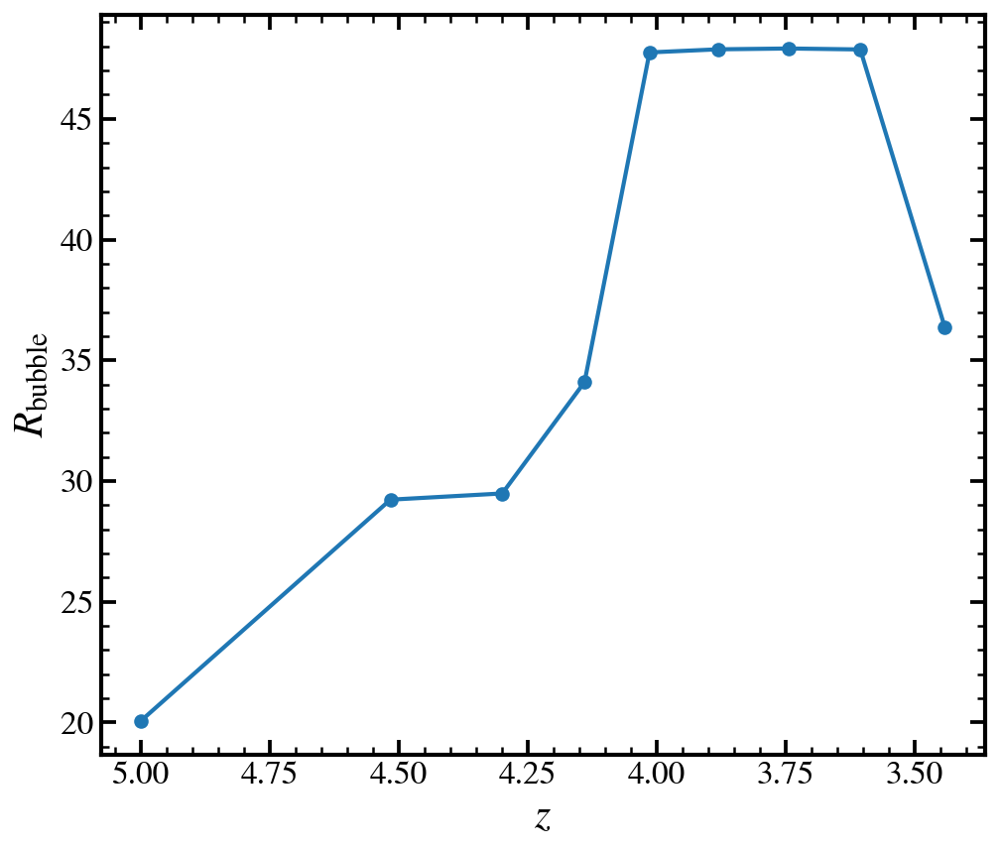

In [4]:

# =========================================================
# MAIN USAGE
# =========================================================

if __name__ == "__main__":

    base_path = "/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK"  # <-- CHANGE THIS

    loader = PowerSpectrumLoader(base_path)
    peak_finder = PeakFinder()
    plotter = PSPlotter()

    # Load all fields
    ps_HII   = loader.load_all(HII)
    ps_Tb_H  = loader.load_all(Tb_H)
    ps_HeIII = loader.load_all(HeIII)
    ps_Tb_He = loader.load_all(Tb_He)

    # =====================================================
    # Example 1: Single plot
    # =====================================================

    fig, ax = plt.subplots(figsize=(7, 6))
    plotter.plot_bubble(ax, ps_HeIII, peak_finder=peak_finder)
    ax.set_xlabel(r"$z$")
    plt.tight_layout()
    plt.show()

## LUMINA (Hydrogen)

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.signal import savgol_filter

# --------------------------------
# Matplotlib style
# --------------------------------

mpl.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 20,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "axes.linewidth": 2.0,
    "xtick.major.width": 1.8,
    "ytick.major.width": 1.8,
    "xtick.minor.width": 1.2,
    "ytick.minor.width": 1.2,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "xtick.minor.size": 4,
    "ytick.minor.size": 4,
    "figure.dpi": 150,
    "savefig.dpi": 300,
})

# --------------------------------
# Load PS function
# --------------------------------

def load_ps(filename, skiprows=5):

    with open(filename) as f:
        lines = f.readlines()
        redshift = float(lines[0])

        # same normalization you used before
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k       = data[:, 0]
    delta2  = data[:, 1]
    nmodes  = data[:, 3]

    # keep exactly same convention
    delta2 *= mean * mean
    k *= 1e3

    mask = nmodes > 0

    return redshift, k[mask], delta2[mask]


# --------------------------------
# HII fraction PS files only
# --------------------------------

files_HII = [
    "./TS_TK/f_HII/PS_177.out",
    "./TS_TK/f_HII/PS_203.out",
    "./TS_TK/f_HII/PS_220.out",
    "./TS_TK/f_HII/PS_242.out",
    "./TS_TK/f_HII/PS_264.out",
    "./TS_TK/f_HII/PS_283.out",
    "./TS_TK/f_HII/PS_300.out",
    "./TS_TK/f_HII/PS_318.out",
    "./TS_TK/f_HII/PS_338.out",
]

# --------------------------------
# Load + sort by redshift
# --------------------------------

ps_HII = [load_ps(f) for f in files_HII]
ps_HII.sort(key=lambda x: x[0], reverse=True)

zs = np.array([x[0] for x in ps_HII])

# --------------------------------
# Colormap
# --------------------------------

cmap = plt.get_cmap("plasma_r")
norm = mpl.colors.Normalize(
    vmin=zs.min(),
    vmax=zs.max()
)

# --------------------------------
# Single panel figure
# --------------------------------

fig, ax = plt.subplots(
    figsize=(7.5, 6)
)

for z, k, delta2 in ps_HII:

    # smooth in log-space
    log_delta = np.log10(delta2)

    smooth_log = savgol_filter(
        log_delta,
        window_length=11,
        polyorder=2
    )

    delta2_smooth = 10**smooth_log

    ax.loglog(
        k,
        delta2_smooth,
        color=cmap(norm(z)),
        lw=2.5,
        alpha=0.9
    )

# --------------------------------
# Axis labels
# --------------------------------

ax.set_xlabel(
    r"$k\ [{\rm h\ cMpc^{-1}}]$"
)

ax.set_ylabel(
    r"$\Delta^2_{x_{\rm HII}}(k)$"
)

# keep same k-range for now
ax.set_xlim(0.02, 10)

ax.set_ylim(5e-5, 2e-1)

# --------------------------------
# Ticks style
# --------------------------------

ax.tick_params(
    which="both",
    direction="in",
    top=True,
    right=True
)

ax.minorticks_on()

# --------------------------------
# Embedded colorbar
# --------------------------------

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

sm = mpl.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)
sm.set_array([])

cax = inset_axes(
    ax,
    width="45%",
    height="4%",
    loc="lower right",
    borderpad=3.0
)

cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal"
)

cbar.set_label(
    r"$z$",
    fontsize=14
)

cbar.ax.tick_params(
    labelsize=11
)

# high-z left, low-z right
cbar.ax.invert_xaxis()

# --------------------------------
# Panel label
# --------------------------------

ax.text(
    0.04,
    0.95,
    r"(a)",
    transform=ax.transAxes,
    fontsize=20,
    ha="left",
    va="top"
)

# --------------------------------
# Optional: peak-finding region guide
# --------------------------------

ax.axvline(
    0.1,
    ls="--",
    lw=1.5,
    alpha=0.7
)

ax.axvline(
    6,
    ls="--",
    lw=1.5,
    alpha=0.7
)

plt.tight_layout()
plt.show()

from scipy.signal import savgol_filter
import numpy as np

# =========================================================
# Robust peak finder
#
# Method:
# 1. Restrict to physical range: 0.1 < k < 6
# 2. Smooth in log-space
# 3. Initial peak guess from argmax
# 4. Local quadratic fit around peak
# 5. Return refined k_peak
#
# This is much more stable than simple argmax()
# =========================================================

def find_kpeak(k, delta2,
               kmin=0.1,
               kmax=6.0,
               window_length=11,
               polyorder=2,
               fit_points=4):
    
    # ---------------------------------
    # Restrict fitting range
    # ---------------------------------
    
    mask = (k > kmin) & (k < kmax)

    k_fit = k[mask]
    d_fit = delta2[mask]

    # safety
    if len(k_fit) < window_length:
        return np.nan, np.nan, np.nan

    # ---------------------------------
    # Smooth in log-space
    # ---------------------------------

    logk = np.log10(k_fit)
    logd = np.log10(d_fit)

    smooth_logd = savgol_filter(
        logd,
        window_length=window_length,
        polyorder=polyorder
    )

    # ---------------------------------
    # Initial peak guess
    # ---------------------------------

    i_peak = np.argmax(smooth_logd)

    # avoid edge failures
    if i_peak < fit_points or i_peak > len(logk) - fit_points - 1:
        return np.nan, np.nan, np.nan

    # ---------------------------------
    # Local quadratic fit
    # ---------------------------------

    sl = slice(i_peak - fit_points, i_peak + fit_points + 1)

    x_local = logk[sl]
    y_local = smooth_logd[sl]

    # y = ax^2 + bx + c
    a, b, c = np.polyfit(x_local, y_local, 2)

    # must be concave downward
    if a >= 0:
        return np.nan, np.nan, np.nan

    # refined peak location
    logk_peak = -b / (2 * a)
    k_peak = 10**logk_peak

    # peak amplitude
    logd_peak = a * logk_peak**2 + b * logk_peak + c
    d_peak = 10**logd_peak

    return k_peak, d_peak, smooth_logd


# =========================================================
# Plot spectra + peak markers
# =========================================================

fig, ax = plt.subplots(figsize=(7.5, 6))

for z, k, delta2 in ps_HII:

    # smooth curve for plotting
    log_delta = np.log10(delta2)

    smooth_log = savgol_filter(
        log_delta,
        window_length=11,
        polyorder=2
    )

    delta2_smooth = 10**smooth_log

    color = cmap(norm(z))

    # ---------------------------------
    # plot spectrum
    # ---------------------------------

    ax.loglog(
        k,
        delta2_smooth,
        color=color,
        lw=2.5,
        alpha=0.9
    )

    # ---------------------------------
    # find peak
    # ---------------------------------

    k_peak, d_peak, _ = find_kpeak(
        k,
        delta2,
        kmin=0.1,
        kmax=6.0
    )

    if np.isfinite(k_peak):

        # peak marker
        ax.scatter(
            k_peak,
            d_peak,
            s=55,
            color=color,
            edgecolor="black",
            linewidth=0.7,
            zorder=10
        )

        print(
            f"z = {z:.2f}   "
            f"k_peak = {k_peak:.3f}   "
            f"Delta2_peak = {d_peak:.4e}"
        )

# =========================================================
# Figure cosmetics
# =========================================================

ax.set_xlabel(
    r"$k\ [{\rm h\ cMpc^{-1}}]$"
)

ax.set_ylabel(
    r"$\Delta^2_{x_{\rm HII}}(k)$"
)

ax.set_xlim(0.02, 10)
ax.set_ylim(5e-5, 2e-1)

ax.tick_params(
    which="both",
    direction="in",
    top=True,
    right=True
)

ax.minorticks_on()

# fitting region guides
ax.axvline(
    0.1,
    ls="--",
    lw=1.5,
    alpha=0.7
)

ax.axvline(
    6.0,
    ls="--",
    lw=1.5,
    alpha=0.7
)

ax.text(
    0.04,
    0.95,
    r"(a)",
    transform=ax.transAxes,
    fontsize=20,
    ha="left",
    va="top"
)

plt.tight_layout()
plt.show()

# =========================================================
# Convert k_peak -> characteristic bubble size
#
# Standard definition:
#
# R_bubble ~ 2π / k_peak
#
# (comoving Mpc / h if k is in h cMpc^-1)
#
# Some papers use π/k instead.
# We start with 2π/k since this is the most common.
# =========================================================

bubble_results = []

for z, k, delta2 in ps_HII:

    k_peak, d_peak, _ = find_kpeak(
        k,
        delta2,
        kmin=0.1,
        kmax=6.0
    )

    if np.isfinite(k_peak):

        R_bubble = 2.5 / k_peak #* np.pi 

        bubble_results.append([
            z,
            k_peak,
            d_peak,
            R_bubble
        ])

# convert to array
bubble_results = np.array(bubble_results)

z_arr       = bubble_results[:, 0]
kpeak_arr   = bubble_results[:, 1]
dpeak_arr   = bubble_results[:, 2]
Rbubble_arr = bubble_results[:, 3]

# =========================================================
# Print results table
# =========================================================

print("\n")
print("===================================================")
print("Characteristic Bubble Size from HII Power Spectrum")
print("===================================================")
print(f"{'z':>8} {'k_peak':>12} {'R_bubble':>15}")
print(f"{'':>8} {'[h cMpc^-1]':>12} {'[cMpc/h]':>15}")
print("---------------------------------------------------")

for z, kp, rb in zip(z_arr, kpeak_arr, Rbubble_arr):

    print(
        f"{z:8.2f}"
        f"{kp:12.3f}"
        f"{rb:15.3f}"
    )

print("===================================================")


# =========================================================
# Plot 1 : k_peak vs redshift
# =========================================================

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    z_arr,
    kpeak_arr,
    marker="o",
    lw=2
)

ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$k_{\rm peak}\ [{\rm h\ cMpc^{-1}}]$")

ax.invert_xaxis()

ax.tick_params(
    which="both",
    direction="in",
    top=True,
    right=True
)

ax.minorticks_on()

plt.tight_layout()
plt.show()


# =========================================================
# Plot 2 : Bubble size vs redshift
# =========================================================

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    z_arr,
    Rbubble_arr,
    marker="o",
    lw=2
)

ax.set_xlabel(r"$z$")
ax.set_ylabel(
    r"$R_{\rm bubble}\ [{\rm cMpc}/h]$"
)

ax.invert_xaxis()

ax.tick_params(
    which="both",
    direction="in",
    top=True,
    right=True
)

ax.minorticks_on()

plt.tight_layout()
plt.show()

# =========================================================
# Save bubble size results to file
# =========================================================

output_file = "PS_bubble_size_HII.dat"

header = (
    "Characteristic bubble size from HII power spectrum\n"
    "Columns:\n"
    "1  z\n"
    "2  k_peak   [h cMpc^-1]\n"
    "3  Delta2_peak\n"
    "4  R_bubble [cMpc/h]   (using R = 2*pi/k_peak)\n"
)

np.savetxt(
    output_file,
    bubble_results,
    fmt="%.6e",
    header=header
)

print(f"Saved to: {output_file}")

FileNotFoundError: [Errno 2] No such file or directory: './TS_TK/f_HII/PS_177.out'

## LUMINA Helium

/tmp/ipykernel_3636889/51767413.py:222: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


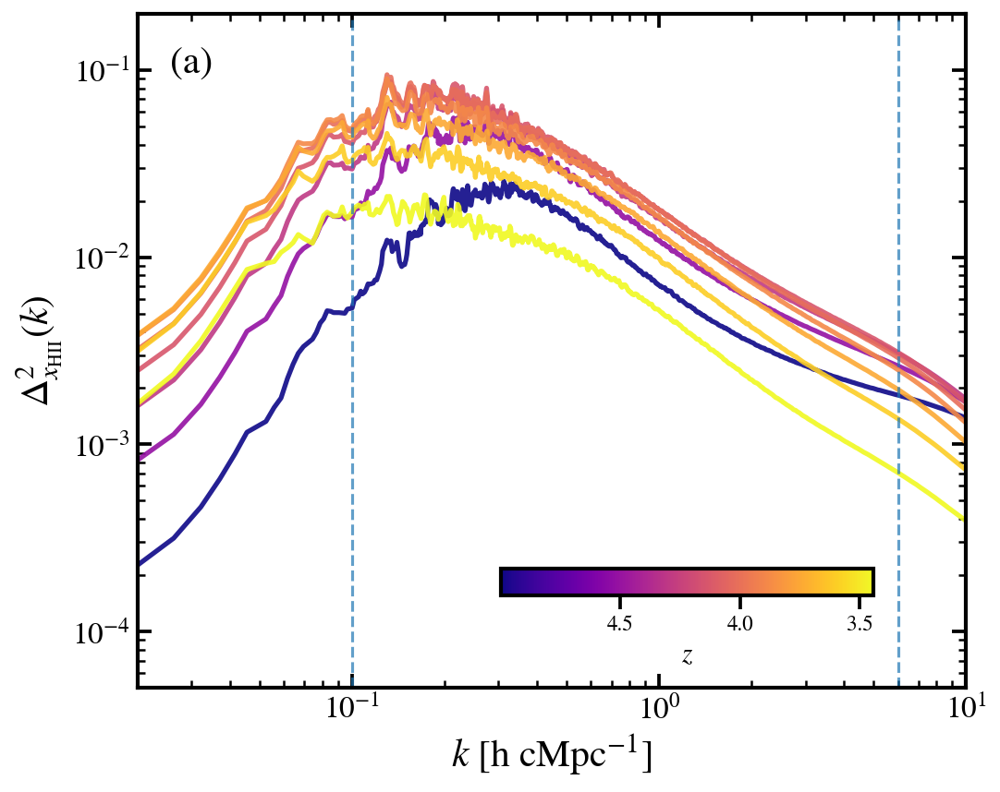

z = 5.00   k_peak = 0.313   Delta2_peak = 2.4932e-02
z = 4.52   k_peak = 0.215   Delta2_peak = 5.5713e-02
z = 4.30   k_peak = 0.213   Delta2_peak = 7.5828e-02
z = 4.14   k_peak = 0.184   Delta2_peak = 8.2887e-02
z = 4.01   k_peak = 0.132   Delta2_peak = 9.1413e-02
z = 3.88   k_peak = 0.131   Delta2_peak = 8.5522e-02
z = 3.74   k_peak = 0.131   Delta2_peak = 6.7469e-02
z = 3.61   k_peak = 0.131   Delta2_peak = 4.3789e-02
z = 3.44   k_peak = 0.173   Delta2_peak = 2.1281e-02


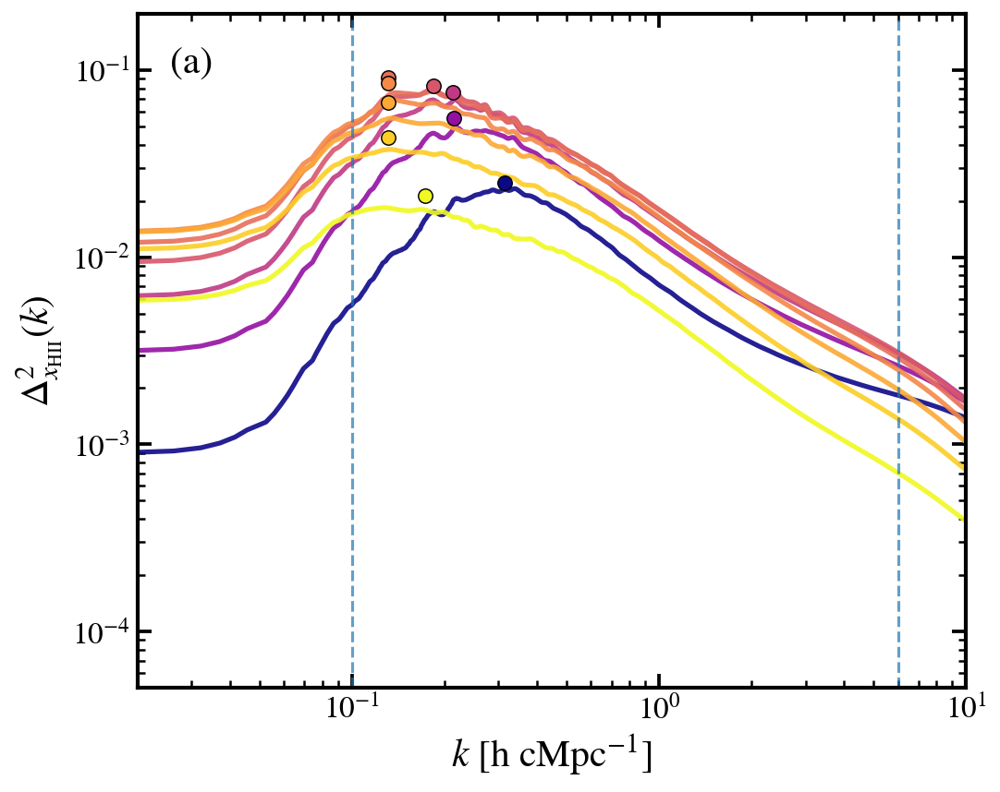



Characteristic Bubble Size from HII Power Spectrum
       z       k_peak        R_bubble
          [h cMpc^-1]        [cMpc/h]
---------------------------------------------------
    5.00       0.313          7.985
    4.52       0.215         11.629
    4.30       0.213         11.731
    4.14       0.184         13.567
    4.01       0.132         19.000
    3.88       0.131         19.051
    3.74       0.131         19.064
    3.61       0.131         19.049
    3.44       0.173         14.465


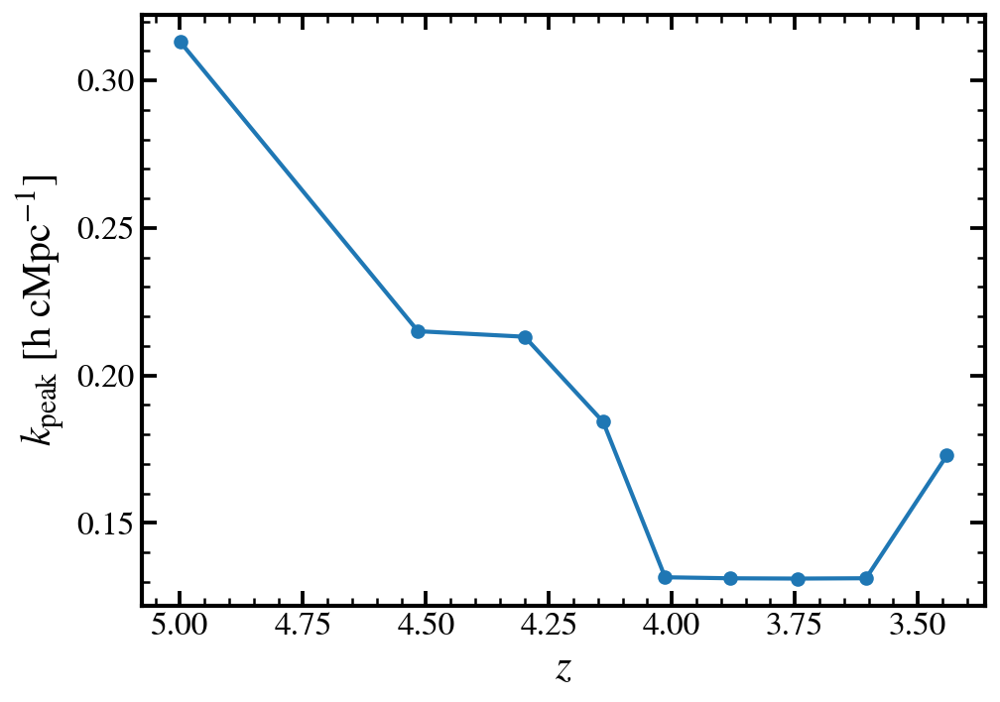

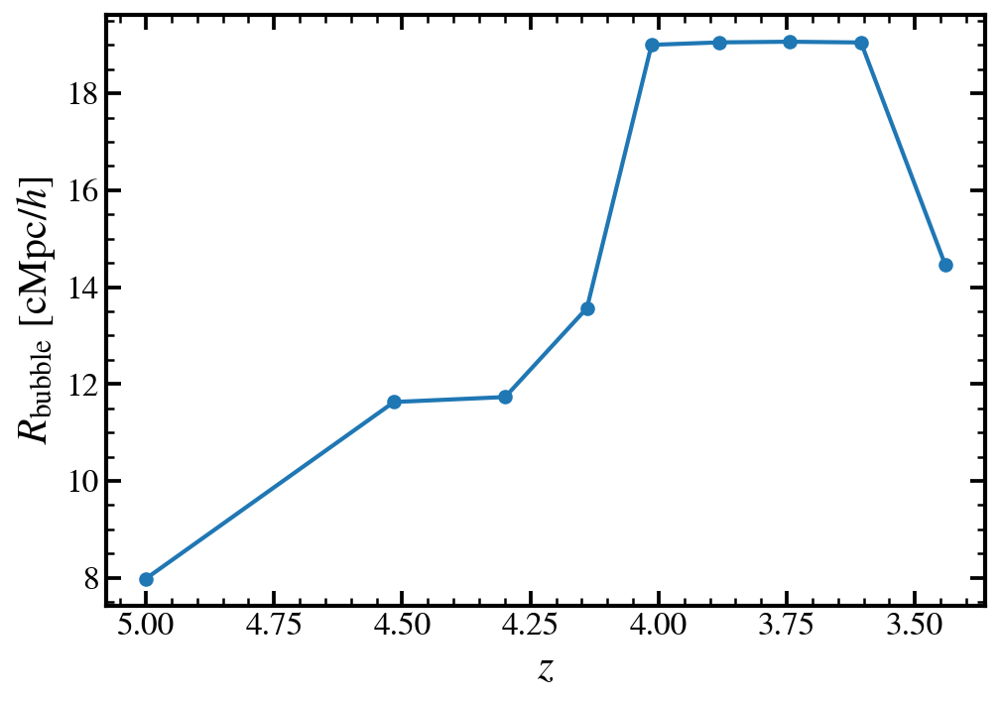

Saved to: PS_bubble_size_HeIII.dat


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.signal import savgol_filter
from scipy.ndimage import gaussian_filter1d

# --------------------------------
# Matplotlib style
# --------------------------------

mpl.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 20,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "axes.linewidth": 2.0,
    "xtick.major.width": 1.8,
    "ytick.major.width": 1.8,
    "xtick.minor.width": 1.2,
    "ytick.minor.width": 1.2,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "xtick.minor.size": 4,
    "ytick.minor.size": 4,
    "figure.dpi": 150,
    "savefig.dpi": 300,
})

# --------------------------------
# Load PS function
# --------------------------------

def load_ps(filename, skiprows=5):

    with open(filename) as f:
        lines = f.readlines()
        redshift = float(lines[0])

        # same normalization you used before
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k       = data[:, 0]
    delta2  = data[:, 1]
    nmodes  = data[:, 3]

    # keep exactly same convention
    delta2 *= mean * mean
    k *= 1e3

    mask = nmodes > 0

    return redshift, k[mask], delta2[mask]


# --------------------------------
# HII fraction PS files only
# --------------------------------

files_HII = [
    "./TS_TK/f_HeIII/PS_406.out",
    "./TS_TK/f_HeIII/PS_450.out",
    "./TS_TK/f_HeIII/PS_471.out",
    "./TS_TK/f_HeIII/PS_487.out",
    "./TS_TK/f_HeIII/PS_500.out",
    "./TS_TK/f_HeIII/PS_514.out",
    "./TS_TK/f_HeIII/PS_529.out",
    "./TS_TK/f_HeIII/PS_558.out",
    "./TS_TK/f_HeIII/PS_596.out",
]

# --------------------------------
# Load + sort by redshift
# --------------------------------

ps_HII = [load_ps(f) for f in files_HII]
ps_HII.sort(key=lambda x: x[0], reverse=True)

zs = np.array([x[0] for x in ps_HII])

# --------------------------------
# Colormap
# --------------------------------

cmap = plt.get_cmap("plasma_r")
norm = mpl.colors.Normalize(
    vmin=zs.min(),
    vmax=zs.max()
)

# --------------------------------
# Single panel figure
# --------------------------------

fig, ax = plt.subplots(
    figsize=(7.5, 6)
)

for z, k, delta2 in ps_HII:

    # smooth in log-space
    log_delta = np.log10(delta2)

    smooth_log = savgol_filter(
        log_delta,
        window_length=11,
        polyorder=2
    )

    delta2_smooth = 10**smooth_log

    ax.loglog(
        k,
        delta2_smooth,
        color=cmap(norm(z)),
        lw=2.5,
        alpha=0.9
    )

# --------------------------------
# Axis labels
# --------------------------------

ax.set_xlabel(
    r"$k\ [{\rm h\ cMpc^{-1}}]$"
)

ax.set_ylabel(
    r"$\Delta^2_{x_{\rm HII}}(k)$"
)

# keep same k-range for now
ax.set_xlim(0.02, 10)

ax.set_ylim(5e-5, 2e-1)

# --------------------------------
# Ticks style
# --------------------------------

ax.tick_params(
    which="both",
    direction="in",
    top=True,
    right=True
)

ax.minorticks_on()

# --------------------------------
# Embedded colorbar
# --------------------------------

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

sm = mpl.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)
sm.set_array([])

cax = inset_axes(
    ax,
    width="45%",
    height="4%",
    loc="lower right",
    borderpad=3.0
)

cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal"
)

cbar.set_label(
    r"$z$",
    fontsize=14
)

cbar.ax.tick_params(
    labelsize=11
)

# high-z left, low-z right
cbar.ax.invert_xaxis()

# --------------------------------
# Panel label
# --------------------------------

ax.text(
    0.04,
    0.95,
    r"(a)",
    transform=ax.transAxes,
    fontsize=20,
    ha="left",
    va="top"
)

# --------------------------------
# Optional: peak-finding region guide
# --------------------------------

ax.axvline(
    0.1,
    ls="--",
    lw=1.5,
    alpha=0.7
)

ax.axvline(
    6,
    ls="--",
    lw=1.5,
    alpha=0.7
)

plt.tight_layout()
plt.show()

from scipy.signal import savgol_filter
import numpy as np

# =========================================================
# Robust peak finder
#
# Method:
# 1. Restrict to physical range: 0.1 < k < 6
# 2. Smooth in log-space
# 3. Initial peak guess from argmax
# 4. Local quadratic fit around peak
# 5. Return refined k_peak
#
# This is much more stable than simple argmax()
# =========================================================

def find_kpeak(k, delta2,
               kmin=0.1,
               kmax=6.0,
               window_length=11,
               polyorder=2,
               fit_points=4):
    
    # ---------------------------------
    # Restrict fitting range
    # ---------------------------------
    
    mask = (k > kmin) & (k < kmax)

    k_fit = k[mask]
    d_fit = delta2[mask]

    # safety
    if len(k_fit) < window_length:
        return np.nan, np.nan, np.nan

    # ---------------------------------
    # Smooth in log-space
    # ---------------------------------

    logk = np.log10(k_fit)
    logd = np.log10(d_fit)

    smooth_logd = savgol_filter(
        logd,
        window_length=window_length,
        polyorder=polyorder
    )

    # ---------------------------------
    # Initial peak guess
    # ---------------------------------

    i_peak = np.argmax(smooth_logd)

    # avoid edge failures
    if i_peak < fit_points or i_peak > len(logk) - fit_points - 1:
        return np.nan, np.nan, np.nan

    # ---------------------------------
    # Local quadratic fit
    # ---------------------------------

    sl = slice(i_peak - fit_points, i_peak + fit_points + 1)

    x_local = logk[sl]
    y_local = smooth_logd[sl]

    # y = ax^2 + bx + c
    a, b, c = np.polyfit(x_local, y_local, 2)

    # must be concave downward
    if a >= 0:
        return np.nan, np.nan, np.nan

    # refined peak location
    logk_peak = -b / (2 * a)
    k_peak = 10**logk_peak

    # peak amplitude
    logd_peak = a * logk_peak**2 + b * logk_peak + c
    d_peak = 10**logd_peak

    return k_peak, d_peak, smooth_logd


# =========================================================
# Plot spectra + peak markers
# =========================================================

fig, ax = plt.subplots(figsize=(7.5, 6))

for z, k, delta2 in ps_HII:

    # smooth curve for plotting
    log_delta = np.log10(delta2)

    #smooth_log = savgol_filter(
    #    log_delta,
    #    window_length=11,
    #    polyorder=2
    #)
    
    smooth_log = gaussian_filter1d(
        log_delta,
        sigma=7
    )

    delta2_smooth = 10**smooth_log

    color = cmap(norm(z))

    # ---------------------------------
    # plot spectrum
    # ---------------------------------

    ax.loglog(
        k,
        delta2_smooth,
        color=color,
        lw=2.5,
        alpha=0.9
    )

    # ---------------------------------
    # find peak
    # ---------------------------------

    k_peak, d_peak, _ = find_kpeak(
        k,
        delta2,
        kmin=0.1,
        kmax=6.0
    )

    if np.isfinite(k_peak):

        # peak marker
        ax.scatter(
            k_peak,
            d_peak,
            s=55,
            color=color,
            edgecolor="black",
            linewidth=0.7,
            zorder=10
        )

        print(
            f"z = {z:.2f}   "
            f"k_peak = {k_peak:.3f}   "
            f"Delta2_peak = {d_peak:.4e}"
        )

# =========================================================
# Figure cosmetics
# =========================================================

ax.set_xlabel(
    r"$k\ [{\rm h\ cMpc^{-1}}]$"
)

ax.set_ylabel(
    r"$\Delta^2_{x_{\rm HII}}(k)$"
)

ax.set_xlim(0.02, 10)
ax.set_ylim(5e-5, 2e-1)

ax.tick_params(
    which="both",
    direction="in",
    top=True,
    right=True
)

ax.minorticks_on()

# fitting region guides
ax.axvline(
    0.1,
    ls="--",
    lw=1.5,
    alpha=0.7
)

ax.axvline(
    6.0,
    ls="--",
    lw=1.5,
    alpha=0.7
)

ax.text(
    0.04,
    0.95,
    r"(a)",
    transform=ax.transAxes,
    fontsize=20,
    ha="left",
    va="top"
)

plt.tight_layout()
plt.show()

# =========================================================
# Convert k_peak -> characteristic bubble size
#
# Standard definition:
#
# R_bubble ~ 2π / k_peak
#
# (comoving Mpc / h if k is in h cMpc^-1)
#
# Some papers use π/k instead.
# We start with 2π/k since this is the most common.
# =========================================================

bubble_results = []

for z, k, delta2 in ps_HII:

    k_peak, d_peak, _ = find_kpeak(
        k,
        delta2,
        kmin=0.1,
        kmax=6.0
    )

    if np.isfinite(k_peak):

        R_bubble = 2.5  / k_peak #* np.pi

        bubble_results.append([
            z,
            k_peak,
            d_peak,
            R_bubble
        ])

# convert to array
bubble_results = np.array(bubble_results)

z_arr       = bubble_results[:, 0]
kpeak_arr   = bubble_results[:, 1]
dpeak_arr   = bubble_results[:, 2]
Rbubble_arr = bubble_results[:, 3]

# =========================================================
# Print results table
# =========================================================

print("\n")
print("===================================================")
print("Characteristic Bubble Size from HII Power Spectrum")
print("===================================================")
print(f"{'z':>8} {'k_peak':>12} {'R_bubble':>15}")
print(f"{'':>8} {'[h cMpc^-1]':>12} {'[cMpc/h]':>15}")
print("---------------------------------------------------")

for z, kp, rb in zip(z_arr, kpeak_arr, Rbubble_arr):

    print(
        f"{z:8.2f}"
        f"{kp:12.3f}"
        f"{rb:15.3f}"
    )

print("===================================================")


# =========================================================
# Plot 1 : k_peak vs redshift
# =========================================================

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    z_arr,
    kpeak_arr,
    marker="o",
    lw=2
)

ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$k_{\rm peak}\ [{\rm h\ cMpc^{-1}}]$")

ax.invert_xaxis()

ax.tick_params(
    which="both",
    direction="in",
    top=True,
    right=True
)

ax.minorticks_on()

plt.tight_layout()
plt.show()


# =========================================================
# Plot 2 : Bubble size vs redshift
# =========================================================

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    z_arr,
    Rbubble_arr,
    marker="o",
    lw=2
)

ax.set_xlabel(r"$z$")
ax.set_ylabel(
    r"$R_{\rm bubble}\ [{\rm cMpc}/h]$"
)

ax.invert_xaxis()

ax.tick_params(
    which="both",
    direction="in",
    top=True,
    right=True
)

ax.minorticks_on()

plt.tight_layout()
plt.show()

# =========================================================
# Save bubble size results to file
# =========================================================

output_file = "PS_bubble_size_HeIII.dat"

header = (
    "Characteristic bubble size from HeIII power spectrum\n"
    "Columns:\n"
    "1  z\n"
    "2  k_peak   [h cMpc^-1]\n"
    "3  Delta2_peak\n"
    "4  R_bubble [cMpc/h]   (using R = 2*pi/k_peak)\n"
)

np.savetxt(
    output_file,
    bubble_results,
    fmt="%.6e",
    header=header
)

print(f"Saved to: {output_file}")

---

# Updated plots

z = 9.16   k_peak = 2.469 h/cMpc   R_bubble = 1.01 cMpc/h   Delta2_peak = 3.0393e-02
z = 8.20   k_peak = 1.911 h/cMpc   R_bubble = 1.31 cMpc/h   Delta2_peak = 4.5567e-02
z = 7.63   k_peak = 1.319 h/cMpc   R_bubble = 1.90 cMpc/h   Delta2_peak = 5.3706e-02
z = 7.21   k_peak = 0.698 h/cMpc   R_bubble = 3.58 cMpc/h   Delta2_peak = 5.8697e-02
z = 6.87   k_peak = 0.535 h/cMpc   R_bubble = 4.67 cMpc/h   Delta2_peak = 6.0236e-02
z = 6.59   k_peak = 0.411 h/cMpc   R_bubble = 6.08 cMpc/h   Delta2_peak = 5.7040e-02
z = 6.35   k_peak = 0.314 h/cMpc   R_bubble = 7.97 cMpc/h   Delta2_peak = 4.9998e-02
z = 6.10   k_peak = 0.285 h/cMpc   R_bubble = 8.77 cMpc/h   Delta2_peak = 3.8301e-02
z = 5.83   k_peak = 0.285 h/cMpc   R_bubble = 8.78 cMpc/h   Delta2_peak = 2.2310e-02


/tmp/ipykernel_50160/2393701208.py:288: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


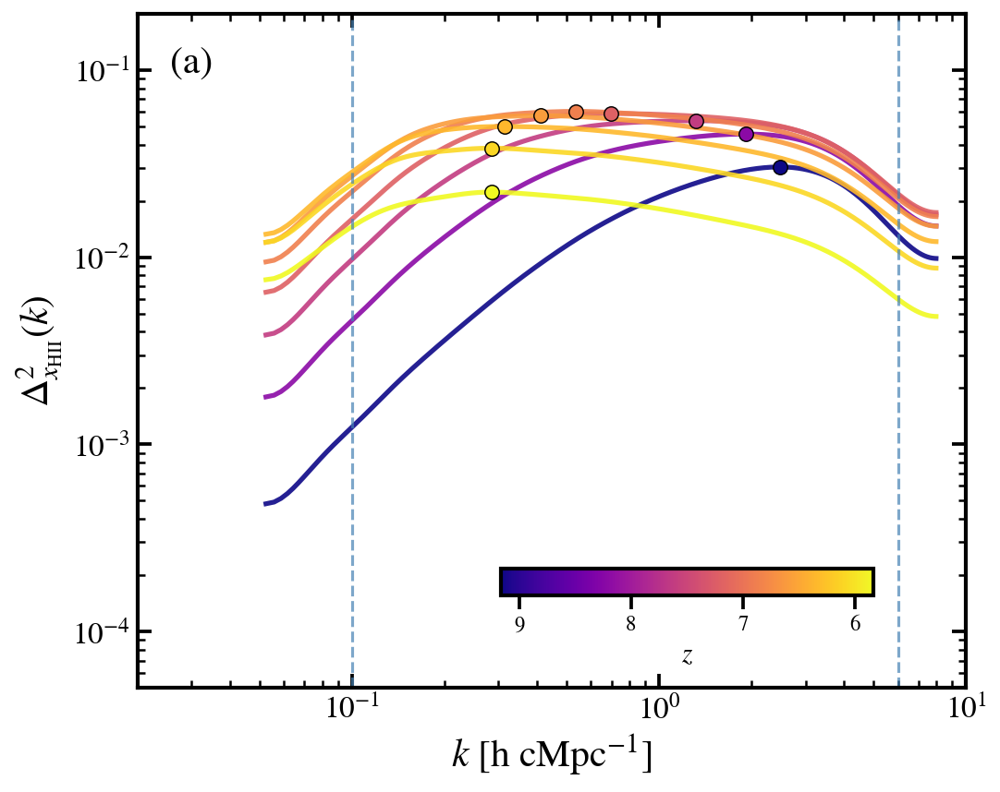


Characteristic Bubble Size from HII Power Spectrum
       z        k_peak         R_bubble
              [h/cMpc]         [cMpc/h]
---------------------------------------------------------
    9.16        2.4694            1.012
    8.20        1.9110            1.308
    7.63        1.3192            1.895
    7.21        0.6982            3.581
    6.87        0.5349            4.674
    6.59        0.4109            6.085
    6.35        0.3138            7.967
    6.10        0.2851            8.770
    5.83        0.2847            8.782


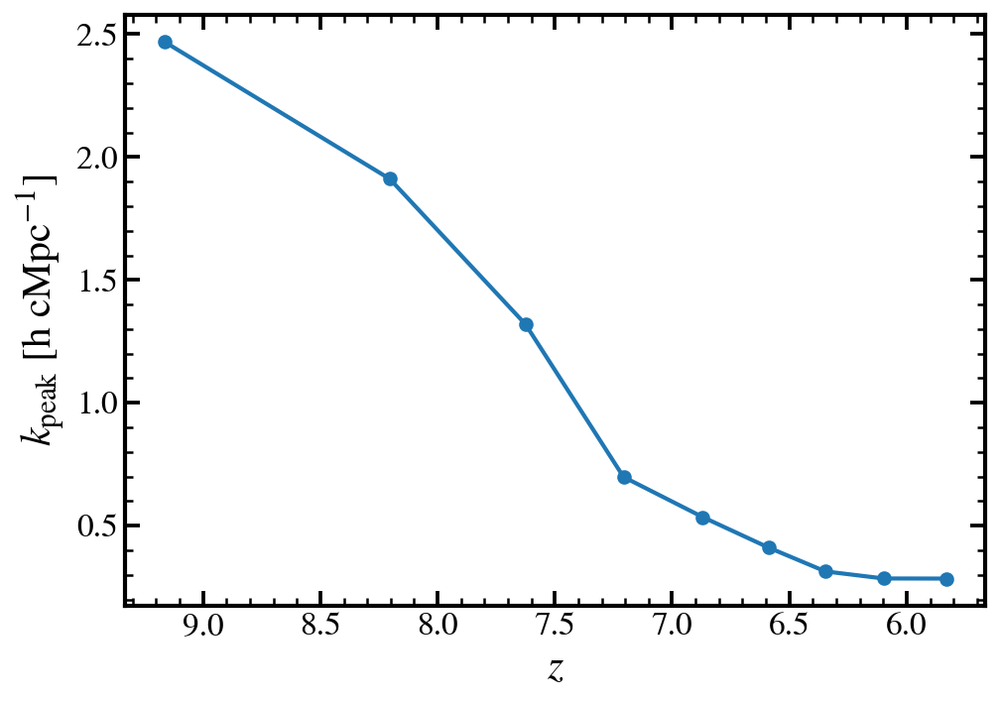

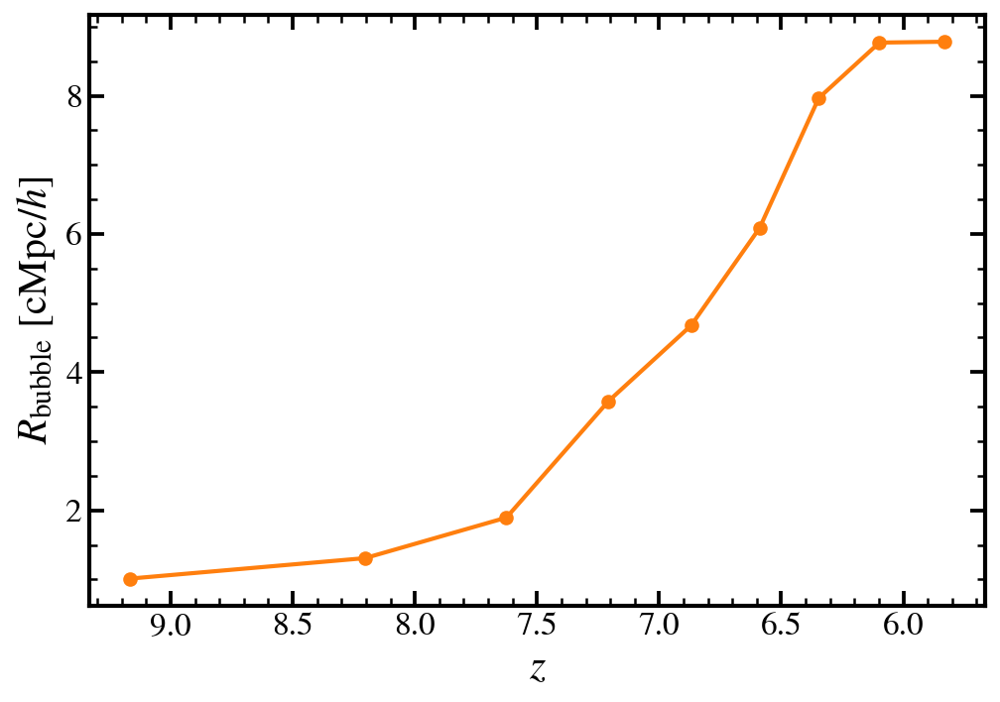


Saved to: PS_bubble_size_HII.dat


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.ndimage import gaussian_filter1d
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ================================
# Matplotlib style
# ================================

mpl.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 20,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "axes.linewidth": 2.0,
    "xtick.major.width": 1.8,
    "ytick.major.width": 1.8,
    "xtick.minor.width": 1.2,
    "ytick.minor.width": 1.2,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "xtick.minor.size": 4,
    "ytick.minor.size": 4,
    "figure.dpi": 150,
    "savefig.dpi": 300,
})

# ================================
# Load PS function
# ================================

def load_ps(filename, skiprows=5):

    with open(filename) as f:
        lines = f.readlines()
        redshift = float(lines[0])
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k      = data[:, 0]
    delta2 = data[:, 1]
    nmodes = data[:, 3]

    delta2 *= mean * mean
    k      *= 1e3

    mask = nmodes > 0

    return redshift, k[mask], delta2[mask]


# ================================
# Robust peak finder
#
# Key improvements over previous version:
#
# 1. Re-grids onto a uniform log10(k) axis before smoothing,
#    so the Gaussian sigma is in physical dex units — consistent
#    across all spectra regardless of k-grid density.
#
# 2. Uses a SINGLE smooth shared between plotting and peak finding.
#    The old code smoothed differently for plotting vs. peak finding,
#    which caused markers to float off the curves.
#
# 3. Returns the smoothed delta2 array so the caller can plot
#    directly from it — no second smoothing step needed.
#
# 4. Wider quadratic fit window (fit_points=7) for more stability.
# ================================

def find_kpeak(k, delta2,
               kmin=0.05,
               kmax=8.0,
               sigma_dex=0.08,
               n_grid=640, #512
               fit_points=7):
    """
    Parameters
    ----------
    k, delta2   : raw arrays from load_ps
    kmin, kmax  : fitting/smoothing range (slightly wider than plot range)
    sigma_dex   : Gaussian smoothing width in log10(k) [dex]
    n_grid      : number of uniform log10(k) grid points
    fit_points  : half-width of quadratic fit window around peak

    Returns
    -------
    k_peak        : peak wavenumber [h cMpc^-1]
    d_peak        : power spectrum value at peak (on smoothed curve)
    delta2_smooth : smoothed delta2 on the ORIGINAL k grid (for plotting)
                    returns None on failure
    """

    mask   = (k > kmin) & (k < kmax)
    k_fit  = k[mask]
    d_fit  = delta2[mask]

    if len(k_fit) < 20:
        return np.nan, np.nan, None

    # ---- uniform log10(k) grid ----
    logk_uni = np.linspace(
        np.log10(k_fit[0]),
        np.log10(k_fit[-1]),
        n_grid
    )

    # interpolate log10(delta2) onto uniform grid
    logd_uni = np.interp(
        logk_uni,
        np.log10(k_fit),
        np.log10(d_fit)
    )

    # ---- Gaussian smooth: sigma in dex -> sigma in grid units ----
    dlogk       = logk_uni[1] - logk_uni[0]
    sigma_grid  = sigma_dex / dlogk

    logd_smooth = gaussian_filter1d(logd_uni, sigma=sigma_grid)

    # ---- initial peak from argmax ----
    i_peak = np.argmax(logd_smooth)

    if i_peak < fit_points or i_peak > len(logk_uni) - fit_points - 1:
        return np.nan, np.nan, None

    # ---- quadratic refinement in log-log space ----
    sl    = slice(i_peak - fit_points, i_peak + fit_points + 1)
    x_loc = logk_uni[sl]
    y_loc = logd_smooth[sl]

    a, b, c = np.polyfit(x_loc, y_loc, 2)

    # must be concave downward
    if a >= 0:
        return np.nan, np.nan, None

    logk_peak = -b / (2.0 * a)
    logd_peak =  a * logk_peak**2 + b * logk_peak + c

    # ---- map smoothed curve back to original k grid ----
    logd_smooth_orig = np.interp(
        np.log10(k_fit),
        logk_uni,
        logd_smooth
    )

    # build full-length array (NaN outside fitting range)
    delta2_smooth_full = np.full_like(delta2, np.nan)
    delta2_smooth_full[mask] = 10**logd_smooth_orig

    return 10**logk_peak, 10**logd_peak, delta2_smooth_full


# ================================
# HII fraction PS files
# ================================
DIR = "/orcd/data/mvogelsb/004/chcho/cell_by_cell/hydrogen/f_HII"
files_HII = [
    f"{DIR}/PS_177.out",
    f"{DIR}/PS_203.out",
    f"{DIR}/PS_220.out",
    f"{DIR}/PS_242.out",
    f"{DIR}/PS_264.out",
    f"{DIR}/PS_283.out",
    f"{DIR}/PS_300.out",
    f"{DIR}/PS_318.out",
    f"{DIR}/PS_338.out",
]

# ================================
# Load + sort by redshift (high -> low)
# ================================

ps_HII = [load_ps(f) for f in files_HII]
ps_HII.sort(key=lambda x: x[0], reverse=True)

zs = np.array([x[0] for x in ps_HII])

# ================================
# Colormap
# ================================

cmap = plt.get_cmap("plasma_r")
norm = mpl.colors.Normalize(vmin=zs.min(), vmax=zs.max())

# ================================
# Figure: power spectra + peak markers
# ================================

fig, ax = plt.subplots(figsize=(7.5, 6))

bubble_results = []

for z, k, delta2 in ps_HII:

    color = cmap(norm(z))

    # --- find peak; get back the SAME smoothed curve used for peak finding ---
    k_peak, d_peak, delta2_smooth = find_kpeak(
        k, delta2,
        kmin=0.05,
        kmax=8.0,
        sigma_dex=0.08,   # 0.08 dex ~ mild smoothing; increase if still noisy
        fit_points=7
    )

    # --- plot the smoothed curve (consistent with peak marker) ---
    plot_mask = (k > 0.02) & (k < 10.0) & np.isfinite(delta2_smooth)

    ax.loglog(
        k[plot_mask],
        delta2_smooth[plot_mask],
        color=color,
        lw=2.5,
        alpha=0.9
    )

    # --- peak marker sits exactly on the plotted curve ---
    if np.isfinite(k_peak):

        ax.scatter(
            k_peak, d_peak,
            s=55,
            color=color,
            edgecolor="black",
            linewidth=0.7,
            zorder=10
        )

        R_bubble = 2.5 / k_peak #* np.pi 

        bubble_results.append([z, k_peak, d_peak, R_bubble])

        print(
            f"z = {z:.2f}   "
            f"k_peak = {k_peak:.3f} h/cMpc   "
            f"R_bubble = {R_bubble:.2f} cMpc/h   "
            f"Delta2_peak = {d_peak:.4e}"
        )

# ================================
# Axis formatting
# ================================

ax.set_xlabel(r"$k\ [{\rm h\ cMpc^{-1}}]$")
ax.set_ylabel(r"$\Delta^2_{x_{\rm HII}}(k)$")

ax.set_xlim(0.02, 10)
ax.set_ylim(5e-5, 2e-1)

ax.tick_params(which="both", direction="in", top=True, right=True)
ax.minorticks_on()

# fitting region guides
ax.axvline(0.1, ls="--", lw=1.5, alpha=0.7, color="steelblue")
ax.axvline(6.0, ls="--", lw=1.5, alpha=0.7, color="steelblue")

# panel label
ax.text(
    0.04, 0.95, r"(a)",
    transform=ax.transAxes,
    fontsize=20, ha="left", va="top"
)

# ================================
# Embedded colorbar
# ================================

sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cax = inset_axes(
    ax,
    width="45%", height="4%",
    loc="lower right",
    borderpad=3.0
)

cbar = fig.colorbar(sm, cax=cax, orientation="horizontal")
cbar.set_label(r"$z$", fontsize=14)
cbar.ax.tick_params(labelsize=11)
cbar.ax.invert_xaxis()   # high-z left, low-z right

plt.tight_layout()
plt.savefig("PS_HII_peaks.pdf", bbox_inches="tight")
plt.show()

# ================================
# Results table
# ================================

bubble_results = np.array(bubble_results)
z_arr       = bubble_results[:, 0]
kpeak_arr   = bubble_results[:, 1]
dpeak_arr   = bubble_results[:, 2]
Rbubble_arr = bubble_results[:, 3]

print()
print("=" * 57)
print("Characteristic Bubble Size from HII Power Spectrum")
print("=" * 57)
print(f"{'z':>8}  {'k_peak':>12}  {'R_bubble':>15}")
print(f"{'':>8}  {'[h/cMpc]':>12}  {'[cMpc/h]':>15}")
print("-" * 57)

for z, kp, rb in zip(z_arr, kpeak_arr, Rbubble_arr):
    print(f"{z:8.2f}  {kp:12.4f}  {rb:15.3f}")

print("=" * 57)

# ================================
# Plot 1: k_peak vs redshift
# ================================

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(z_arr, kpeak_arr, marker="o", lw=2, color="tab:blue")
ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$k_{\rm peak}\ [{\rm h\ cMpc^{-1}}]$")
ax.invert_xaxis()
ax.tick_params(which="both", direction="in", top=True, right=True)
ax.minorticks_on()
plt.tight_layout()
plt.savefig("kpeak_vs_z.pdf", bbox_inches="tight")
plt.show()

# ================================
# Plot 2: Bubble size vs redshift
# ================================

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(z_arr, Rbubble_arr, marker="o", lw=2, color="tab:orange")
ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$R_{\rm bubble}\ [{\rm cMpc}/h]$")
ax.invert_xaxis()
ax.tick_params(which="both", direction="in", top=True, right=True)
ax.minorticks_on()
plt.tight_layout()
plt.savefig("Rbubble_vs_z.pdf", bbox_inches="tight")
plt.show()

# ================================
# Save results to file
# ================================

output_file = "PS_bubble_size_HII.dat"

header = (
    "Characteristic bubble size from HII power spectrum\n"
    "Columns:\n"
    "1  z\n"
    "2  k_peak      [h cMpc^-1]\n"
    "3  Delta2_peak\n"
    "4  R_bubble    [cMpc/h]   (R = 2*pi/k_peak)\n"
)

np.savetxt(output_file, bubble_results, fmt="%.6e", header=header)
print(f"\nSaved to: {output_file}")

z = 5.00   k_peak = 0.314 h/cMpc   R_bubble = 7.97 cMpc/h   Delta2_peak = 2.1623e-02
z = 4.52   k_peak = 0.238 h/cMpc   R_bubble = 10.49 cMpc/h   Delta2_peak = 4.5307e-02
z = 4.30   k_peak = 0.204 h/cMpc   R_bubble = 12.27 cMpc/h   Delta2_peak = 6.3939e-02
z = 4.14   k_peak = 0.183 h/cMpc   R_bubble = 13.67 cMpc/h   Delta2_peak = 7.2836e-02
z = 4.01   k_peak = 0.169 h/cMpc   R_bubble = 14.82 cMpc/h   Delta2_peak = 7.2903e-02
z = 3.88   k_peak = 0.156 h/cMpc   R_bubble = 15.99 cMpc/h   Delta2_peak = 6.5281e-02
z = 3.74   k_peak = 0.148 h/cMpc   R_bubble = 16.86 cMpc/h   Delta2_peak = 5.2476e-02
z = 3.61   k_peak = 0.144 h/cMpc   R_bubble = 17.33 cMpc/h   Delta2_peak = 3.6500e-02
z = 3.44   k_peak = 0.134 h/cMpc   R_bubble = 18.73 cMpc/h   Delta2_peak = 1.7971e-02


/tmp/ipykernel_50160/2413722640.py:288: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


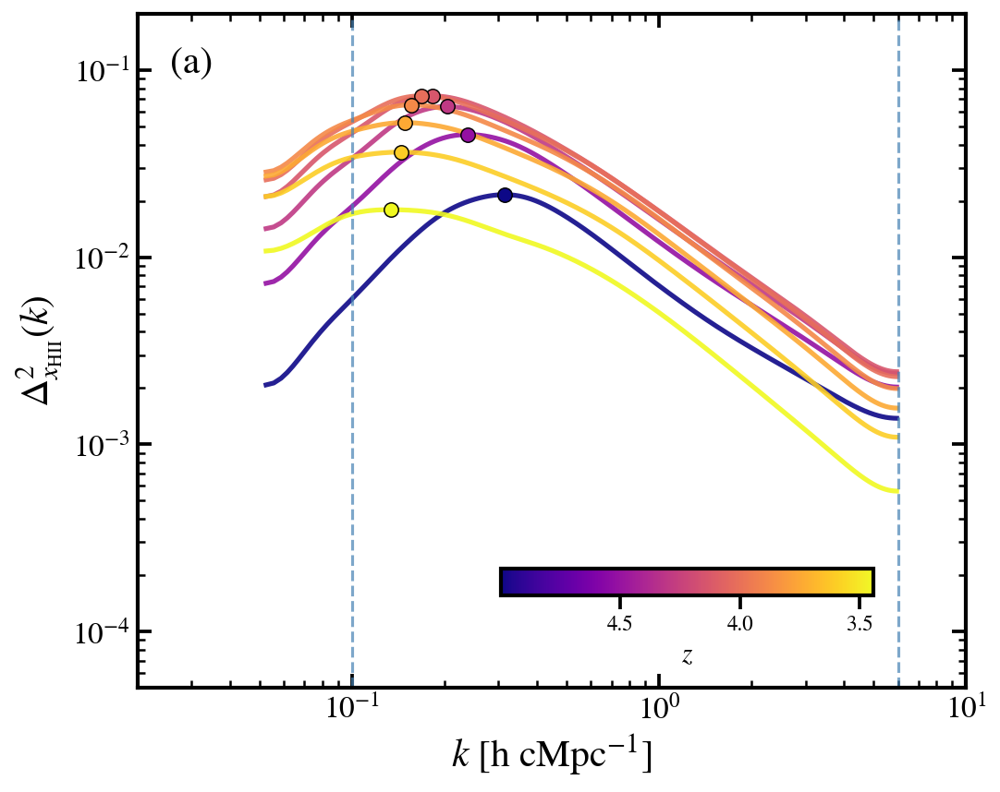


Characteristic Bubble Size from HII Power Spectrum
       z        k_peak         R_bubble
              [h/cMpc]         [cMpc/h]
---------------------------------------------------------
    5.00        0.3138            7.967
    4.52        0.2384           10.485
    4.30        0.2037           12.271
    4.14        0.1829           13.666
    4.01        0.1687           14.816
    3.88        0.1564           15.988
    3.74        0.1483           16.860
    3.61        0.1442           17.334
    3.44        0.1335           18.726


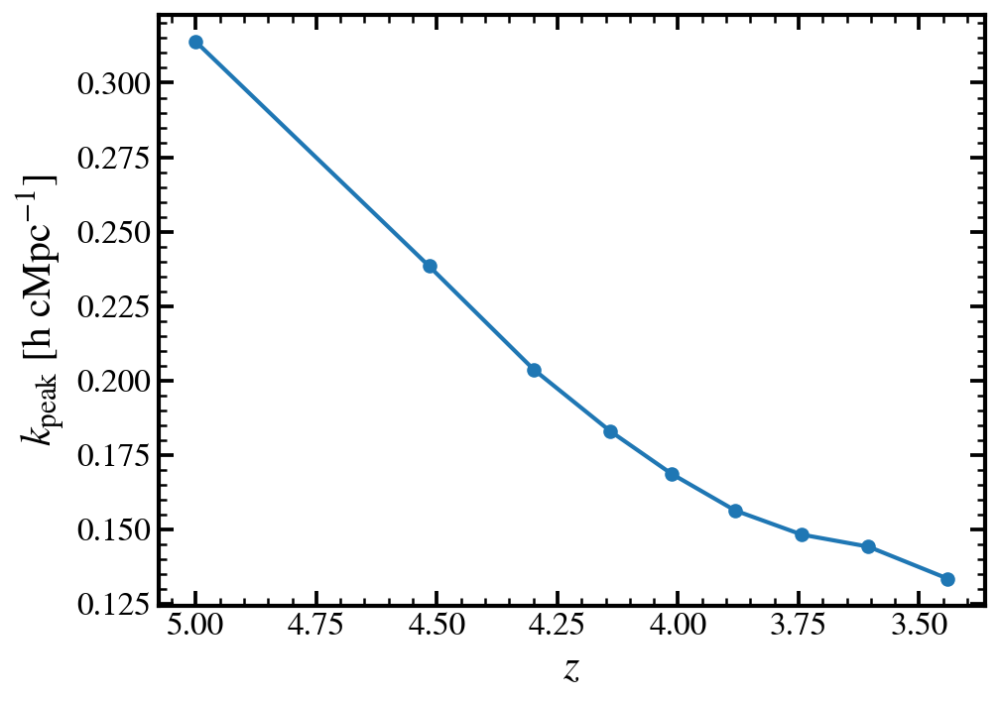

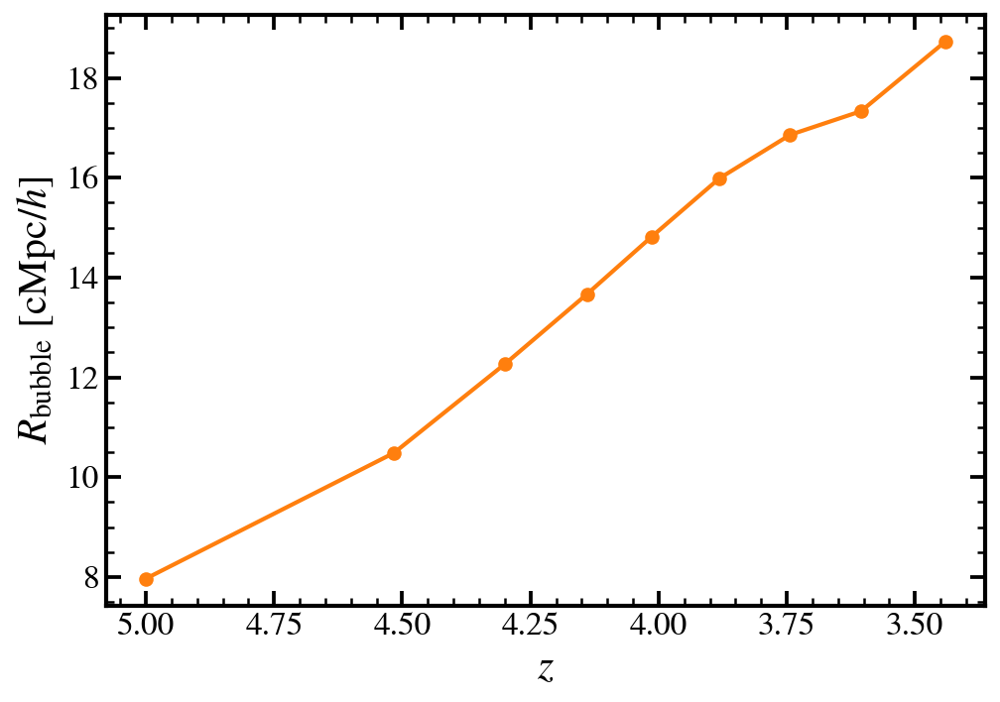


Saved to: PS_bubble_size_HeIII.dat


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.ndimage import gaussian_filter1d
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ================================
# Matplotlib style
# ================================

mpl.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 20,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "axes.linewidth": 2.0,
    "xtick.major.width": 1.8,
    "ytick.major.width": 1.8,
    "xtick.minor.width": 1.2,
    "ytick.minor.width": 1.2,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "xtick.minor.size": 4,
    "ytick.minor.size": 4,
    "figure.dpi": 150,
    "savefig.dpi": 300,
})

# ================================
# Load PS function
# ================================

def load_ps(filename, skiprows=5):

    with open(filename) as f:
        lines = f.readlines()
        redshift = float(lines[0])
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k      = data[:, 0]
    delta2 = data[:, 1]
    nmodes = data[:, 3]

    delta2 *= mean * mean
    k      *= 1e3

    mask = nmodes > 0

    return redshift, k[mask], delta2[mask]


# ================================
# Robust peak finder
#
# Key improvements over previous version:
#
# 1. Re-grids onto a uniform log10(k) axis before smoothing,
#    so the Gaussian sigma is in physical dex units — consistent
#    across all spectra regardless of k-grid density.
#
# 2. Uses a SINGLE smooth shared between plotting and peak finding.
#    The old code smoothed differently for plotting vs. peak finding,
#    which caused markers to float off the curves.
#
# 3. Returns the smoothed delta2 array so the caller can plot
#    directly from it — no second smoothing step needed.
#
# 4. Wider quadratic fit window (fit_points=7) for more stability.
# ================================

def find_kpeak(k, delta2,
               kmin=0.05,
               kmax=8.0,
               sigma_dex=0.08,
               n_grid=640, #512
               fit_points=7):
    """
    Parameters
    ----------
    k, delta2   : raw arrays from load_ps
    kmin, kmax  : fitting/smoothing range (slightly wider than plot range)
    sigma_dex   : Gaussian smoothing width in log10(k) [dex]
    n_grid      : number of uniform log10(k) grid points
    fit_points  : half-width of quadratic fit window around peak

    Returns
    -------
    k_peak        : peak wavenumber [h cMpc^-1]
    d_peak        : power spectrum value at peak (on smoothed curve)
    delta2_smooth : smoothed delta2 on the ORIGINAL k grid (for plotting)
                    returns None on failure
    """

    mask   = (k > kmin) & (k < kmax)
    k_fit  = k[mask]
    d_fit  = delta2[mask]

    if len(k_fit) < 20:
        return np.nan, np.nan, None

    # ---- uniform log10(k) grid ----
    logk_uni = np.linspace(
        np.log10(k_fit[0]),
        np.log10(k_fit[-1]),
        n_grid
    )

    # interpolate log10(delta2) onto uniform grid
    logd_uni = np.interp(
        logk_uni,
        np.log10(k_fit),
        np.log10(d_fit)
    )

    # ---- Gaussian smooth: sigma in dex -> sigma in grid units ----
    dlogk       = logk_uni[1] - logk_uni[0]
    sigma_grid  = sigma_dex / dlogk

    logd_smooth = gaussian_filter1d(logd_uni, sigma=sigma_grid)

    # ---- initial peak from argmax ----
    i_peak = np.argmax(logd_smooth)

    if i_peak < fit_points or i_peak > len(logk_uni) - fit_points - 1:
        return np.nan, np.nan, None

    # ---- quadratic refinement in log-log space ----
    sl    = slice(i_peak - fit_points, i_peak + fit_points + 1)
    x_loc = logk_uni[sl]
    y_loc = logd_smooth[sl]

    a, b, c = np.polyfit(x_loc, y_loc, 2)

    # must be concave downward
    if a >= 0:
        return np.nan, np.nan, None

    logk_peak = -b / (2.0 * a)
    logd_peak =  a * logk_peak**2 + b * logk_peak + c

    # ---- map smoothed curve back to original k grid ----
    logd_smooth_orig = np.interp(
        np.log10(k_fit),
        logk_uni,
        logd_smooth
    )

    # build full-length array (NaN outside fitting range)
    delta2_smooth_full = np.full_like(delta2, np.nan)
    delta2_smooth_full[mask] = 10**logd_smooth_orig

    return 10**logk_peak, 10**logd_peak, delta2_smooth_full


# ================================
# HII fraction PS files
# ================================
DIR = "/orcd/data/mvogelsb/004/chcho/cell_by_cell/helium/f_HeIII/new"
files_HII = [
    f"{DIR}/PS_He_406.out",
    f"{DIR}/PS_He_450.out",
    f"{DIR}/PS_He_471.out",
    f"{DIR}/PS_He_487.out",
    f"{DIR}/PS_He_500.out",
    f"{DIR}/PS_He_514.out",
    f"{DIR}/PS_He_529.out",
    f"{DIR}/PS_He_558.out",
    f"{DIR}/PS_He_596.out",
]

# ================================
# Load + sort by redshift (high -> low)
# ================================

ps_HII = [load_ps(f) for f in files_HII]
ps_HII.sort(key=lambda x: x[0], reverse=True)

zs = np.array([x[0] for x in ps_HII])

# ================================
# Colormap
# ================================

cmap = plt.get_cmap("plasma_r")
norm = mpl.colors.Normalize(vmin=zs.min(), vmax=zs.max())

# ================================
# Figure: power spectra + peak markers
# ================================

fig, ax = plt.subplots(figsize=(7.5, 6))

bubble_results = []

for z, k, delta2 in ps_HII:

    color = cmap(norm(z))

    # --- find peak; get back the SAME smoothed curve used for peak finding ---
    k_peak, d_peak, delta2_smooth = find_kpeak(
        k, delta2,
        kmin=0.05,
        kmax=8.0,
        sigma_dex=0.08,   # 0.08 dex ~ mild smoothing; increase if still noisy
        fit_points=7
    )

    # --- plot the smoothed curve (consistent with peak marker) ---
    plot_mask = (k > 0.02) & (k < 10.0) & np.isfinite(delta2_smooth)

    ax.loglog(
        k[plot_mask],
        delta2_smooth[plot_mask],
        color=color,
        lw=2.5,
        alpha=0.9
    )

    # --- peak marker sits exactly on the plotted curve ---
    if np.isfinite(k_peak):

        ax.scatter(
            k_peak, d_peak,
            s=55,
            color=color,
            edgecolor="black",
            linewidth=0.7,
            zorder=10
        )

        R_bubble = 2.5 / k_peak # * np.pi

        bubble_results.append([z, k_peak, d_peak, R_bubble])

        print(
            f"z = {z:.2f}   "
            f"k_peak = {k_peak:.3f} h/cMpc   "
            f"R_bubble = {R_bubble:.2f} cMpc/h   "
            f"Delta2_peak = {d_peak:.4e}"
        )

# ================================
# Axis formatting
# ================================

ax.set_xlabel(r"$k\ [{\rm h\ cMpc^{-1}}]$")
ax.set_ylabel(r"$\Delta^2_{x_{\rm HII}}(k)$")

ax.set_xlim(0.02, 10)
ax.set_ylim(5e-5, 2e-1)

ax.tick_params(which="both", direction="in", top=True, right=True)
ax.minorticks_on()

# fitting region guides
ax.axvline(0.1, ls="--", lw=1.5, alpha=0.7, color="steelblue")
ax.axvline(6.0, ls="--", lw=1.5, alpha=0.7, color="steelblue")

# panel label
ax.text(
    0.04, 0.95, r"(a)",
    transform=ax.transAxes,
    fontsize=20, ha="left", va="top"
)

# ================================
# Embedded colorbar
# ================================

sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cax = inset_axes(
    ax,
    width="45%", height="4%",
    loc="lower right",
    borderpad=3.0
)

cbar = fig.colorbar(sm, cax=cax, orientation="horizontal")
cbar.set_label(r"$z$", fontsize=14)
cbar.ax.tick_params(labelsize=11)
cbar.ax.invert_xaxis()   # high-z left, low-z right

plt.tight_layout()
plt.savefig("PS_HII_peaks.pdf", bbox_inches="tight")
plt.show()

# ================================
# Results table
# ================================

bubble_results = np.array(bubble_results)
z_arr       = bubble_results[:, 0]
kpeak_arr   = bubble_results[:, 1]
dpeak_arr   = bubble_results[:, 2]
Rbubble_arr = bubble_results[:, 3]

print()
print("=" * 57)
print("Characteristic Bubble Size from HII Power Spectrum")
print("=" * 57)
print(f"{'z':>8}  {'k_peak':>12}  {'R_bubble':>15}")
print(f"{'':>8}  {'[h/cMpc]':>12}  {'[cMpc/h]':>15}")
print("-" * 57)

for z, kp, rb in zip(z_arr, kpeak_arr, Rbubble_arr):
    print(f"{z:8.2f}  {kp:12.4f}  {rb:15.3f}")

print("=" * 57)

# ================================
# Plot 1: k_peak vs redshift
# ================================

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(z_arr, kpeak_arr, marker="o", lw=2, color="tab:blue")
ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$k_{\rm peak}\ [{\rm h\ cMpc^{-1}}]$")
ax.invert_xaxis()
ax.tick_params(which="both", direction="in", top=True, right=True)
ax.minorticks_on()
plt.tight_layout()
plt.savefig("kpeak_vs_z.pdf", bbox_inches="tight")
plt.show()

# ================================
# Plot 2: Bubble size vs redshift
# ================================

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(z_arr, Rbubble_arr, marker="o", lw=2, color="tab:orange")
ax.set_xlabel(r"$z$")
ax.set_ylabel(r"$R_{\rm bubble}\ [{\rm cMpc}/h]$")
ax.invert_xaxis()
ax.tick_params(which="both", direction="in", top=True, right=True)
ax.minorticks_on()
plt.tight_layout()
plt.savefig("Rbubble_vs_z.pdf", bbox_inches="tight")
plt.show()

# ================================
# Save results to file
# ================================

output_file = "PS_bubble_size_HeIII.dat"

header = (
    "Characteristic bubble size from HeIII power spectrum\n"
    "Columns:\n"
    "1  z\n"
    "2  k_peak      [h cMpc^-1]\n"
    "3  Delta2_peak\n"
    "4  R_bubble    [cMpc/h]   (R = 2*pi/k_peak)\n"
)

np.savetxt(output_file, bubble_results, fmt="%.6e", header=header)
print(f"\nSaved to: {output_file}")

## OLD (IGNORE IT FROM HERE)

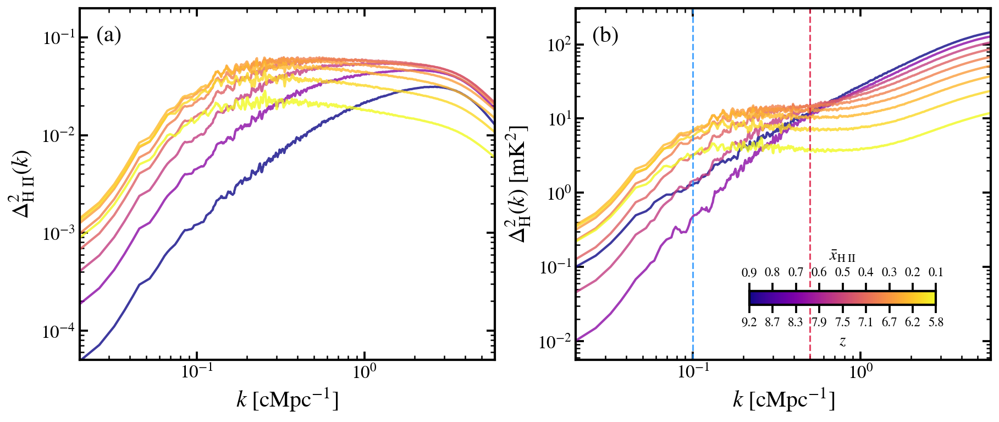

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.gridspec as gridspec
from scipy.signal import savgol_filter

# --------------------------------

# Matplotlib style for publication-quality thicker plots

# --------------------------------

mpl.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 20,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,

    # thicker axis box
    "axes.linewidth": 2.0,
    
    # thicker major/minor ticks
    "xtick.major.width": 1.8,
    "ytick.major.width": 1.8,
    "xtick.minor.width": 1.2,
    "ytick.minor.width": 1.2,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "xtick.minor.size": 4,
    "ytick.minor.size": 4,

    # figure resolution
    "figure.dpi": 150,
    "savefig.dpi": 300,
})

# --------------------------------
# Load PS function
# --------------------------------

def load_ps(filename, h=0.6774, skiprows=5):

    with open(filename) as f:
        lines = f.readlines()
        redshift = float(lines[0])
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k = data[:,0]
    delta2 = data[:,1]
    nmodes = data[:,3]

    delta2 *= mean * mean
    k *= 1e3

    mask = nmodes > 0

    return redshift, k[mask], delta2[mask]


# --------------------------------
# File lists
# --------------------------------

files_Tb_H = [
"./TS_TK/H/Tb/new/PS_Tb_H_177.out",
"./TS_TK/H/Tb/new/PS_Tb_H_203.out",
"./TS_TK/H/Tb/new/PS_Tb_H_220.out",
"./TS_TK/H/Tb/new/PS_Tb_H_242.out",
"./TS_TK/H/Tb/new/PS_Tb_H_264.out",
"./TS_TK/H/Tb/new/PS_Tb_H_283.out",
"./TS_TK/H/Tb/new/PS_Tb_H_300.out",
"./TS_TK/H/Tb/new/PS_Tb_H_318.out",
"./TS_TK/H/Tb/new/PS_Tb_H_338.out",
]

files_HII = [
"./TS_TK/H/f_HII/new/PS_Tb_H_177.out",
"./TS_TK/H/f_HII/new/PS_Tb_H_203.out",
"./TS_TK/H/f_HII/new/PS_Tb_H_220.out",
"./TS_TK/H/f_HII/new/PS_Tb_H_242.out",
"./TS_TK/H/f_HII/new/PS_Tb_H_264.out",
"./TS_TK/H/f_HII/new/PS_Tb_H_283.out",
"./TS_TK/H/f_HII/new/PS_Tb_H_300.out",
"./TS_TK/H/f_HII/new/PS_Tb_H_318.out",
"./TS_TK/H/f_HII/new/PS_Tb_H_338.out",
]


# --------------------------------
# Load data
# --------------------------------

ps_Tb_H = [load_ps(f) for f in files_Tb_H]
ps_HII = [load_ps(f) for f in files_HII]

ps_Tb_H.sort(key=lambda x: x[0], reverse=True)
ps_HII.sort(key=lambda x: x[0], reverse=True)

zs = np.array([x[0] for x in ps_Tb_H])


# --------------------------------
# Colormap
# --------------------------------

cmap = plt.get_cmap("plasma_r")
norm = mpl.colors.Normalize(vmin=zs.min(), vmax=zs.max())

# --------------------------------
# Figure
# --------------------------------

fig = plt.figure(figsize=(12,5), constrained_layout=True)

gs = gridspec.GridSpec(
    1,
    2,
    figure=fig,
    width_ratios=[1, 1]
)

ax_left  = fig.add_subplot(gs[0,0])
ax_right = fig.add_subplot(gs[0,1])


# --------------------------------
# H II power spectrum (left)
# --------------------------------

for z, k, delta2 in ps_HII:

    log_delta = np.log10(delta2)
    smooth_log = savgol_filter(log_delta, 11, 2)
    delta2_smooth = 10**smooth_log

    ax_left.loglog(
        k,
        delta2_smooth,
        color=cmap(norm(z)),
        lw=2.0,
        alpha=0.8
    )

ax_left.set_xlabel(r"$k\ [{\rm cMpc^{-1}}]$", fontsize=20)
ax_left.set_ylabel(r"$\Delta^2_{\rm H \ II}(k)$", fontsize=20)
ax_left.set_xlim(0.02, 6)
ax_left.set_ylim(5.0e-5, 0.2)


# --------------------------------
# 21 cm brightness PS (right)
# --------------------------------

for z, k, delta2 in ps_Tb_H:

    log_delta = np.log10(delta2)
    smooth_log = savgol_filter(log_delta, 11, 2)
    delta2_smooth = 10**smooth_log

    ax_right.loglog(
        k,
        delta2_smooth,
        color=cmap(norm(z)),
        lw=2.0,
        alpha=0.8
    )

ax_right.set_xlabel(r"$k\ [{\rm cMpc^{-1}}]$", fontsize=20)
ax_right.set_ylabel(r"$\Delta^2_{\rm H}(k)\ [{\rm m K}^2]$", fontsize=20)
ax_right.set_xlim(0.02, 6)


# --------------------------------
# Small horizontal embedded colorbar inside right panel
# with second axis for x̄_HII
# --------------------------------

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cax = inset_axes(
    ax_right,
    width="45%",     # horizontal length
    height="4%",     # thin height
    loc="lower right",
    borderpad=3.0
)

# Main colorbar (redshift z)
cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal"
)

cbar.set_label(r"$z$", fontsize=14)
cbar.ax.tick_params(labelsize=11)

# Reverse so high-z is left, low-z is right
cbar.ax.invert_xaxis()

# --------------------------------
# Second top axis: x̄_HII
# --------------------------------

# the snapshots 177 ... 338 are where the volume-weighted <x_HII> = 0.1 ... 0.9 (check_ionization_history.py);
# zs is sorted from high to low z, so the ticks sit at each snapshot's own redshift
xhii_vals = np.arange(0.1, 1.0, 0.1)   # 0.1 → 0.9
tick_positions = zs

# set z ticks (bottom)
cbar.set_ticks(tick_positions)
cbar.set_ticklabels([f"{x:.1f}" for x in tick_positions])

# create top axis
top_ax = cbar.ax.twiny()
top_ax.set_xlim(cbar.ax.get_xlim())

top_ax.set_xticks(tick_positions)
top_ax.set_xticklabels([f"{x:.1f}" for x in xhii_vals], fontsize=11)

top_ax.set_xlabel(
    r"$\bar{x}_{\mathrm{H \ II}}$",
    fontsize=14,
    labelpad=6
)
# --------------------------------
# nicer ticks
# --------------------------------

for ax in [ax_left, ax_right]:

    ax.tick_params(
        which='both',
        direction='in',
        top=True,
        right=True
    )

    ax.minorticks_on()

# --------------------------------
# Panel labels (a), (b)
# --------------------------------

ax_left.text(
    0.04, 0.95,
    r"(a)",
    transform=ax_left.transAxes,
    fontsize=20,
    ha="left",
    va="top"
)

ax_right.text(
    0.04, 0.95,
    r"(b)",
    transform=ax_right.transAxes,
    fontsize=20,
    ha="left",
    va="top"
)

# --------------------------------
# Vertical reference lines
# --------------------------------

ax_right.axvline(
    x=0.1,
    linestyle="--",
    color="dodgerblue",
    linewidth=1.5,
    alpha=0.8
)

ax_right.axvline(
    x=0.5,
    linestyle="--",
    color="crimson",
    linewidth=1.5,
    alpha=0.8
)

# plt.savefig("ps_helium.png", dpi=300, bbox_inches="tight")
plt.show()

## Hydrogen (LUMINA + THESAN-1)

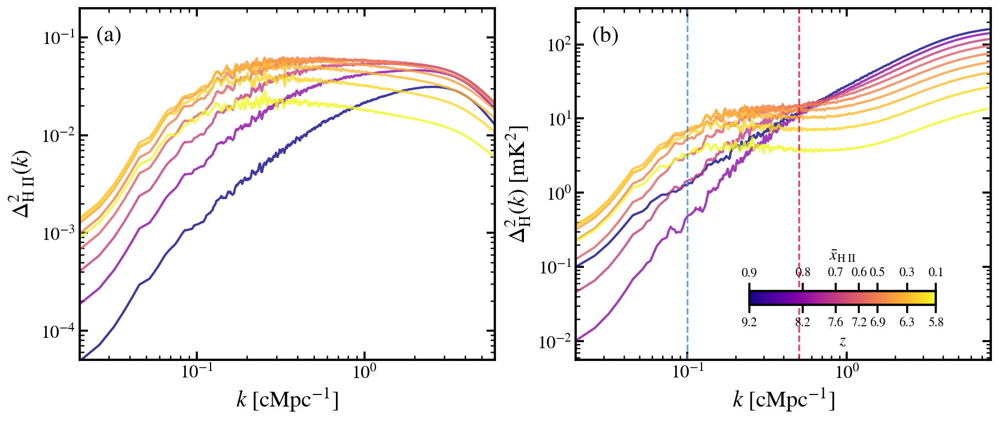

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.gridspec as gridspec
from scipy.signal import savgol_filter

# --------------------------------

# Matplotlib style for publication-quality thicker plots

# --------------------------------

mpl.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 20,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,

    # thicker axis box
    "axes.linewidth": 2.0,
    
    # thicker major/minor ticks
    "xtick.major.width": 1.8,
    "ytick.major.width": 1.8,
    "xtick.minor.width": 1.2,
    "ytick.minor.width": 1.2,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "xtick.minor.size": 4,
    "ytick.minor.size": 4,

    # figure resolution
    "figure.dpi": 150,
    "savefig.dpi": 300,
})

# --------------------------------
# Load PS function
# --------------------------------

def load_ps(filename, h=0.6774, skiprows=5):

    with open(filename) as f:
        lines = f.readlines()
        redshift = float(lines[0])
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k = data[:,0]
    delta2 = data[:,1]
    nmodes = data[:,3]

    delta2 *= mean * mean
    k *= 1e3

    mask = nmodes > 0

    return redshift, k[mask], delta2[mask]


# --------------------------------
# File lists
# --------------------------------

files_Tb_H = [
"./TS_TK/H/Tb/new/PS_Tb_H_177.out",
"./TS_TK/H/Tb/new/PS_Tb_H_203.out",
"./TS_TK/H/Tb/new/PS_Tb_H_220.out",
"./TS_TK/H/Tb/new/PS_Tb_H_242.out",
"./TS_TK/H/Tb/new/PS_Tb_H_264.out",
"./TS_TK/H/Tb/new/PS_Tb_H_283.out",
"./TS_TK/H/Tb/new/PS_Tb_H_300.out",
"./TS_TK/H/Tb/new/PS_Tb_H_318.out",
"./TS_TK/H/Tb/new/PS_Tb_H_338.out",
]

files_HII = [
"./TS_TK/H/f_HII/new/PS_Tb_H_177.out",
"./TS_TK/H/f_HII/new/PS_Tb_H_203.out",
"./TS_TK/H/f_HII/new/PS_Tb_H_220.out",
"./TS_TK/H/f_HII/new/PS_Tb_H_242.out",
"./TS_TK/H/f_HII/new/PS_Tb_H_264.out",
"./TS_TK/H/f_HII/new/PS_Tb_H_283.out",
"./TS_TK/H/f_HII/new/PS_Tb_H_300.out",
"./TS_TK/H/f_HII/new/PS_Tb_H_318.out",
"./TS_TK/H/f_HII/new/PS_Tb_H_338.out",
]


# --------------------------------
# Load data
# --------------------------------

ps_Tb_H = [load_ps(f) for f in files_Tb_H]
ps_HII = [load_ps(f) for f in files_HII]

ps_Tb_H.sort(key=lambda x: x[0], reverse=True)
ps_HII.sort(key=lambda x: x[0], reverse=True)

zs = np.array([x[0] for x in ps_Tb_H])


# --------------------------------
# Colormap
# --------------------------------

cmap = plt.get_cmap("plasma_r")
norm = mpl.colors.Normalize(vmin=zs.min(), vmax=zs.max())

# --------------------------------
# Figure
# --------------------------------

fig = plt.figure(figsize=(12,5), constrained_layout=True)

gs = gridspec.GridSpec(
    1,
    2,
    figure=fig,
    width_ratios=[1, 1]
)

ax_left  = fig.add_subplot(gs[0,0])
ax_right = fig.add_subplot(gs[0,1])


# --------------------------------
# HeIII power spectrum (left)
# --------------------------------

for z, k, delta2 in ps_HII:

    log_delta = np.log10(delta2)
    smooth_log = savgol_filter(log_delta, 11, 2)
    delta2_smooth = 10**smooth_log

    ax_left.loglog(
        k,
        delta2_smooth,
        color=cmap(norm(z)),
        lw=2.0,
        alpha=0.8
    )

ax_left.set_xlabel(r"$k\ [{\rm cMpc^{-1}}]$", fontsize=20)
ax_left.set_ylabel(r"$\Delta^2_{\rm H \ II}(k)$", fontsize=20)
ax_left.set_xlim(0.02, 6)
ax_left.set_ylim(5.0e-5, 0.2)


# --------------------------------
# Helium brightness PS (right)
# --------------------------------

for z, k, delta2 in ps_Tb_H:

    log_delta = np.log10(delta2)
    smooth_log = savgol_filter(log_delta, 11, 2)
    delta2_smooth = 10**smooth_log

    ax_right.loglog(
        k,
        delta2_smooth,
        color=cmap(norm(z)),
        lw=2.0,
        alpha=0.8
    )

ax_right.set_xlabel(r"$k\ [{\rm cMpc^{-1}}]$", fontsize=20)
ax_right.set_ylabel(r"$\Delta^2_{\rm H}(k)\ [{\rm m K}^2]$", fontsize=20)
ax_right.set_xlim(0.02, 8)


# --------------------------------
# Small horizontal embedded colorbar inside right panel
# with second axis for x̄_HII
# --------------------------------

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cax = inset_axes(
    ax_right,
    width="45%",     # horizontal length
    height="4%",     # thin height
    loc="lower right",
    borderpad=3.0
)

# Main colorbar (redshift z)
cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal"
)

cbar.set_label(r"$z$", fontsize=14)
cbar.ax.tick_params(labelsize=11)

# Reverse so high-z is left, low-z is right
#cbar.ax.invert_xaxis()


# --------------------------------
# Second top axis: x̄_HII
# using exact z ↔ x̄_HII mapping
# --------------------------------

# exact physical mapping
xhii_vals = np.array([   # volume-weighted <x_HII> at the z_match below (check_ionization_history.py)
    0.90,
    #0.80,
    0.70,
    #0.60,
    0.50,
    0.40,
    0.30,
    0.20,
    0.10
])

z_match = np.array([
    5.826679,
    #6.099902,
    6.342011,
    #6.592783,
    6.872631,
    7.204283,
    7.624910,
    8.207879,
    9.170129
])

# --------------------------------
# Bottom ticks = redshift z
# --------------------------------

cbar.set_ticks(z_match)
cbar.set_ticklabels([f"{z:.1f}" for z in z_match])

# reverse so high-z is left
cbar.ax.invert_xaxis()

# --------------------------------
# Top ticks = x̄_HII
# --------------------------------

top_ax = cbar.ax.twiny()
top_ax.set_xlim(cbar.ax.get_xlim())

top_ax.set_xticks(z_match)
top_ax.set_xticklabels(
    [f"{x:.1f}" for x in xhii_vals],
    fontsize=11
)

top_ax.set_xlabel(
    r"$\bar{x}_{\mathrm{H \ II}}$",
    fontsize=14,
    labelpad=6
)

# --------------------------------
# nicer ticks
# --------------------------------

for ax in [ax_left, ax_right]:

    ax.tick_params(
        which='both',
        direction='in',
        top=True,
        right=True
    )

    ax.minorticks_on()

# --------------------------------
# Panel labels (a), (b)
# --------------------------------

ax_left.text(
    0.04, 0.95,
    r"(a)",
    transform=ax_left.transAxes,
    fontsize=20,
    ha="left",
    va="top"
)

ax_right.text(
    0.04, 0.95,
    r"(b)",
    transform=ax_right.transAxes,
    fontsize=20,
    ha="left",
    va="top"
)

# --------------------------------
# Vertical reference lines
# --------------------------------

ax_right.axvline(
    x=0.1,
    linestyle="--",
    color="dodgerblue",
    linewidth=1.5,
    alpha=0.8
)

ax_right.axvline(
    x=0.5,
    linestyle="--",
    color="crimson",
    linewidth=1.5,
    alpha=0.8
)

# --------------------------------
# Original Thesan-1 files
# Use SAME color mapping as Thesan-XL
# because they correspond to the same ionized fraction / redshift ordering
# --------------------------------

path_original = "./past/original/Thesan-1/PS_H_Tb_"

snaps_original = [105, 137, 169, 196, 220, 242, 263, 285, 310]

files_original = [
    f"{path_original}{snap:03d}.out"
    for snap in snaps_original
]

ps_original = [load_ps(f) for f in files_original]

# sort by redshift (high z -> low z)
ps_original.sort(key=lambda x: x[0], reverse=True)


# --------------------------------
# Plot original curves on RIGHT panel
# SAME colormap as Thesan-XL
# solid = Thesan-XL
# dashed = Thesan-1
# --------------------------------

#for i, (z, k, delta2) in enumerate(ps_original):

#    log_delta = np.log10(delta2)
#    smooth_log = savgol_filter(log_delta, 11, 2)
#    delta2_smooth = 10**smooth_log

    # use SAME color as corresponding Thesan-XL snapshot
#    curve_color = cmap(norm(zs[i]))

#    ax_right.loglog(
#        k,
#        delta2_smooth,
#        color=curve_color,
#        lw=2.0,
#        ls="--",      # dashed = original
#        alpha=0.9
#    )


# --------------------------------
# Cleaner legend
# --------------------------------

from matplotlib.lines import Line2D

legend_elements = [
    Line2D(
        [0], [0],
        color="black",
        lw=2.2,
        ls="-",
        label="LUMINA"
    ),
    Line2D(
        [0], [0],
        color="black",
        lw=2.2,
        ls="--",
        label="THESAN-1"
    )
]

#ax_left.legend(
#    handles=legend_elements,
#    fontsize=13,
#    frameon=False,
#    loc="lower right"
#)



# plt.savefig("ps_helium.png", dpi=300, bbox_inches="tight")
plt.show()

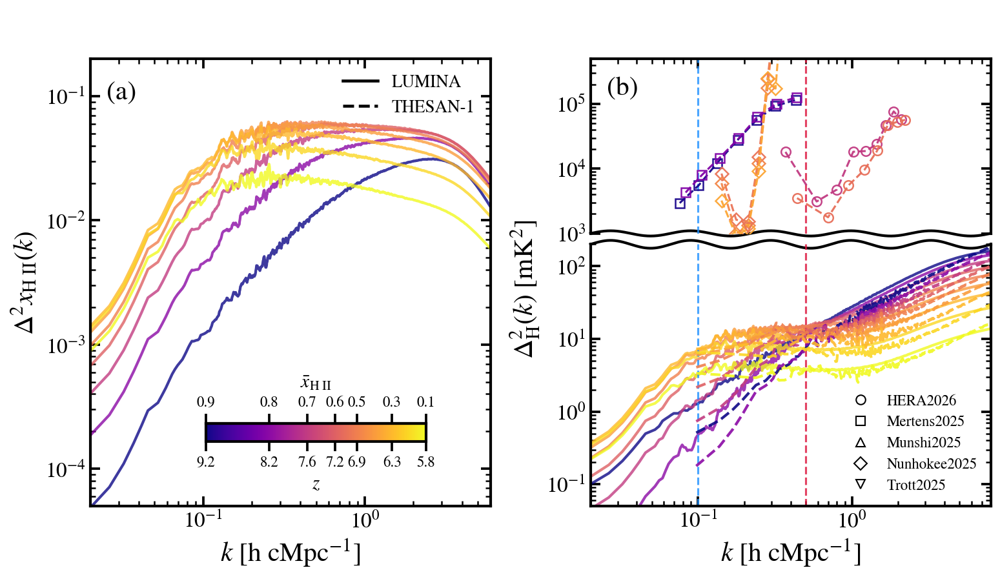

In [81]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.gridspec as gridspec
from scipy.signal import savgol_filter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import pandas as pd
from matplotlib.lines import Line2D

# --------------------------------
# Matplotlib style for publication-quality thicker plots
# --------------------------------
mpl.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 20,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "axes.linewidth": 2.0,
    "xtick.major.width": 1.8,
    "ytick.major.width": 1.8,
    "xtick.minor.width": 1.2,
    "ytick.minor.width": 1.2,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "xtick.minor.size": 4,
    "ytick.minor.size": 4,
    "figure.dpi": 150,
    "savefig.dpi": 300,
})

# --------------------------------
# Load PS function
# --------------------------------
def load_ps(filename, h=0.6774, skiprows=5):
    with open(filename) as f:
        lines = f.readlines()
        redshift = float(lines[0])
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)
    k = data[:,0]
    delta2 = data[:,1]
    nmodes = data[:,3]

    delta2 *= mean * mean
    k *= 1e3

    mask = nmodes > 0
    return redshift, k[mask], delta2[mask]

# --------------------------------
# File lists (Replace with your actual paths if needed)
# --------------------------------
files_Tb_H = [
    "./TS_TK/H/Tb/new/PS_Tb_H_177.out",
    "./TS_TK/H/Tb/new/PS_Tb_H_203.out",
    "./TS_TK/H/Tb/new/PS_Tb_H_220.out",
    "./TS_TK/H/Tb/new/PS_Tb_H_242.out",
    "./TS_TK/H/Tb/new/PS_Tb_H_264.out",
    "./TS_TK/H/Tb/new/PS_Tb_H_283.out",
    "./TS_TK/H/Tb/new/PS_Tb_H_300.out",
    "./TS_TK/H/Tb/new/PS_Tb_H_318.out",
    "./TS_TK/H/Tb/new/PS_Tb_H_338.out",
]

files_HII = [
    "./TS_TK/H/f_HII/new/PS_Tb_H_177.out",
    "./TS_TK/H/f_HII/new/PS_Tb_H_203.out",
    "./TS_TK/H/f_HII/new/PS_Tb_H_220.out",
    "./TS_TK/H/f_HII/new/PS_Tb_H_242.out",
    "./TS_TK/H/f_HII/new/PS_Tb_H_264.out",
    "./TS_TK/H/f_HII/new/PS_Tb_H_283.out",
    "./TS_TK/H/f_HII/new/PS_Tb_H_300.out",
    "./TS_TK/H/f_HII/new/PS_Tb_H_318.out",
    "./TS_TK/H/f_HII/new/PS_Tb_H_338.out",
]

# --------------------------------
# Load data
# --------------------------------
ps_Tb_H = [load_ps(f) for f in files_Tb_H]
ps_HII = [load_ps(f) for f in files_HII]

ps_Tb_H.sort(key=lambda x: x[0], reverse=True)
ps_HII.sort(key=lambda x: x[0], reverse=True)
zs = np.array([x[0] for x in ps_Tb_H])

# --------------------------------
# Colormap
# --------------------------------
cmap = plt.get_cmap("plasma_r")
norm = mpl.colors.Normalize(vmin=zs.min(), vmax=zs.max())

# --------------------------------
# Figure & GridSpec Setup
# --------------------------------
fig = plt.figure(figsize=(12, 6))

gs = gridspec.GridSpec(
    2, 2,
    figure=fig,
    width_ratios=[1, 1],
    height_ratios=[1, 1.5], # Top right panel vs bottom right panel height
    wspace=0.25,            # Gap between left and right side
    hspace=0.05             # Small vertical gap for the scale break
)

ax_left = fig.add_subplot(gs[:, 0])      # Spans both rows on the left
ax_right_top = fig.add_subplot(gs[0, 1]) # Top right
ax_right_bot = fig.add_subplot(gs[1, 1]) # Bottom right

# --------------------------------
# HeIII power spectrum (left)
# --------------------------------
for z, k, delta2 in ps_HII:
    log_delta = np.log10(delta2)
    smooth_log = savgol_filter(log_delta, 11, 2)
    delta2_smooth = 10**smooth_log

    ax_left.loglog(
        k, delta2_smooth,
        color=cmap(norm(z)),
        lw=2.0, alpha=0.8
    )

ax_left.set_xlabel(r"$k\ [{\rm h \ cMpc^{-1}}]$", fontsize=20)
ax_left.set_ylabel(r"$\Delta^2 x_{\rm H \ II}(k)$", fontsize=20)
ax_left.set_xlim(0.02, 6)
ax_left.set_ylim(5.0e-5, 0.2)

# --------------------------------
# Helium brightness PS (right top & bottom)
# --------------------------------
for z, k, delta2 in ps_Tb_H:
    log_delta = np.log10(delta2)
    smooth_log = savgol_filter(log_delta, 11, 2)
    delta2_smooth = 10**smooth_log

    for ax in [ax_right_top, ax_right_bot]:
        ax.loglog(
            k, delta2_smooth,
            color=cmap(norm(z)),
            lw=2.0, alpha=0.8
        )

# Right Axis Limits & Labels
for ax in [ax_right_top, ax_right_bot]:
    ax.set_xlim(0.02, 8)

# NOTE: Adjust these y-limits based on your actual data ranges!
ax_right_top.set_ylim(1e3, 5e5)     # For Observational limits
ax_right_bot.set_ylim(5.0e-2, 200)  # For Simulations

ax_right_bot.set_xlabel(r"$k\ [{\rm h \ cMpc^{-1}}]$", fontsize=20)
ax_right_bot.set_ylabel(r"$\Delta^2_{\rm H}(k)\ [{\rm m K}^2]$", fontsize=20)

# Shift the label up to the middle. 
# Because height_ratios=[1, 1.5], the exact midpoint is ~0.83 relative to the bottom panel's height.
ax_right_bot.yaxis.set_label_coords(-0.12, 0.83)

# --------------------------------
# Format the Scale Break (Spines and Ticks)
# --------------------------------
ax_right_top.spines['bottom'].set_visible(False)
ax_right_bot.spines['top'].set_visible(False)
ax_right_top.tick_params(labelbottom=False, bottom=False, which='both')
ax_right_bot.xaxis.tick_bottom()

# --------------------------------
# Draw Wavy Scale Break Lines Across the Axes
# --------------------------------
# Generate x values from 0 to 1 in axes coordinates
x_wave = np.linspace(0, 1, 500)

# Adjust 'freq' for the number of bumps, and 'amp' for the height of the bumps
freq = 5 * 2 * np.pi  # 5 full sine waves across the width
amp = 0.015           # Amplitude in axes coordinates

y_wave = amp * np.sin(x_wave * freq)

# Draw the wavy line at the very bottom edge of the top panel (y = 0)
ax_right_top.plot(
    x_wave, y_wave, 
    transform=ax_right_top.transAxes, 
    color='k', clip_on=False, lw=2.0
)

# Draw an identical wavy line at the very top edge of the bottom panel (y = 1)
ax_right_bot.plot(
    x_wave, 1 + y_wave, 
    transform=ax_right_bot.transAxes, 
    color='k', clip_on=False, lw=2.0
)

# --------------------------------
# Small horizontal embedded colorbar
# --------------------------------
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cax = inset_axes(
    ax_left,
    width="55%",
    height="4%",
    loc="lower right",
    borderpad=3.0
)
cbar = fig.colorbar(sm, cax=cax, orientation="horizontal")
cbar.set_label(r"$z$", fontsize=14)
cbar.ax.tick_params(labelsize=11)

# Second top axis: x̄_HII
xhii_vals = np.array([0.90, 0.70, 0.50, 0.40, 0.30, 0.20, 0.10])   # volume-weighted <x_HII> at z_match
z_match = np.array([5.826679, 6.342011, 6.872631, 7.204283, 7.624910, 8.207879, 9.170129])

cbar.set_ticks(z_match)
cbar.set_ticklabels([f"{z:.1f}" for z in z_match])
cbar.ax.invert_xaxis()

top_ax = cbar.ax.twiny()
top_ax.set_xlim(cbar.ax.get_xlim())
top_ax.set_xticks(z_match)
top_ax.set_xticklabels([f"{x:.1f}" for x in xhii_vals], fontsize=11)
top_ax.set_xlabel(r"$\bar{x}_{\mathrm{H \ II}}$", fontsize=14, labelpad=6)

# --------------------------------
# Nicer ticks
# --------------------------------
for ax in [ax_left, ax_right_top, ax_right_bot]:
    ax.tick_params(which='both', direction='in', top=True, right=True)
    ax.minorticks_on()

# Explicitly turn off both MAJOR and MINOR ticks on the shared boundary
ax_right_top.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
ax_right_bot.tick_params(axis='x', which='both', top=False, labeltop=False)

# --------------------------------
# Panel labels (a), (b)
# --------------------------------
ax_left.text(0.04, 0.95, r"(a)", transform=ax_left.transAxes, fontsize=20, ha="left", va="top")
ax_right_top.text(0.04, 0.90, r"(b)", transform=ax_right_top.transAxes, fontsize=20, ha="left", va="top")

# --------------------------------
# Vertical reference lines
# --------------------------------
for ax in [ax_right_top, ax_right_bot]:
    ax.axvline(x=0.1, linestyle="--", color="dodgerblue", linewidth=1.5, alpha=0.8)
    ax.axvline(x=0.5, linestyle="--", color="crimson", linewidth=1.5, alpha=0.8)

# --------------------------------
# Original Thesan-1 files
# --------------------------------
path_original = "./past/original/Thesan-1/PS_H_Tb_"
snaps_original = [105, 137, 169, 196, 220, 242, 263, 285, 310]
files_original = [f"{path_original}{snap:03d}.out" for snap in snaps_original]

# Mocking data load for Thesan-1 due to missing files locally; assumes load_ps works
try:
    ps_original = [load_ps(f) for f in files_original]
    ps_original.sort(key=lambda x: x[0], reverse=True)

    for i, (z, k, delta2) in enumerate(ps_original):
        log_delta = np.log10(delta2)
        smooth_log = savgol_filter(log_delta, 11, 2)
        delta2_smooth = 10**smooth_log
        curve_color = cmap(norm(zs[i]))

        for ax in [ax_right_top, ax_right_bot]:
            ax.loglog(k, delta2_smooth, color=curve_color, lw=2.0, ls="--", alpha=0.9)
except FileNotFoundError:
    pass # Skips if files aren't found in your directory

# --------------------------------
# Cleaner legend
# --------------------------------
legend_elements = [
    Line2D([0], [0], color="black", lw=2.2, ls="-", label="LUMINA"),
    Line2D([0], [0], color="black", lw=2.2, ls="--", label="THESAN-1")
]
ax_left.legend(handles=legend_elements, fontsize=13, frameon=False, loc="upper right")

# --------------------------------
# Add observational datasets
# --------------------------------
obs_files = ["HERA2026.csv", "Mertens2025.csv", "Munshi2025.csv", "Nunhokee2025.csv", "Trott2025.csv"]
obs_markers = ["o", "s", "^", "D", "v"]
z_obs_min = 5.8
z_obs_max = 9.2

def plot_observation_on_right(ax_list, filename, marker):
    try:
        df = pd.read_csv(filename)
        if "Unnamed: 0" in df.columns:
            df = df.drop(columns=["Unnamed: 0"])
        df = df[(df["z"] >= z_obs_min) & (df["z"] <= z_obs_max)]
        label_base = filename.replace(".csv", "")

        for z in sorted(df["z"].unique(), reverse=True):
            row = df[df["z"] == z].iloc[0]
            k_vals = np.array([float(x) for x in str(row["k"]).split(",")])
            delta_vals = np.array([float(x) for x in str(row["delta_squared"]).split(",")])
            point_color = cmap(norm(z))

            for ax in ax_list:
                ax.loglog(
                    k_vals, delta_vals, linestyle="--", marker=marker, ms=7,
                    mew=1.2, markerfacecolor="none", color=point_color,
                    alpha=0.95, label=fr"{label_base} ($z={z}$)"
                )
    except FileNotFoundError:
        pass

for file, marker in zip(obs_files, obs_markers):
    plot_observation_on_right([ax_right_top, ax_right_bot], file, marker)

# --------------------------------
# Observation legend
# --------------------------------
obs_legend = [
    Line2D([0], [0], marker="o", color="black", linestyle="None", markerfacecolor="none", markersize=7, label="HERA2026"),
    Line2D([0], [0], marker="s", color="black", linestyle="None", markerfacecolor="none", markersize=7, label="Mertens2025"),
    Line2D([0], [0], marker="^", color="black", linestyle="None", markerfacecolor="none", markersize=7, label="Munshi2025"),
    Line2D([0], [0], marker="D", color="black", linestyle="None", markerfacecolor="none", markersize=7, label="Nunhokee2025"),
    Line2D([0], [0], marker="v", color="black", linestyle="None", markerfacecolor="none", markersize=7, label="Trott2025")
]

# Attach the legend to the bottom right panel in the lower right corner
ax_right_bot.legend(
    handles=obs_legend, 
    fontsize=11, 
    frameon=False, 
    loc="lower right"
)

# plt.savefig("ps_helium.png", dpi=300, bbox_inches="tight")
plt.show()

# plt.savefig("ps_helium.png", dpi=300, bbox_inches="tight")
plt.show()

## Obs

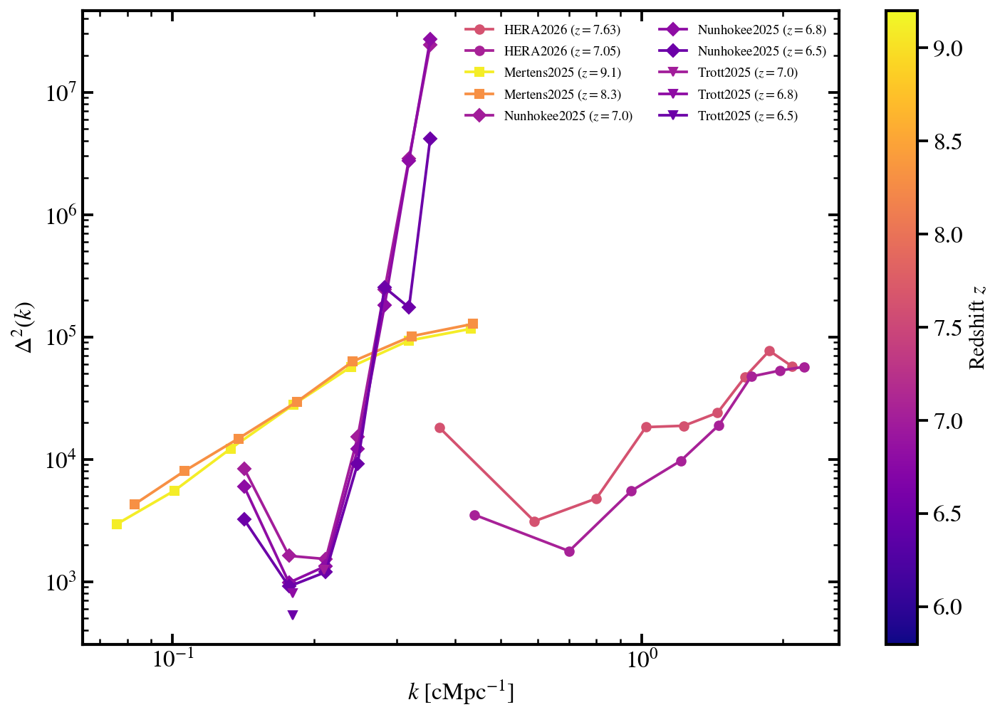

In [53]:
# The error happens because plt.colorbar() does not know
# which axes it should attach the colorbar to.

# Fix:
# create fig, ax explicitly and pass ax=ax to colorbar

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# =====================================
# Settings
# =====================================

files = [
    "HERA2026.csv",
    "Mertens2025.csv",
    "Munshi2025.csv",
    "Nunhokee2025.csv",
    "Trott2025.csv"
]

markers = ["o", "s", "^", "D", "v"]

z_min = 5.8
z_max = 9.2

cmap = plt.get_cmap("plasma")
norm = mpl.colors.Normalize(vmin=z_min, vmax=z_max)


# =====================================
# Function
# =====================================

def plot_file(ax, filename, marker):
    df = pd.read_csv(filename)

    if "Unnamed: 0" in df.columns:
        df = df.drop(columns=["Unnamed: 0"])

    df = df[(df["z"] >= z_min) & (df["z"] <= z_max)]

    label_base = filename.replace(".csv", "")

    for z in sorted(df["z"].unique(), reverse=True):
        row = df[df["z"] == z].iloc[0]

        k_vals = np.array([
            float(x) for x in str(row["k"]).split(",")
        ])

        delta_vals = np.array([
            float(x) for x in str(row["delta_squared"]).split(",")
        ])

        color = cmap(norm(z))

        ax.loglog(
            k_vals,
            delta_vals,
            marker=marker,
            lw=1.8,
            ms=6,
            color=color,
            label=fr"{label_base} ($z={z}$)"
        )


# =====================================
# Main plot
# =====================================

fig, ax = plt.subplots(figsize=(10, 7))

for file, marker in zip(files, markers):
    plot_file(ax, file, marker)

# =====================================
# Colorbar (FIXED)
# =====================================

sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label(r"Redshift $z$", fontsize=14)

# =====================================
# Style
# =====================================

ax.set_xlabel(r"$k\ [{\rm cMpc^{-1}}]$", fontsize=16)
ax.set_ylabel(r"$\Delta^2(k)$", fontsize=16)

ax.tick_params(
    which="both",
    direction="in",
    top=True,
    right=True
)

ax.legend(
    fontsize=9,
    frameon=False,
    loc="best",
    ncol=2
)

plt.tight_layout()
plt.show()


/tmp/ipykernel_258483/1429663549.py:424: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


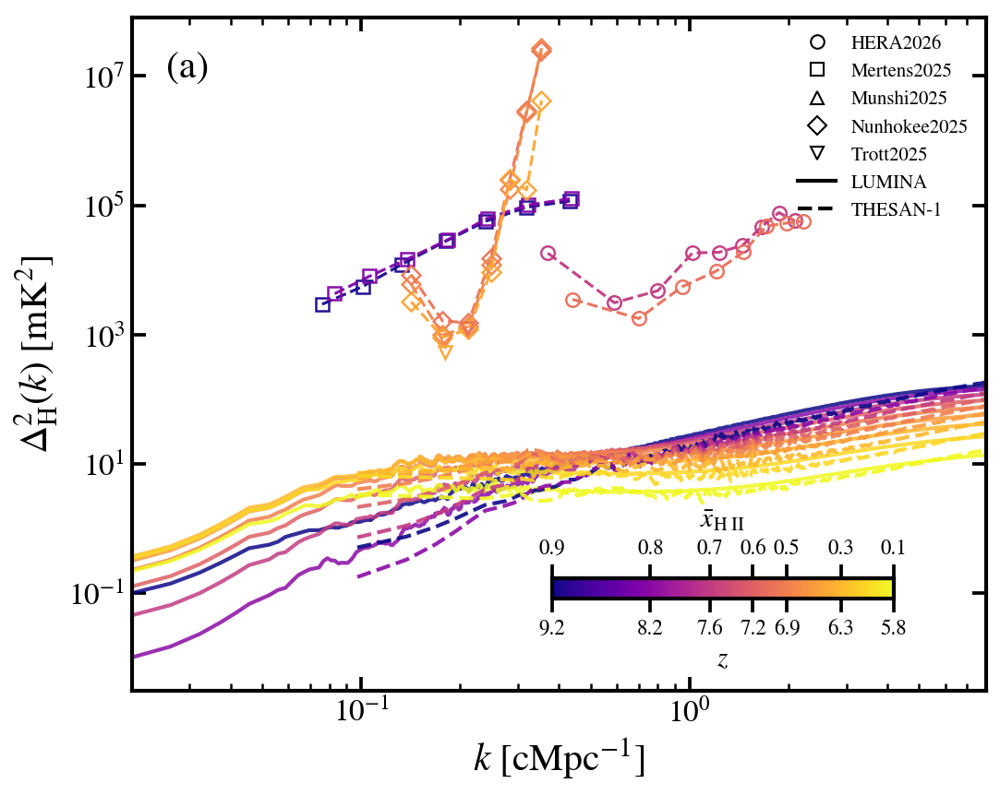

In [29]:
# =====================================
# RIGHT PANEL ONLY VERSION
# Keep only panel (b)
# =====================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.signal import savgol_filter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.lines import Line2D
import pandas as pd

# =====================================
# Publication-quality style
# =====================================

mpl.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 20,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,

    "axes.linewidth": 2.0,

    "xtick.major.width": 1.8,
    "ytick.major.width": 1.8,
    "xtick.minor.width": 1.2,
    "ytick.minor.width": 1.2,

    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "xtick.minor.size": 4,
    "ytick.minor.size": 4,

    "figure.dpi": 150,
    "savefig.dpi": 300,
})

# =====================================
# Load PS function
# =====================================

def load_ps(filename, skiprows=5):
    with open(filename) as f:
        lines = f.readlines()
        redshift = float(lines[0])
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k = data[:, 0]
    delta2 = data[:, 1]
    nmodes = data[:, 3]

    delta2 *= mean * mean
    k *= 1e3

    mask = nmodes > 0

    return redshift, k[mask], delta2[mask]


# =====================================
# Input files
# =====================================

files_Tb_H = [
    "./TS_TK/H/Tb/new/PS_Tb_H_177.out",
    "./TS_TK/H/Tb/new/PS_Tb_H_203.out",
    "./TS_TK/H/Tb/new/PS_Tb_H_220.out",
    "./TS_TK/H/Tb/new/PS_Tb_H_242.out",
    "./TS_TK/H/Tb/new/PS_Tb_H_264.out",
    "./TS_TK/H/Tb/new/PS_Tb_H_283.out",
    "./TS_TK/H/Tb/new/PS_Tb_H_300.out",
    "./TS_TK/H/Tb/new/PS_Tb_H_318.out",
    "./TS_TK/H/Tb/new/PS_Tb_H_338.out",
]

# =====================================
# Load simulation data
# =====================================

ps_Tb_H = [load_ps(f) for f in files_Tb_H]
ps_Tb_H.sort(key=lambda x: x[0], reverse=True)

zs = np.array([x[0] for x in ps_Tb_H])

# =====================================
# Colormap
# =====================================

cmap = plt.get_cmap("plasma_r")
norm = mpl.colors.Normalize(vmin=zs.min(), vmax=zs.max())

# =====================================
# Figure (single panel)
# =====================================

fig, ax = plt.subplots(figsize=(7.5, 6))

# =====================================
# Main simulation curves (LUMINA)
# =====================================

for z, k, delta2 in ps_Tb_H:

    log_delta = np.log10(delta2)
    smooth_log = savgol_filter(log_delta, 11, 2)
    delta2_smooth = 10 ** smooth_log

    ax.loglog(
        k,
        delta2_smooth,
        color=cmap(norm(z)),
        lw=2.0,
        alpha=0.85
    )

ax.set_xlabel(r"$k\ [{\rm cMpc^{-1}}]$")
ax.set_ylabel(r"$\Delta^2_{\rm H}(k)\ [{\rm mK}^2]$")
ax.set_xlim(0.02, 8)

# =====================================
# THESAN-1 comparison
# =====================================

path_original = "./past/original/Thesan-1/PS_H_Tb_"

snaps_original = [105, 137, 169, 196, 220, 242, 263, 285, 310]

files_original = [
    f"{path_original}{snap:03d}.out"
    for snap in snaps_original
]

ps_original = [load_ps(f) for f in files_original]
ps_original.sort(key=lambda x: x[0], reverse=True)

for i, (z, k, delta2) in enumerate(ps_original):

    log_delta = np.log10(delta2)
    smooth_log = savgol_filter(log_delta, 11, 2)
    delta2_smooth = 10 ** smooth_log

    curve_color = cmap(norm(zs[i]))

    ax.loglog(
        k,
        delta2_smooth,
        color=curve_color,
        lw=2.0,
        ls="--",
        alpha=0.9
    )

# =====================================
# Embedded colorbar
# =====================================

sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cax = inset_axes(
    ax,
    width="40%",
    height="3%",
    loc="lower right",
    borderpad=3.0
)

cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal"
)

cbar.set_label(r"$z$", fontsize=14)
cbar.ax.tick_params(labelsize=11)

# exact mapping
xhii_vals = np.array([   # volume-weighted <x_HII> at the z_match below (check_ionization_history.py)
    0.90,
    0.70,
    0.50,
    0.40,
    0.30,
    0.20,
    0.10
])

z_match = np.array([
    5.826679,
    6.342011,
    6.872631,
    7.204283,
    7.624910,
    8.207879,
    9.170129
])

cbar.set_ticks(z_match)
cbar.set_ticklabels([f"{z:.1f}" for z in z_match])

cbar.ax.invert_xaxis()

top_ax = cbar.ax.twiny()
top_ax.set_xlim(cbar.ax.get_xlim())

top_ax.set_xticks(z_match)
top_ax.set_xticklabels(
    [f"{x:.1f}" for x in xhii_vals],
    fontsize=11
)

top_ax.set_xlabel(
    r"$\bar{x}_{\mathrm{H\ II}}$",
    fontsize=14,
    labelpad=6
)

# =====================================
# Tick style
# =====================================

ax.tick_params(
    which="both",
    direction="in",
    top=True,
    right=True
)

ax.minorticks_on()

# =====================================
# Panel label (only b)
# =====================================

ax.text(
    0.04,
    0.95,
    r"(a)",
    transform=ax.transAxes,
    fontsize=20,
    ha="left",
    va="top"
)




# --------------------------------
# Add observational datasets on RIGHT panel only
# (HERA2026, Mertens2025, Munshi2025, Nunhokee2025, Trott2025)
# --------------------------------

import pandas as pd

obs_files = [
    "HERA2026.csv",
    "Mertens2025.csv",
    "Munshi2025.csv",
    "Nunhokee2025.csv",
    "Trott2025.csv"
]

obs_markers = ["o", "s", "^", "D", "v"]

# keep consistent redshift range with colorbar
z_obs_min = 5.8
z_obs_max = 9.2


def plot_observation_on_right(ax, filename, marker):
    """
    Plot observational points on the right panel.
    Uses:
    - same colormap by redshift
    - different marker by survey
    """

    df = pd.read_csv(filename)

    if "Unnamed: 0" in df.columns:
        df = df.drop(columns=["Unnamed: 0"])

    # keep only desired redshift range
    df = df[
        (df["z"] >= z_obs_min) &
        (df["z"] <= z_obs_max)
    ]

    label_base = filename.replace(".csv", "")

    for z in sorted(df["z"].unique(), reverse=True):

        row = df[df["z"] == z].iloc[0]

        # convert string list -> float array
        k_vals = np.array([
            float(x)
            for x in str(row["k"]).split(",")
        ])

        delta_vals = np.array([
            float(x)
            for x in str(row["delta_squared"]).split(",")
        ])

        # same color rule as simulation
        point_color = cmap(norm(z))

        ax.loglog(
            k_vals,
            delta_vals,
            linestyle="--",   # points only
            marker=marker,
            ms=7,
            mew=1.2,
            markerfacecolor="none",
            color=point_color,
            alpha=0.95,
            label=fr"{label_base} ($z={z}$)"
        )


# --------------------------------
# Plot all observational datasets
# --------------------------------

for file, marker in zip(obs_files, obs_markers):
    plot_observation_on_right(
        ax,
        file,
        marker
    )


# --------------------------------
# Observation legend (separate)
# --------------------------------

# =====================================
# Legend
# =====================================


ax.legend(
    handles=legend_elements,
    fontsize=13,
    frameon=False,
    loc="upper left"
)

obs_legend = [
    Line2D(
        [0], [0],
        marker="o",
        color="black",
        linestyle="None",
        markerfacecolor="none",
        markersize=7,
        label="HERA2026"
    ),
    Line2D(
        [0], [0],
        marker="s",
        color="black",
        linestyle="None",
        markerfacecolor="none",
        markersize=7,
        label="Mertens2025"
    ),
    Line2D(
        [0], [0],
        marker="^",
        color="black",
        linestyle="None",
        markerfacecolor="none",
        markersize=7,
        label="Munshi2025"
    ),
    Line2D(
        [0], [0],
        marker="D",
        color="black",
        linestyle="None",
        markerfacecolor="none",
        markersize=7,
        label="Nunhokee2025"
    ),
    Line2D(
        [0], [0],
        marker="v",
        color="black",
        linestyle="None",
        markerfacecolor="none",
        markersize=7,
        label="Trott2025"
    ),
    Line2D(
        [0], [0],
        color="black",
        lw=2.0,
        ls="-",
        label="LUMINA"
    ),
    Line2D(
        [0], [0],
        color="black",
        lw=2.0,
        ls="--",
        label="THESAN-1"
    )
]

ax.legend(
    handles=obs_legend,
    fontsize=10,
    frameon=False,
    loc="upper right"
)
plt.tight_layout()
plt.show()

## Helium

In [2]:
import cmocean

from cmap import Colormap


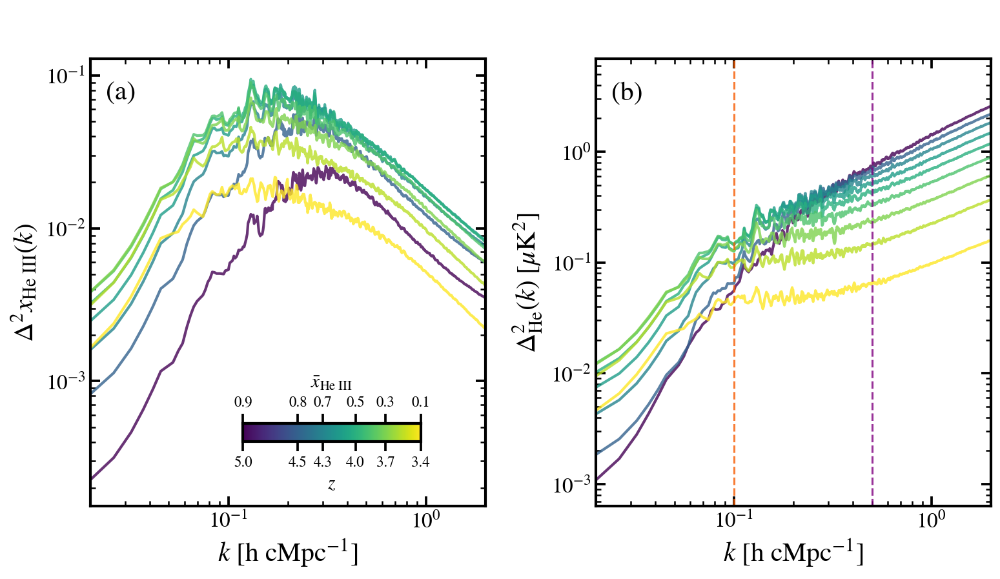

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.gridspec as gridspec
from scipy.signal import savgol_filter

# --------------------------------

# Matplotlib style for publication-quality thicker plots

# --------------------------------

mpl.rcParams.update({
    "font.size": 16,
    "axes.labelsize": 20,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,

    # thicker axis box
    "axes.linewidth": 2.0,
    
    # thicker major/minor ticks
    "xtick.major.width": 1.8,
    "ytick.major.width": 1.8,
    "xtick.minor.width": 1.2,
    "ytick.minor.width": 1.2,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "xtick.minor.size": 4,
    "ytick.minor.size": 4,

    # figure resolution
    "figure.dpi": 150,
    "savefig.dpi": 300,
})

# --------------------------------
# Load PS function
# --------------------------------

def load_ps(filename, h=0.6774, skiprows=5):

    with open(filename) as f:
        lines = f.readlines()
        redshift = float(lines[0])
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k = data[:,0]
    delta2 = data[:,1]
    nmodes = data[:,3]

    delta2 *= mean * mean
    k *= 1e3

    mask = nmodes > 0

    return redshift, k[mask], delta2[mask]


# --------------------------------
# File lists
# --------------------------------

files_Tb_He = [
"./TS_TK/He/Tb/new/PS_Tb_He_406.out",
"./TS_TK/He/Tb/new/PS_Tb_He_450.out",
"./TS_TK/He/Tb/new/PS_Tb_He_471.out",
"./TS_TK/He/Tb/new/PS_Tb_He_487.out",
"./TS_TK/He/Tb/new/PS_Tb_He_500.out",
"./TS_TK/He/Tb/new/PS_Tb_He_514.out",
"./TS_TK/He/Tb/new/PS_Tb_He_529.out",
"./TS_TK/He/Tb/new/PS_Tb_He_558.out",
"./TS_TK/He/Tb/new/PS_Tb_He_596.out",
]

files_HeIII = [
"./TS_TK/He/f_HeIII/new/PS_He_406.out",
"./TS_TK/He/f_HeIII/new/PS_He_450.out",
"./TS_TK/He/f_HeIII/new/PS_He_471.out",
"./TS_TK/He/f_HeIII/new/PS_He_487.out",
"./TS_TK/He/f_HeIII/new/PS_He_500.out",
"./TS_TK/He/f_HeIII/new/PS_He_514.out",
"./TS_TK/He/f_HeIII/new/PS_He_529.out",
"./TS_TK/He/f_HeIII/new/PS_He_558.out",
"./TS_TK/He/f_HeIII/new/PS_He_596.out",
]


# --------------------------------
# Load data
# --------------------------------

ps_Tb_He = [load_ps(f) for f in files_Tb_He]
ps_HeIII = [load_ps(f) for f in files_HeIII]

ps_Tb_He.sort(key=lambda x: x[0], reverse=True)
ps_HeIII.sort(key=lambda x: x[0], reverse=True)

zs = np.array([x[0] for x in ps_Tb_He])


# --------------------------------
# Colormap
# --------------------------------

cmap = plt.get_cmap("viridis_r") #Colormap('imagej:fire').to_mpl()  #plt.get_cmap("spectral") #"viridis_r", "cmr.neon_r"
norm = mpl.colors.Normalize(vmin=zs.min(), vmax=zs.max())

# --------------------------------
# Figure
# --------------------------------

fig = plt.figure(figsize=(12,6))#, constrained_layout=True)
#fig = plt.figure(figsize=(11,6))

gs = gridspec.GridSpec(
    1,
    2,
    figure=fig,
    width_ratios=[1, 1],
    wspace=0.28
)

ax_left  = fig.add_subplot(gs[0,0])
ax_right = fig.add_subplot(gs[0,1])


# --------------------------------
# HeIII power spectrum (left)
# --------------------------------

for z, k, delta2 in ps_HeIII:

    log_delta = np.log10(delta2)
    smooth_log = savgol_filter(log_delta, 11, 2)
    delta2_smooth = 10**smooth_log

    ax_left.loglog(
        k,
        delta2_smooth,
        color=cmap(norm(z)),
        lw=2.0,
        alpha=0.8
    )

ax_left.set_xlabel(r"$k\ [{\rm h \ cMpc^{-1}}]$", fontsize=20)
#ax_left.set_ylabel(r"$\Delta^2_{x_{\rm He \ III}}(k)$", fontsize=20)
ax_left.set_ylabel(r"$\Delta^2 x_{\rm He \ III}(k)$", fontsize=20)

ax_left.set_xlim(0.02, 2)


# --------------------------------
# Helium brightness PS (right)
# --------------------------------

for z, k, delta2 in ps_Tb_He:

    log_delta = np.log10(delta2)
    smooth_log = savgol_filter(log_delta, 11, 2)
    delta2_smooth = 10**smooth_log

    ax_right.loglog(
        k,
        delta2_smooth,
        color=cmap(norm(z)),
        lw=2.0,
        alpha=0.8
    )

ax_right.set_xlabel(r"$k\ [{\rm h \ cMpc^{-1}}]$", fontsize=20)
ax_right.set_ylabel(r"$\Delta^2_{\rm He}(k)\ [\mu{\rm K}^2]$", fontsize=20)
ax_right.set_xlim(0.02, 2)


# --------------------------------
# Small horizontal embedded colorbar inside right panel
# with second axis for x̄_HeIII
# --------------------------------

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cax = inset_axes(
    ax_left,
    width="45%",     # horizontal length
    height="4%",     # thin height
    loc="lower right",
    borderpad=3.0
)

# Main colorbar (redshift z)
cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal"
)

cbar.set_label(r"$z$", fontsize=14)
cbar.ax.tick_params(labelsize=11)

# Reverse so high-z is left, low-z is right
cbar.ax.invert_xaxis()

# --------------------------------
# Second top axis: x̄_HeIII
# using exact z ↔ x̄_HeIII mapping
# --------------------------------

# exact mapping
xheiii_vals = np.array([   # volume-weighted <x_HeIII> at the z_match below (check_ionization_history.py)
    0.90,
    #0.80,
    0.70,
    #0.60,
    0.50,
    #0.40,
    0.30,
    0.20,
    0.10
])

z_match = np.array([
    3.439090,
    #3.606240,
    3.746897,
    #3.880495,
    4.011606,
    #4.144300,
    4.299100,
    4.517370,
    4.999257
])

# --------------------------------
# Bottom ticks = redshift z
# --------------------------------

cbar.set_ticks(z_match)
cbar.set_ticklabels([f"{z:.1f}" for z in z_match])

# because colorbar is inverted
#cbar.ax.invert_xaxis()

# --------------------------------
# Top ticks = x̄_HeIII
# --------------------------------

top_ax = cbar.ax.twiny()
top_ax.set_xlim(cbar.ax.get_xlim())

top_ax.set_xticks(z_match)
top_ax.set_xticklabels(
    [f"{x:.1f}" for x in xheiii_vals],
    fontsize=11
)

top_ax.set_xlabel(
    r"$\bar{x}_{\mathrm{He \ III}}$",
    fontsize=14,
    labelpad=6
)

# --------------------------------
# nicer ticks
# --------------------------------

for ax in [ax_left, ax_right]:

    ax.tick_params(
        which='both',
        direction='in',
        top=True,
        right=True
    )

    ax.minorticks_on()

# --------------------------------
# Panel labels (a), (b)
# --------------------------------

ax_left.text(
    0.04, 0.95,
    r"(a)",
    transform=ax_left.transAxes,
    fontsize=20,
    ha="left",
    va="top"
)

ax_right.text(
    0.04, 0.95,
    r"(b)",
    transform=ax_right.transAxes,
    fontsize=20,
    ha="left",
    va="top"
)

# --------------------------------
# Vertical reference lines
# --------------------------------

ax_right.axvline(
    x=0.1,
    linestyle="--",
    color="#f75c03",
    linewidth=1.5,
    alpha=0.8
)

ax_right.axvline(
    x=0.5,
    linestyle="--",
    color="purple",
    linewidth=1.5,
    alpha=0.8
)


# plt.savefig("ps_helium.png", dpi=300, bbox_inches="tight")
plt.show()

## Dummy

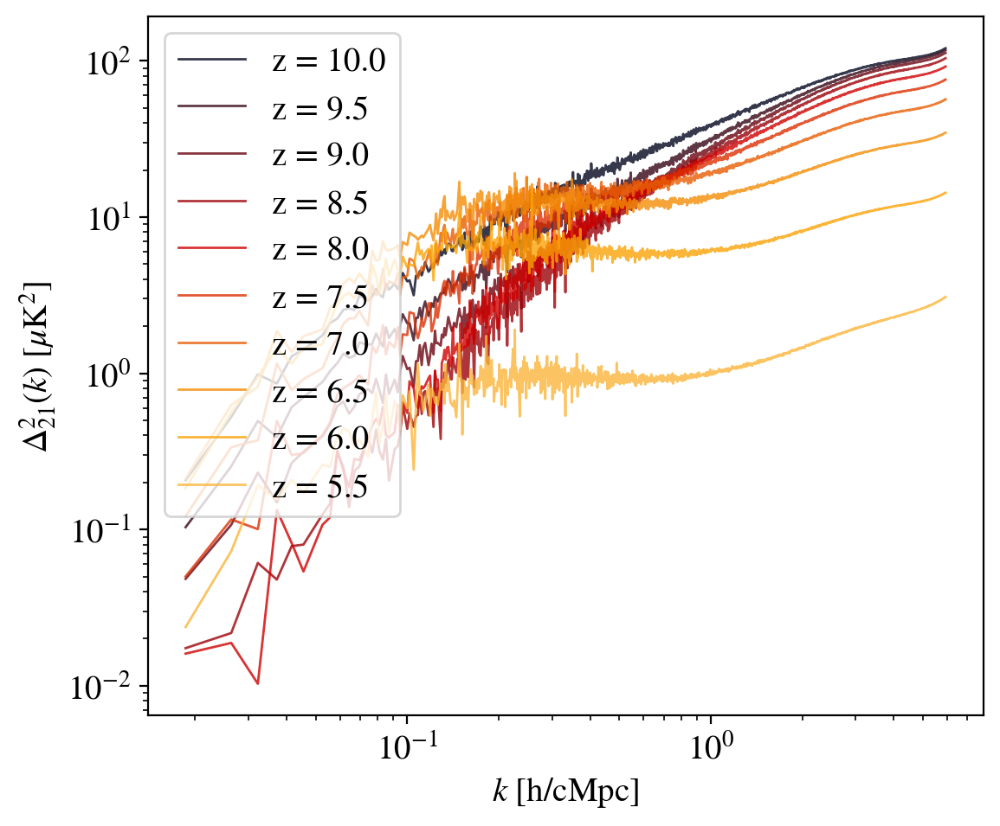

In [6]:
def load_ps(filename, h=0.6774, skiprows=5):
    """
    Load power spectrum file and return masked k, Delta^2, nmodes.
    """
    with open(filename) as f:
        lines = f.readlines()

        # Expected format (same as your original code)
        redshift = float(lines[0])
        mean = float(lines[2]) / float(lines[3])


    data = np.loadtxt(filename, skiprows=skiprows)

    k = data[:, 0]                  # h / ckpc
    delta2 = data[:, 1]             # mK^2
    nmodes = data[:, 3]
    #print(mean)
    delta2 *= mean*mean
    # convert k to physical units if needed
    
    k *= 1.0e3 # h / cMpc

    mask = nmodes > 0
    return k[mask], delta2[mask], nmodes[mask]

def plot_ps(ax, k, delta2, label=None, **kwargs):
    ax.loglog(k, delta2, lw=1, label=label, **kwargs)

zs = np.array([10.0, 9.5, 9.0, 8.5, 8.0, 7.5, 7.0, 6.5, 6.0, 5.5])

cmap = plt.get_cmap("plasma")  # or custom
norm = mpl.colors.Normalize(vmin=zs.min(), vmax=zs.max())

#/orcd/data/mvogelsb/004/chcho/PS_21cm
files = [
    ("./TS_TK/H/Tb/PS_Tb_H_156.out", "z = 10.0", "#03071e"),#, "#9467bd"),
    ("./TS_TK/H/Tb/PS_Tb_H_169.out", "z = 9.5", "#370617"),#, "#9467bd"),
    ("./TS_TK/H/Tb/PS_Tb_H_181.out", "z = 9.0", "#6a040f"),#, "#9467bd"),
    ("./TS_TK/H/Tb/PS_Tb_H_195.out", "z = 8.5", "#9d0208"),#, "#9467bd"),
    ("./TS_TK/H/Tb/PS_Tb_H_209.out", "z = 8.0", "#d00000"),#, "#9467bd"),
    ("./TS_TK/H/Tb/PS_Tb_H_224.out", "z = 7.5", "#dc2f02"),#, "#9467bd"),
    ("./TS_TK/H/Tb/PS_Tb_H_255.out", "z = 7.0", "#e85d04"),#, "#9467bd"),
    ("./TS_TK/H/Tb/PS_Tb_H_289.out", "z = 6.5", "#f48c06"),#, "#9467bd"),
    ("./TS_TK/H/Tb/PS_Tb_H_325.out", "z = 6.0", "#faa307"),#, "#9467bd"),
    ("./TS_TK/H/Tb/PS_Tb_H_364.out", "z = 5.5", "#fbb539"),#, "#9467bd"),
    #("./output/PS_H_z5.out", "z = 5.0"),#, "#9467bd"),
    #("./output/PS_H_z4.5.out", "z = 4.5"),#, "#9467bd"),
    #("./output/PS_H_z4.out", "z = 4.0"),#, "#9467bd"),
    #("./output/PS_H_z3.5.out", "z = 3.5"),#, "#9467bd"),
    #("./output/PS_H_z3.out", "z = 3.0"),#, "#9467bd"),
    #("PS_XL_Helium_160_z3.out", "XL, z = 3.0 (N = 160)", "#d62728"),
    #("PS_XL_Helium_80_z3.out", "XL, z = 3.0 (N = 80)", "#2ca02c"),
    #("dPS_XL_640.out", "XL, z = 6.3 (N = 640)", "#9467bd"),
    #("dPS_XL_320.out", "XL, z = 6.3 (N = 320)", "#8c564b"),
    #("dPS_XL_160.out", "XL, z = 6.3 (N = 160)", "#d62728"),
    #("dPS_XL_80.out", "XL, z = 6.3 (N = 80)", "#2ca02c"),
    #("PS_XL_640.out", "XL, z = 6.3 (N = 640)", "#9467bd"),PS_XL_Helium_80_z3.out
    #("PS_XL_320.out", "XL, z = 6.3 (N = 320)", "#8c564b"),
    #("PS_XL_160.out", "XL, z = 6.3 (N = 160)", "#d62728"),
    #("PS_XL_80.out", "XL, z = 6.3 (N = 80)", "#2ca02c"),
    #("PS_XL_640_fixed.out", "XL, z = 6.3 (N = 640, f_spin = 1)", "#9467bd"),
    #("PS_XL_320_fixed.out", "XL, z = 6.3 (N = 320, f_spin = 1)", "#8c564b"),
    #("PS_XL_160_fixed.out", "XL, z = 6.3 (N = 160, f_spin = 1)", "#d62728"),
    #("PS_XL_80_fixed.out", "XL, z = 6.3 (N = 80, f_spin = 1)", "#2ca02c"),
    #("/orcd/data/mvogelsb/004/chcho/PS_21cm/original/thesan2_ori_.out", "THESAN-2, z = 6.3 (N = 512)", "#1f77b4")
]

fig, ax = plt.subplots(figsize=(6, 5))

for fname, label, color in files:
        
    k, delta2, _ = load_ps(fname)
    plot_ps(ax, k, delta2, label=label, color=color, alpha=0.8)

ax.set_xlabel(r"$k\ [{\rm h/cMpc}]$")
##ax.set_ylabel(r"$\Delta^2_{21}(k)\ [{\rm mK}^2]$")
ax.set_ylabel(r"$\Delta^2_{21}(k)\ [\mu{\rm K}^2]$")
#ax.set_xlim(0.01, 2)

#ax.grid(True, which="both", ls="--", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## LUMINA Hydrogen PS

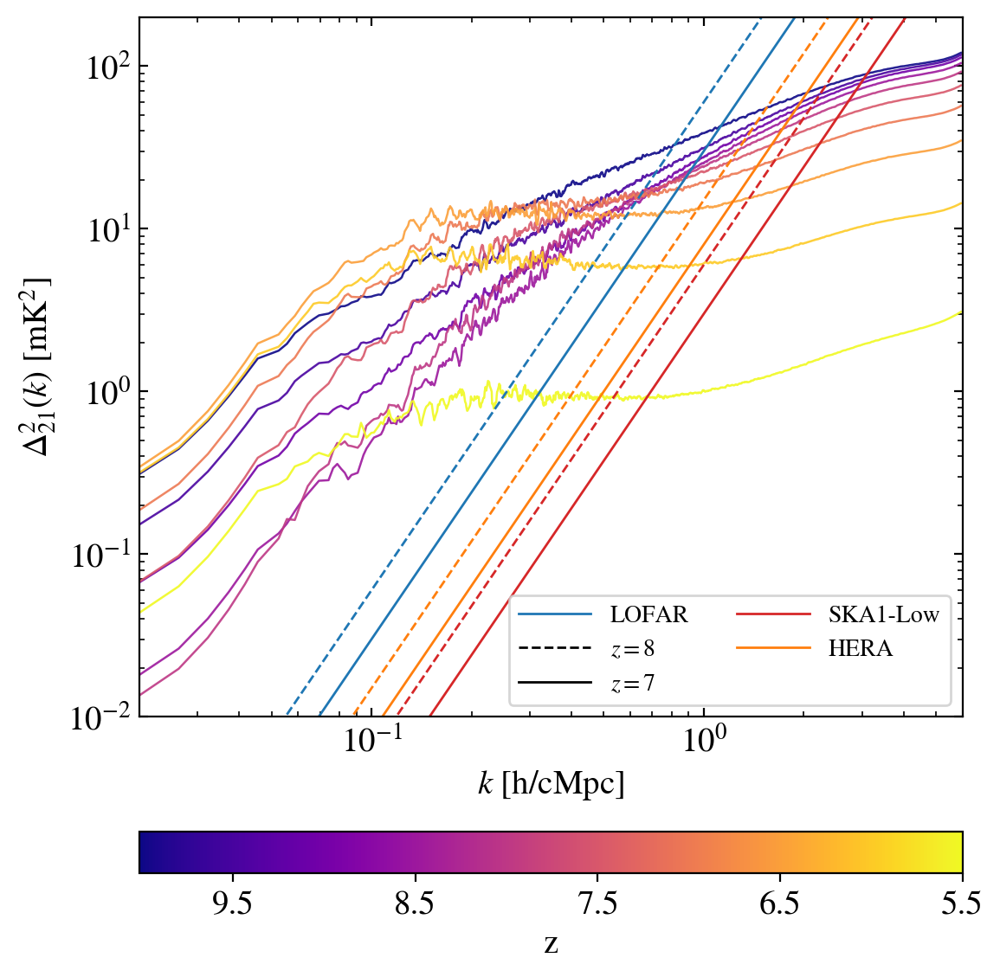

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.signal import savgol_filter



def load_ps(filename, h=0.6774, skiprows=5):
    """
    Load power spectrum file and return redshift, masked k, Delta^2, nmodes.
    """
    with open(filename) as f:
        lines = f.readlines()
        redshift = float(lines[0])
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k = data[:, 0]          # h / ckpc
    delta2 = data[:, 1]     # mK^2
    nmodes = data[:, 3]

    delta2 *= mean * mean
    k *= 1.0e3              # h / cMpc

    mask = nmodes > 0
    return redshift, k[mask], delta2[mask], nmodes[mask]


# Include down to z=3
files = [
    "./TS_TK/H/Tb/PS_Tb_H_156.out",
    "./TS_TK/H/Tb/PS_Tb_H_169.out",
    "./TS_TK/H/Tb/PS_Tb_H_181.out",
    "./TS_TK/H/Tb/PS_Tb_H_195.out",
    "./TS_TK/H/Tb/PS_Tb_H_209.out",
    "./TS_TK/H/Tb/PS_Tb_H_224.out",
    "./TS_TK/H/Tb/PS_Tb_H_255.out",
    "./TS_TK/H/Tb/PS_Tb_H_289.out",
    "./TS_TK/H/Tb/PS_Tb_H_325.out",
    "./TS_TK/H/Tb/PS_Tb_H_364.out",
    #"./output/PS_H_z5.out",
    #"./output/PS_H_z4.5.out",
    #"./output/PS_H_z4.out",
    #"./output/PS_H_z3.5.out",
    #"./output/PS_H_z3.out",
]

# Load everything once
ps_data = []
for fname in files:
    z, k, delta2, nmodes = load_ps(fname)
    ps_data.append((z, k, delta2))

# Sort by redshift (optional but cleaner)
ps_data.sort(key=lambda x: x[0], reverse=True)

zs = np.array([x[0] for x in ps_data])

# Colormap
cmap = plt.get_cmap("plasma_r")   # high z dark, low z bright
norm = mpl.colors.Normalize(vmin=zs.min(), vmax=zs.max())

fig, ax = plt.subplots(figsize=(6, 6))

for z, k, delta2 in ps_data:
    log_delta = np.log10(delta2) # added
    smooth_log = savgol_filter(log_delta, window_length=11, polyorder=2) # added
    delta2_smooth = 10**smooth_log # added
    
    ax.loglog(
        k,
        delta2_smooth, # was delta2
        color=cmap(norm(z)),
        lw=0.9,      # thinner lines
        alpha=0.9
    )





ax.set_xlabel(r"$k\ [{\rm h/cMpc}]$")
#ax.set_ylabel(r"$\Delta^2_{21}(k)\ [\mu{\rm K}^2]$")
ax.set_ylabel(r"$\Delta^2_{21}(k)\ [{\rm mK}^2]$")

# Optional limits (adjust as needed)
# ax.set_xlim(0.05, 3)

# Colorbar
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    orientation='horizontal',
    pad=0.12
)

cbar.set_label("z")
cbar.set_ticks(np.arange(5.5, 10., 1))

# 👇 Add this line
cbar.ax.invert_xaxis()


# --------------------------------
# Fake instrument sensitivity curves (for slides)
# --------------------------------

def instrument_curve(k, A, slope):
    return A * k**slope


k_noise = np.logspace(-1.8, 0.8, 200)

# Choose slopes similar to image (~ k^3 scaling)
slope = 3.0

# z = 7 (solid)
ax.loglog(k_noise, instrument_curve(k_noise, 3e1, slope),
          color="#1f77b4", lw=1, label="LOFAR")
ax.loglog(k_noise, instrument_curve(k_noise, 8e0, slope),
          color="#ff7f0e", lw=1, label="HERA")
ax.loglog(k_noise, instrument_curve(k_noise, 3e0, slope),
          color="#d62728", lw=1, label="SKA1-Low")

# z = 8 (dashed, slightly higher noise)
ax.loglog(k_noise, instrument_curve(k_noise, 6e1, slope),
          color="#1f77b4", lw=1, ls="--")
ax.loglog(k_noise, instrument_curve(k_noise, 1.5e1, slope),
          color="#ff7f0e", lw=1, ls="--")
ax.loglog(k_noise, instrument_curve(k_noise, 6e0, slope),
          color="#d62728", lw=1, ls="--")

ax.tick_params(
    which='both',
    direction='in',     # ticks go inward
    top=True,
    right=True
)

# Optional: make minor ticks visible on log axes
ax.minorticks_on()

from matplotlib.lines import Line2D

handles = [
    # Row 1
    Line2D([0], [0], color="#1f77b4", lw=1),          # LOFAR
    Line2D([0], [0], color="black", lw=1, ls="--"),  # z=8

    # Row 2
    Line2D([0], [0], color="black", lw=1, ls="-"),   # z=7
    Line2D([0], [0], color="#d62728", lw=1),         # SKA1-Low

    # Row 3
    Line2D([0], [0], color="#ff7f0e", lw=1),         # HERA
    Line2D([], [], linestyle="none"),                # blank cell
]

labels = [
    "LOFAR", r"$z=8$",
    r"$z=7$", "SKA1-Low",
    "HERA", ""
]

ax.legend(
    handles,
    labels,
    ncol=2,
    loc="lower right",
    frameon=True,
    handlelength=3,
    columnspacing=2.0,
    handletextpad=0.8,
    fontsize=10
)

ax.set_xlim(0.02, 6)
ax.set_ylim(0.01, 200)


plt.tight_layout()
plt.show()

## THESAN-1 Hydrogen PS

In [3]:
import bifft
import pickle
np.complex = complex

snap = 105 # redshift 10.01
file_path = f"./past/original/Thesan-1/H_Tb_{snap:03d}.hdf5"

with h5py.File(file_path, 'r') as f:
    # Assuming the data ranges from 0.0 (neutral) to 1.0 (ionized)
    dT_box = f["Tb"][:]

BOX_DIM = 1024
BOX_LEN = 95.5


pspec_dict = bifft.calculate_pspec(
    data=dT_box,
    DIM=[BOX_DIM],
    LEN=[BOX_LEN],
    normalise=True
)

print("k:", pspec_dict["k"][:5])
print("Pk:", pspec_dict["Pk"][:5])

plt.loglog(pspec_dict["k"], pspec_dict["Pk"], label="P(k)")
plt.fill_between(
    pspec_dict["k"],
    pspec_dict["Pk"] - pspec_dict["Pkerr"],
    pspec_dict["Pk"] + pspec_dict["Pkerr"],
    alpha=0.3
)

plt.xlabel("k")
plt.ylabel("P(k)")
plt.legend()
plt.show()

/home/chcho/.conda/envs/jupyter_env/lib/python3.14/site-packages/bifft/bispec_analysis.py:578: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  BS_cbar_str = "$B_{\mathrm{normed}}(k_1, k_2, k_3)$"


KeyboardInterrupt: 

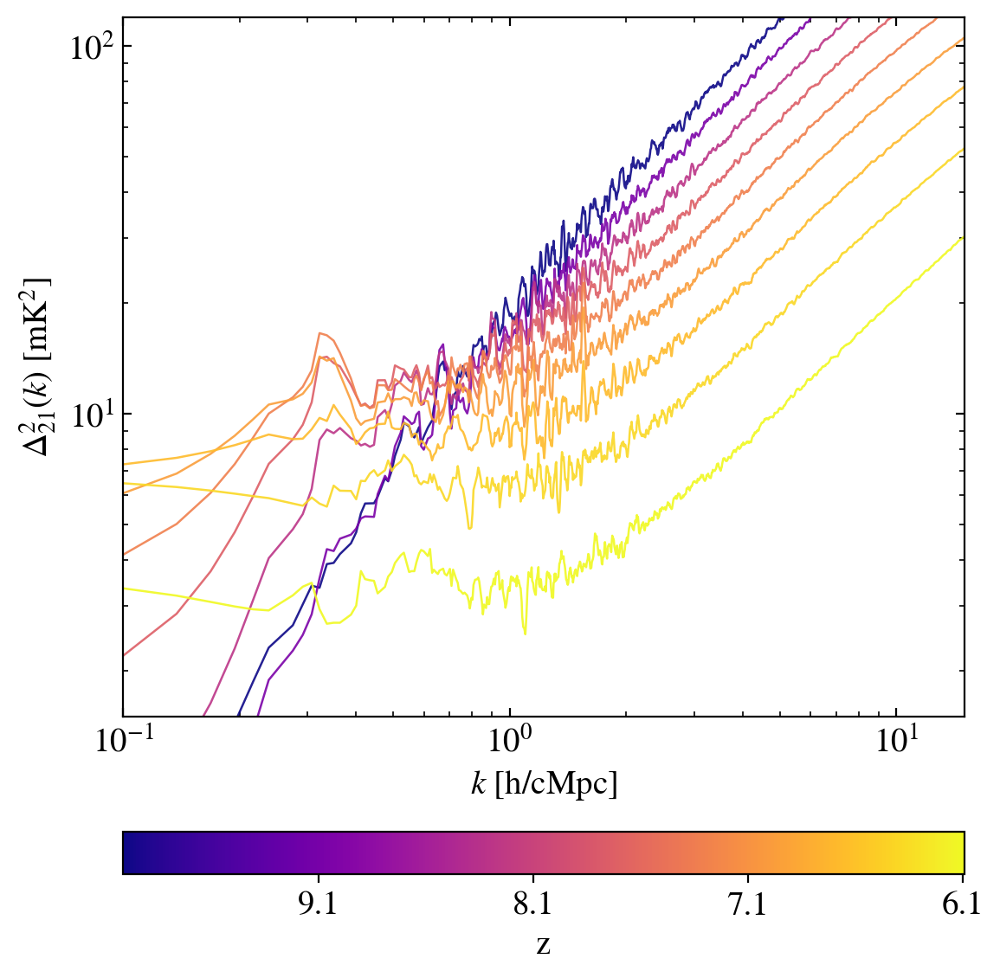

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.signal import savgol_filter



def load_ps(filename, h=0.6774, skiprows=5):
    """
    Load power spectrum file and return redshift, masked k, Delta^2, nmodes.
    """
    with open(filename) as f:
        lines = f.readlines()
        redshift = float(lines[0])
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k = data[:, 0]          # h / ckpc
    delta2 = data[:, 1]     # mK^2
    nmodes = data[:, 3]

    delta2 *= mean * mean
    k *= 1.0e3              # h / cMpc

    mask = nmodes > 0
    return redshift, k[mask], delta2[mask], nmodes[mask]


# Include down to z=3
path = "./past/original/Thesan-1/PS_H_Tb_"

snaps = [105, 137, 169, 196, 220, 242, 263, 285, 310]

files = [f"{path}{snap:03d}.out" for snap in snaps]


# Load everything once
ps_data = []
for fname in files:
    z, k, delta2, nmodes = load_ps(fname)
    ps_data.append((z, k, delta2))

# Sort by redshift (optional but cleaner)
ps_data.sort(key=lambda x: x[0], reverse=True)

zs = np.array([x[0] for x in ps_data])

# Colormap
cmap = plt.get_cmap("plasma_r")   # high z dark, low z bright
norm = mpl.colors.Normalize(vmin=zs.min(), vmax=zs.max())

fig, ax = plt.subplots(figsize=(6, 6))

for z, k, delta2 in ps_data:
    log_delta = np.log10(delta2) # added
    smooth_log = savgol_filter(log_delta, window_length=11, polyorder=2) # added
    delta2_smooth = 10**smooth_log # added
    
    ax.loglog(
        k,
        delta2_smooth, # was delta2
        color=cmap(norm(z)),
        lw=0.9,      # thinner lines
        alpha=0.9
    )





ax.set_xlabel(r"$k\ [{\rm h/cMpc}]$")
#ax.set_ylabel(r"$\Delta^2_{21}(k)\ [\mu{\rm K}^2]$")
ax.set_ylabel(r"$\Delta^2_{21}(k)\ [{\rm mK}^2]$")

# Optional limits (adjust as needed)
# ax.set_xlim(0.05, 3)

# Colorbar
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    orientation='horizontal',
    pad=0.12
)

cbar.set_label("z")
cbar.set_ticks(np.arange(6.1, 10., 1))

# 👇 Add this line
cbar.ax.invert_xaxis()



ax.tick_params(
    which='both',
    direction='in',     # ticks go inward
    top=True,
    right=True
)

# Optional: make minor ticks visible on log axes
ax.minorticks_on()

ax.set_xlim(0.1, 15)
ax.set_ylim(1.5, 120)


plt.tight_layout()
plt.show()

## THESAN-2 Hydrogen PS

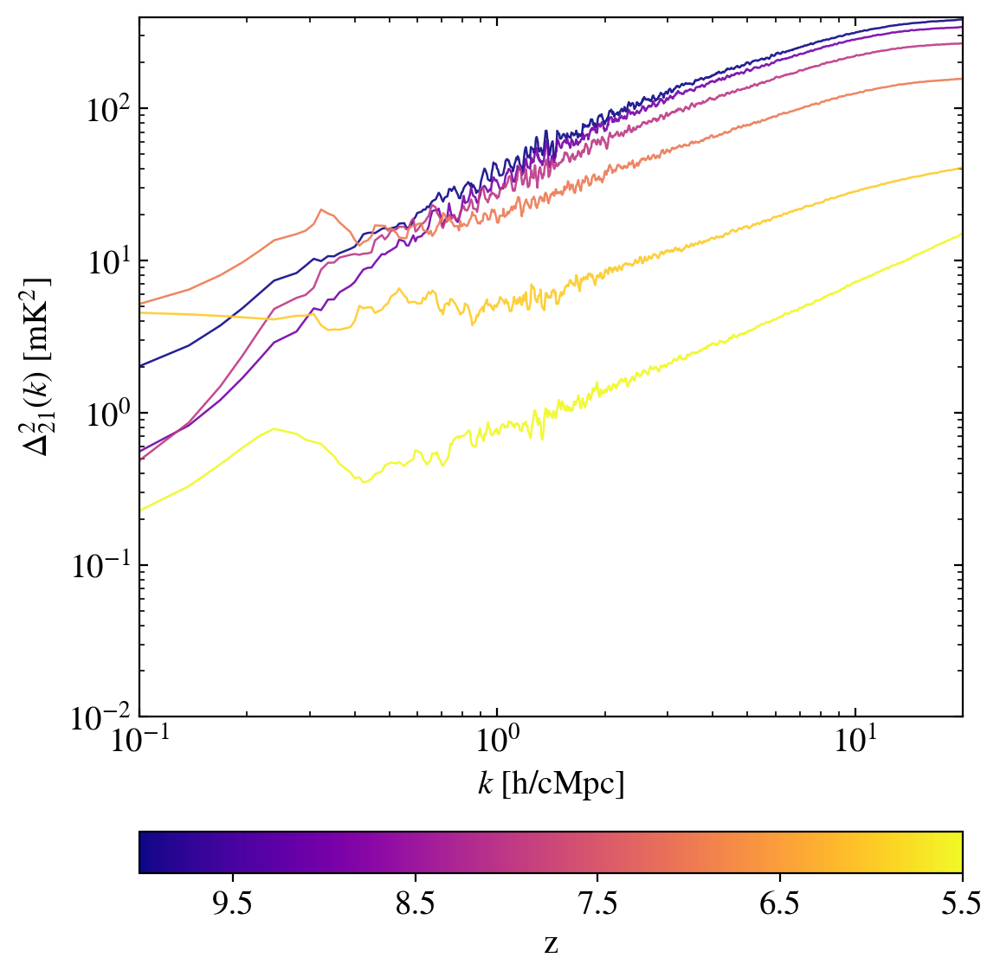

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.signal import savgol_filter



def load_ps(filename, h=0.6774, skiprows=5):
    """
    Load power spectrum file and return redshift, masked k, Delta^2, nmodes.
    """
    with open(filename) as f:
        lines = f.readlines()
        redshift = float(lines[0])
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k = data[:, 0]          # h / ckpc
    delta2 = data[:, 1]     # mK^2
    nmodes = data[:, 3]

    delta2 *= mean * mean
    k *= 1.0e3              # h / cMpc

    mask = nmodes > 0
    return redshift, k[mask], delta2[mask], nmodes[mask]


# Include down to z=3
path = "./past/original/Thesan-2/PS_H_Tb_"

snaps = [136, 170, 213, 271, 349, 400]

files = [f"{path}{snap:03d}.out" for snap in snaps]


# Load everything once
ps_data = []
for fname in files:
    z, k, delta2, nmodes = load_ps(fname)
    ps_data.append((z, k, delta2))

# Sort by redshift (optional but cleaner)
ps_data.sort(key=lambda x: x[0], reverse=True)

zs = np.array([x[0] for x in ps_data])

# Colormap
cmap = plt.get_cmap("plasma_r")   # high z dark, low z bright
norm = mpl.colors.Normalize(vmin=zs.min(), vmax=zs.max())

fig, ax = plt.subplots(figsize=(6, 6))

for z, k, delta2 in ps_data:
    log_delta = np.log10(delta2) # added
    smooth_log = savgol_filter(log_delta, window_length=11, polyorder=2) # added
    delta2_smooth = 10**smooth_log # added
    
    ax.loglog(
        k,
        delta2_smooth, # was delta2
        color=cmap(norm(z)),
        lw=0.9,      # thinner lines
        alpha=0.9
    )





ax.set_xlabel(r"$k\ [{\rm h/cMpc}]$")
#ax.set_ylabel(r"$\Delta^2_{21}(k)\ [\mu{\rm K}^2]$")
ax.set_ylabel(r"$\Delta^2_{21}(k)\ [{\rm mK}^2]$")

# Optional limits (adjust as needed)
# ax.set_xlim(0.05, 3)

# Colorbar
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    orientation='horizontal',
    pad=0.12
)

cbar.set_label("z")
cbar.set_ticks(np.arange(5.5, 10., 1))

# 👇 Add this line
cbar.ax.invert_xaxis()



ax.tick_params(
    which='both',
    direction='in',     # ticks go inward
    top=True,
    right=True
)

# Optional: make minor ticks visible on log axes
ax.minorticks_on()

ax.set_xlim(0.1, 20)
ax.set_ylim(0.01, 400)


plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.signal import savgol_filter



def load_ps(filename, h=0.6774, skiprows=5):
    """
    Load power spectrum file and return redshift, masked k, Delta^2, nmodes.
    """
    with open(filename) as f:
        lines = f.readlines()
        redshift = float(lines[0])
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k = data[:, 0]          # h / ckpc
    delta2 = data[:, 1]     # mK^2
    nmodes = data[:, 3]

    delta2 *= mean * mean
    k *= 1.0e3              # h / cMpc

    mask = nmodes > 0
    return redshift, k[mask], delta2[mask], nmodes[mask]


# Include down to z=3
files = [
    "./TK_ad/H/Tb/PS_H_ad_156.out",
    #"./TK_ad/H/Tb/PS_H_ad_169.out",
    "./TK_ad/H/Tb/PS_H_ad_181.out",
    #"./TK_ad/H/Tb/PS_H_ad_195.out",
    "./TK_ad/H/Tb/PS_H_ad_209.out",
    #"./TK_ad/H/Tb/PS_H_ad_224.out",
    "./TK_ad/H/Tb/PS_H_ad_255.out",
    "./TK_ad/H/Tb/PS_H_ad_289.out",
    "./TK_ad/H/Tb/PS_H_ad_325.out",
    "./TK_ad/H/Tb/PS_H_ad_364.out",
    #"./output/PS_H_z5.out",
    #"./output/PS_H_z4.5.out",
    #"./output/PS_H_z4.out",
    #"./output/PS_H_z3.5.out",
    #"./output/PS_H_z3.out",
]
#snaps = [156, 181, 209, 255, 289, 325, 364]
# Load everything once
ps_data = []
for fname in files:
    z, k, delta2, nmodes = load_ps(fname)
    ps_data.append((z, k, delta2))

# Sort by redshift (optional but cleaner)
ps_data.sort(key=lambda x: x[0], reverse=True)

zs = np.array([x[0] for x in ps_data])

# Colormap
cmap = plt.get_cmap("plasma_r")   # high z dark, low z bright
norm = mpl.colors.Normalize(vmin=zs.min(), vmax=zs.max())

fig, ax = plt.subplots(figsize=(6, 6))

for z, k, delta2 in ps_data:
    log_delta = np.log10(delta2) # added
    smooth_log = savgol_filter(log_delta, window_length=11, polyorder=2) # added
    delta2_smooth = 10**smooth_log # added
    
    ax.loglog(
        k,
        delta2_smooth, # was delta2
        color=cmap(norm(z)),
        lw=0.9,      # thinner lines
        alpha=0.9
    )





ax.set_xlabel(r"$k\ [{\rm h/cMpc}]$")
#ax.set_ylabel(r"$\Delta^2_{21}(k)\ [\mu{\rm K}^2]$")
ax.set_ylabel(r"$\Delta^2_{21}(k)\ [{\rm mK}^2]$")

# Optional limits (adjust as needed)
# ax.set_xlim(0.05, 3)

# Colorbar
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    orientation='horizontal',
    pad=0.12
)

cbar.set_label("z")
cbar.set_ticks(np.arange(5.5, 10., 1))

# 👇 Add this line
cbar.ax.invert_xaxis()


# --------------------------------
# Fake instrument sensitivity curves (for slides)
# --------------------------------

def instrument_curve(k, A, slope):
    return A * k**slope


k_noise = np.logspace(-1.8, 0.8, 200)

# Choose slopes similar to image (~ k^3 scaling)
slope = 3.0

# z = 7 (solid)
ax.loglog(k_noise, instrument_curve(k_noise, 3e1, slope),
          color="#1f77b4", lw=1, label="LOFAR")
ax.loglog(k_noise, instrument_curve(k_noise, 8e0, slope),
          color="#ff7f0e", lw=1, label="HERA")
ax.loglog(k_noise, instrument_curve(k_noise, 3e0, slope),
          color="#d62728", lw=1, label="SKA1-Low")

# z = 8 (dashed, slightly higher noise)
ax.loglog(k_noise, instrument_curve(k_noise, 6e1, slope),
          color="#1f77b4", lw=1, ls="--")
ax.loglog(k_noise, instrument_curve(k_noise, 1.5e1, slope),
          color="#ff7f0e", lw=1, ls="--")
ax.loglog(k_noise, instrument_curve(k_noise, 6e0, slope),
          color="#d62728", lw=1, ls="--")

ax.tick_params(
    which='both',
    direction='in',     # ticks go inward
    top=True,
    right=True
)

# Optional: make minor ticks visible on log axes
ax.minorticks_on()

from matplotlib.lines import Line2D

handles = [
    # Row 1
    Line2D([0], [0], color="#1f77b4", lw=1),          # LOFAR
    Line2D([0], [0], color="black", lw=1, ls="--"),  # z=8

    # Row 2
    Line2D([0], [0], color="black", lw=1, ls="-"),   # z=7
    Line2D([0], [0], color="#d62728", lw=1),         # SKA1-Low

    # Row 3
    Line2D([0], [0], color="#ff7f0e", lw=1),         # HERA
    Line2D([], [], linestyle="none"),                # blank cell
]

labels = [
    "LOFAR", r"$z=8$",
    r"$z=7$", "SKA1-Low",
    "HERA", ""
]

ax.legend(
    handles,
    labels,
    ncol=2,
    loc="lower right",
    frameon=True,
    handlelength=3,
    columnspacing=2.0,
    handletextpad=0.8,
    fontsize=10
)

ax.set_xlim(0.02, 6)
#ax.set_ylim(0.01, 200)
ax.set_ylim(10.0, 1.0e4)


plt.tight_layout()
plt.show()

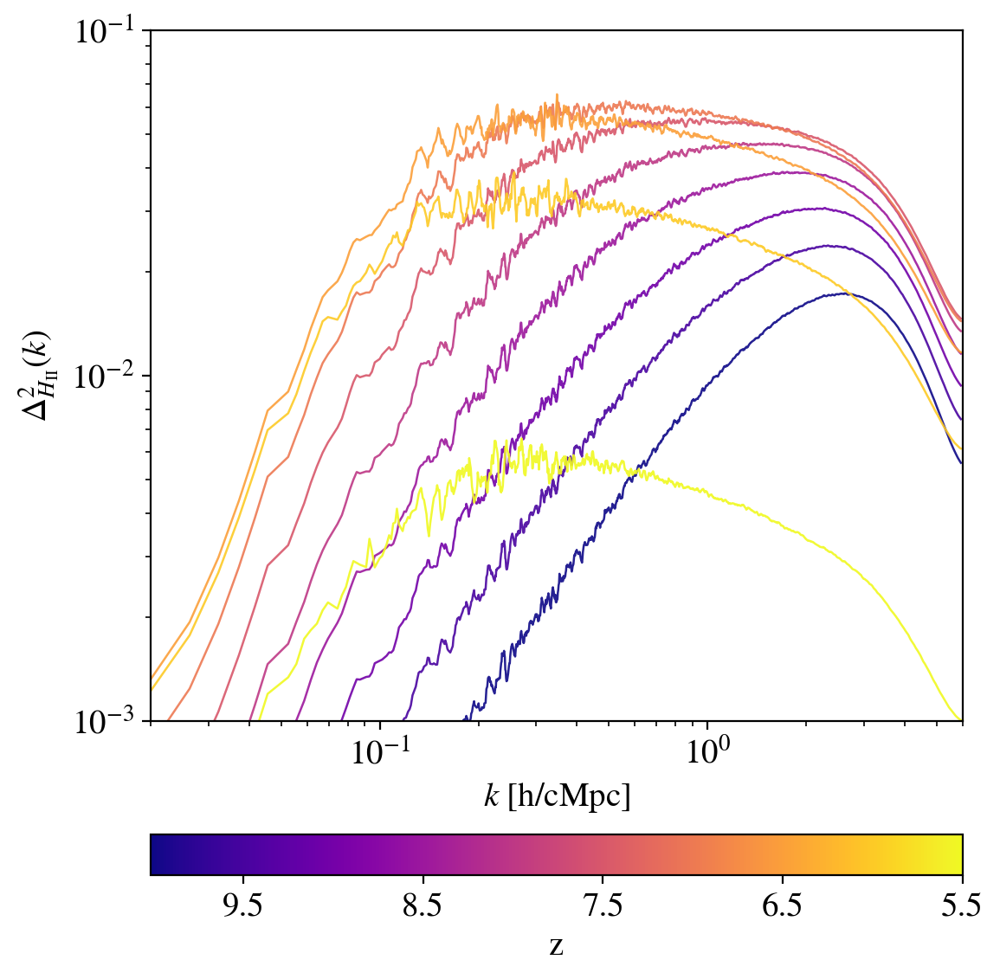

In [12]:




def load_ps(filename, h=0.6774, skiprows=5):
    """
    Load power spectrum file and return redshift, masked k, Delta^2, nmodes.
    """
    with open(filename) as f:
        lines = f.readlines()
        redshift = float(lines[0])
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k = data[:, 0]          # h / ckpc
    delta2 = data[:, 1]     # mK^2
    nmodes = data[:, 3]

    delta2 *= mean * mean
    k *= 1.0e3              # h / cMpc

    mask = nmodes > 0
    return redshift, k[mask], delta2[mask], nmodes[mask]


# Include down to z=3
files = [
    "./TS_TK/H/f_HII/PS_Tb_H_156.out",
    "./TS_TK/H/f_HII/PS_Tb_H_169.out",
    "./TS_TK/H/f_HII/PS_Tb_H_181.out",
    "./TS_TK/H/f_HII/PS_Tb_H_195.out",
    "./TS_TK/H/f_HII/PS_Tb_H_209.out",
    "./TS_TK/H/f_HII/PS_Tb_H_224.out",
    "./TS_TK/H/f_HII/PS_Tb_H_255.out",
    "./TS_TK/H/f_HII/PS_Tb_H_289.out",
    "./TS_TK/H/f_HII/PS_Tb_H_325.out",
    "./TS_TK/H/f_HII/PS_Tb_H_364.out",
    #"./output/PS_H_z5.out",
    #"./output/PS_H_z4.5.out",
    #"./output/PS_H_z4.out",
    #"./output/PS_H_z3.5.out",
    #"./output/PS_H_z3.out",
]

# Load everything once
ps_data = []
for fname in files:
    z, k, delta2, nmodes = load_ps(fname)
    ps_data.append((z, k, delta2))

# Sort by redshift (optional but cleaner)
ps_data.sort(key=lambda x: x[0], reverse=True)

zs = np.array([x[0] for x in ps_data])

# Colormap
cmap = plt.get_cmap("plasma_r")   # high z dark, low z bright
norm = mpl.colors.Normalize(vmin=zs.min(), vmax=zs.max())

fig, ax = plt.subplots(figsize=(6, 6))

for z, k, delta2 in ps_data:
    log_delta = np.log10(delta2) # added
    smooth_log = savgol_filter(log_delta, window_length=11, polyorder=2) # added
    delta2_smooth = 10**smooth_log # added
    
    ax.loglog(
        k,
        delta2_smooth, # was delta2
        color=cmap(norm(z)),
        lw=0.9,      # thinner lines
        alpha=0.9
    )

ax.set_xlabel(r"$k\ [{\rm h/cMpc}]$")
#ax.set_ylabel(r"$\Delta^2_{21}(k)\ [\mu{\rm K}^2]$")
ax.set_ylabel(r"$\Delta^2_{H_\mathrm{II}}(k)$")

# Optional limits (adjust as needed)
# ax.set_xlim(0.05, 3)

# Colorbar
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    orientation='horizontal',
    pad=0.12
)

cbar.set_label("z")
cbar.set_ticks(np.arange(5.5, 10., 1))

# 👇 Add this line
cbar.ax.invert_xaxis()


ax.set_xlim(0.02, 6)
ax.set_ylim(0.001, 0.1)


plt.tight_layout()
plt.show()

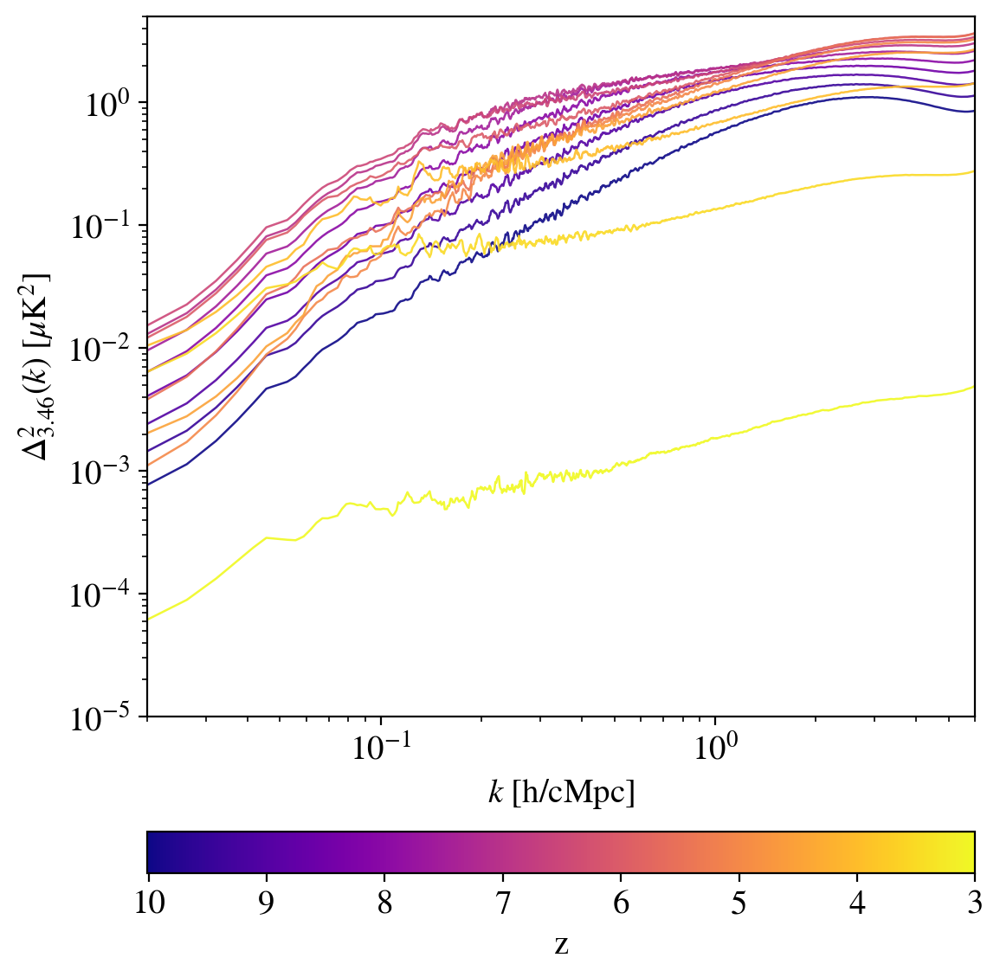

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl


def load_ps(filename, h=0.6774, skiprows=5):
    """
    Load power spectrum file and return redshift, masked k, Delta^2, nmodes.
    """
    with open(filename) as f:
        lines = f.readlines()
        redshift = float(lines[0])
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k = data[:, 0]          # h / ckpc
    delta2 = data[:, 1]     # mK^2
    nmodes = data[:, 3]

    delta2 *= mean * mean
    k *= 1.0e3              # h / cMpc

    mask = nmodes > 0
    return redshift, k[mask], delta2[mask], nmodes[mask]


# Include down to z=3
files = [
    "./TS_TK/He/Tb/PS_Tb_He_156.out",
    "./TS_TK/He/Tb/PS_Tb_He_169.out",
    "./TS_TK/He/Tb/PS_Tb_He_181.out",
    "./TS_TK/He/Tb/PS_Tb_He_195.out",
    "./TS_TK/He/Tb/PS_Tb_He_209.out",
    "./TS_TK/He/Tb/PS_Tb_He_224.out",
    "./TS_TK/He/Tb/PS_Tb_He_255.out",
    "./TS_TK/He/Tb/PS_Tb_He_289.out",
    "./TS_TK/He/Tb/PS_Tb_He_325.out",
    "./TS_TK/He/Tb/PS_Tb_He_364.out",
    "./TS_TK/He/Tb/PS_Tb_He_406.out",
    "./TS_TK/He/Tb/PS_Tb_He_452.out",
    "./TS_TK/He/Tb/PS_Tb_He_501.out",
    "./TS_TK/He/Tb/PS_Tb_He_582.out",
    "./TS_TK/He/Tb/PS_Tb_He_705.out",
]

# Load everything once
ps_data = []
for fname in files:
    z, k, delta2, nmodes = load_ps(fname)
    ps_data.append((z, k, delta2))

# Sort by redshift (optional but cleaner)
ps_data.sort(key=lambda x: x[0], reverse=True)

zs = np.array([x[0] for x in ps_data])

# Colormap
cmap = plt.get_cmap("plasma_r")   # high z dark, low z bright
norm = mpl.colors.Normalize(vmin=zs.min(), vmax=zs.max())

fig, ax = plt.subplots(figsize=(6, 6))


for z, k, delta2 in ps_data:
    log_delta = np.log10(delta2) # added
    smooth_log = savgol_filter(log_delta, window_length=11, polyorder=2) # added
    delta2_smooth = 10**smooth_log # added
    
    ax.loglog(
        k,
        delta2_smooth, # was delta2
        color=cmap(norm(z)),
        lw=0.9,      # thinner lines
        alpha=0.9
    )

ax.set_xlabel(r"$k\ [{\rm h/cMpc}]$")
ax.set_ylabel(r"$\Delta^2_{3.46}(k)\ [\mu{\rm K}^2]$")

# Optional limits (adjust as needed)
# ax.set_xlim(0.05, 3)

# Colorbar
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    orientation='horizontal',
    pad=0.12
)

cbar.set_label("z")
cbar.set_ticks(np.arange(3, 11., 1))

# 👇 Add this line
cbar.ax.invert_xaxis()


# Optional: make minor ticks visible on log axes
ax.minorticks_on()




ax.set_xlim(0.02, 6)
ax.set_ylim(1.0e-5, 5)


plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl


def load_ps(filename, h=0.6774, skiprows=5):
    """
    Load power spectrum file and return redshift, masked k, Delta^2, nmodes.
    """
    with open(filename) as f:
        lines = f.readlines()
        redshift = float(lines[0])
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k = data[:, 0]          # h / ckpc
    delta2 = data[:, 1]     # mK^2
    nmodes = data[:, 3]

    delta2 *= mean * mean
    k *= 1.0e3              # h / cMpc

    mask = nmodes > 0
    return redshift, k[mask], delta2[mask], nmodes[mask]


# Include down to z=3
files = [
    "./TS_TK/He/f_HeIII/PS_He_156.out",
    "./TS_TK/He/f_HeIII/PS_He_169.out",
    "./TS_TK/He/f_HeIII/PS_He_181.out",
    "./TS_TK/He/f_HeIII/PS_He_195.out",
    "./TS_TK/He/f_HeIII/PS_He_209.out",
    "./TS_TK/He/f_HeIII/PS_He_224.out",
    "./TS_TK/He/f_HeIII/PS_He_255.out",
    "./TS_TK/He/f_HeIII/PS_He_289.out",
    "./TS_TK/He/f_HeIII/PS_He_325.out",
    "./TS_TK/He/f_HeIII/PS_He_364.out",
    "./TS_TK/He/f_HeIII/PS_He_406.out",
    "./TS_TK/He/f_HeIII/PS_He_452.out",
    "./TS_TK/He/f_HeIII/PS_He_501.out",
    "./TS_TK/He/f_HeIII/PS_He_582.out",
    "./TS_TK/He/f_HeIII/PS_He_705.out",
]

# Load everything once
ps_data = []
for fname in files:
    z, k, delta2, nmodes = load_ps(fname)
    ps_data.append((z, k, delta2))

# Sort by redshift (optional but cleaner)
ps_data.sort(key=lambda x: x[0], reverse=True)

zs = np.array([x[0] for x in ps_data])

# Colormap
cmap = plt.get_cmap("plasma_r")   # high z dark, low z bright
norm = mpl.colors.Normalize(vmin=zs.min(), vmax=zs.max())

fig, ax = plt.subplots(figsize=(6, 6))


for z, k, delta2 in ps_data:
    log_delta = np.log10(delta2) # added
    smooth_log = savgol_filter(log_delta, window_length=11, polyorder=2) # added
    delta2_smooth = 10**smooth_log # added
    
    ax.loglog(
        k,
        delta2_smooth, # was delta2
        color=cmap(norm(z)),
        lw=0.9,      # thinner lines
        alpha=0.9
    )

ax.set_xlabel(r"$k\ [{\rm h/cMpc}]$")
ax.set_ylabel(r"$\Delta^2_{He_\mathrm{III}(k)}$")

# Optional limits (adjust as needed)
# ax.set_xlim(0.05, 3)

# Colorbar
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(
    sm,
    ax=ax,
    orientation='horizontal',
    pad=0.12
)

cbar.set_label("z")
cbar.set_ticks(np.arange(3, 11., 1))

# 👇 Add this line
cbar.ax.invert_xaxis()


# Optional: make minor ticks visible on log axes
ax.minorticks_on()




ax.set_xlim(0.02, 6)
ax.set_ylim(1.0e-10, 1.0e-3)


plt.tight_layout()
plt.show()

In [2]:
import pandas as pd

cols = [
    "i", "j", "k", "z",
    "mass_gas_dvdr", "mass_gas", "global_rho_gas",
    "T_gas", "SFRD",
    "T_CMB", "spin_factor",
    "f_HII", "f_HeII", "rin"
]

df = pd.read_csv(
    "rin_debug_rank0.txt",
    #"rin_21cm_rank0.txt",
    delim_whitespace=True,
    names=cols,
    comment="#"
)

/tmp/ipykernel_1880131/1340549415.py:11: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(


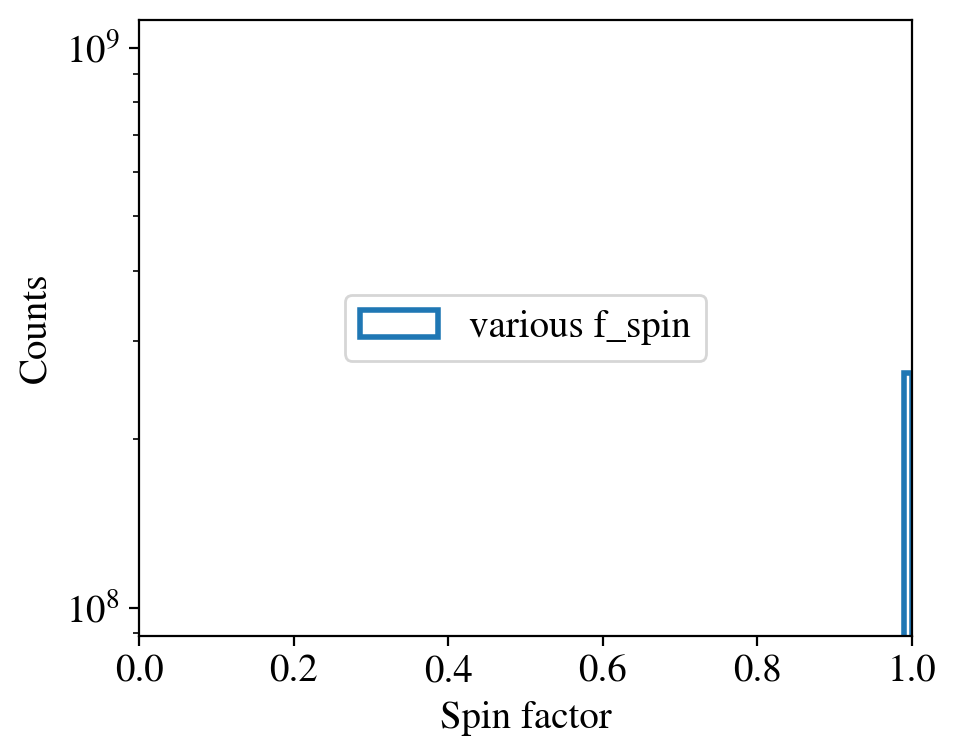

In [4]:
plt.figure(figsize=(5, 4))

plt.hist(
    df["spin_factor"],
    bins=100,
    range=(0, 1),
    histtype="step",
    linewidth=2,
    label="various f_spin"
)
#plt.hist(
#    df_fixed["spin_factor"],
#    bins=100,
#    range=(0, 1),
#    histtype="step",
#    linewidth=2,
#    label="fixed f_spin"
#)

plt.xlabel("Spin factor")
plt.ylabel("Counts")
plt.yscale("log")
plt.xlim(0, 1)

plt.tight_layout()
plt.legend(loc="center")
plt.show()

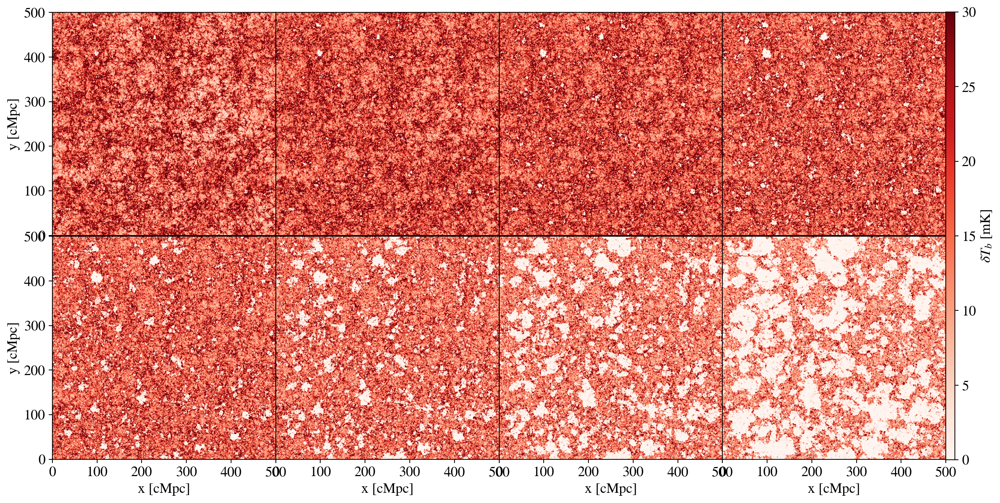

In [44]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import TwoSlopeNorm

# snapshots to show
snaps = [156,169,181,195,209,224,255,289]

fig = plt.figure(figsize=(16,8))

gs = gridspec.GridSpec(
    2,5,
    width_ratios=[1,1,1,1,0.04],
    wspace=0,
    hspace=0
)

axes = []

# create map panels
for i in range(2):
    for j in range(4):
        axes.append(fig.add_subplot(gs[i,j]))

# colorbar axis
cax = fig.add_subplot(gs[:,4])

# color normalization
norm = TwoSlopeNorm(
    vmin=0,
    vcenter=15,
    vmax=30
)

# -----------------------
# Load and plot maps
# -----------------------

for i, snap in enumerate(snaps):

    hdf5_file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_{snap:03d}.hdf5"

    with h5py.File(hdf5_file,"r") as f:
        Tb_cube = f["/rin"][:]

    N = Tb_cube.shape[0]
    k_slice = N // 2
    Tb = Tb_cube[:,:,k_slice]

    ax = axes[i]

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap="Reds",
        norm=norm,
        extent=[0,500,0,500],
        #interpolation="nearest"
    )

    # remove borders
    #for spine in ax.spines.values():
    #    spine.set_visible(Ture)

    # remove ticks
    ax.set_xticks([])
    ax.set_yticks([])

# -----------------------
# Outer axis labels only
# -----------------------

# bottom row x ticks
for ax in axes[4:]:
    ax.set_xticks([0,100,200,300,400,500])
    ax.set_xlabel("x [cMpc]")

# left column y ticks
axes[0].set_yticks([0,100,200,300,400,500])
axes[4].set_yticks([0,100,200,300,400,500])

axes[0].set_ylabel("y [cMpc]")
axes[4].set_ylabel("y [cMpc]")

# -----------------------
# Colorbar
# -----------------------

cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r"$\delta T_b\ [\mathrm{mK}]$")

plt.savefig("Tb_map_grid.png", dpi=300)
plt.show()

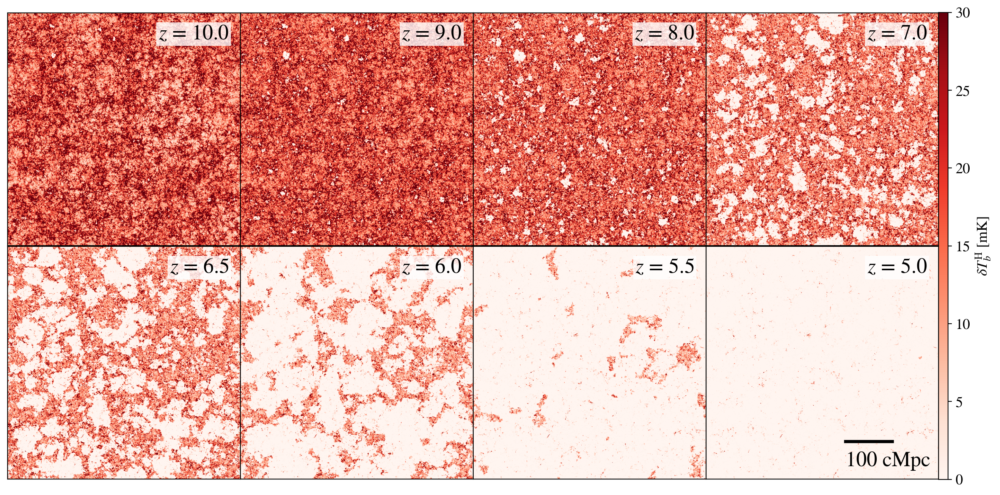

In [22]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import TwoSlopeNorm
import re

def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())

# -----------------------------------
# Extract snapshot numbers from PS files
# -----------------------------------

files = [
    "./TS_TK/H/Tb/PS_Tb_H_156.out",
    #"./TS_TK/H/Tb/PS_Tb_H_169.out",
    "./TS_TK/H/Tb/PS_Tb_H_181.out",
    #"./TS_TK/H/Tb/PS_Tb_H_195.out",
    "./TS_TK/H/Tb/PS_Tb_H_209.out",
    #"./TS_TK/H/Tb/PS_Tb_H_224.out",
    "./TS_TK/H/Tb/PS_Tb_H_255.out",
    "./TS_TK/H/Tb/PS_Tb_H_289.out",
    "./TS_TK/H/Tb/PS_Tb_H_325.out",
    "./TS_TK/H/Tb/PS_Tb_H_364.out",
    "./TS_TK/H/Tb/PS_Tb_H_406.out",
    #"./TS_TK/H/Tb/PS_Tb_H_452.out",
    #"./TS_TK/H/Tb/PS_Tb_H_501.out",
    #"./TS_TK/H/Tb/PS_Tb_H_582.out",
    #"./TS_TK/H/Tb/PS_Tb_H_705.out",
]


snaps = [int(re.search(r'_(\d+)\.out', f).group(1)) for f in files]
snaps = snaps[:8]

# -----------------------------------
# Figure layout
# -----------------------------------

fig = plt.figure(figsize=(16,8))

gs = gridspec.GridSpec(
    2,5,
    width_ratios=[1,1,1,1,0.04],
    wspace=0,
    hspace=0
)

axes = [fig.add_subplot(gs[i,j]) for i in range(2) for j in range(4)]
cax = fig.add_subplot(gs[:,4])

# -----------------------------------
# Hydrogen Tb normalization
# -----------------------------------

norm = TwoSlopeNorm(
    vmin=0,
    vcenter=15,
    vmax=30
)

# -----------------------------------
# Load hydrogen maps
# -----------------------------------

for i, snap in enumerate(snaps):

    hdf5_file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_{snap:03d}.hdf5"
    PS_file   = f"./TS_TK/H/Tb/PS_Tb_H_{snap:03d}.out"

    z = get_redshift(PS_file)

    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/rin"][:]

    N = Tb_cube.shape[0]
    Tb = Tb_cube[:, :, N//2]

    ax = axes[i]

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap="Reds",
        norm=norm,
        extent=[0,500,0,500]
    )

    # remove ticks completely
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xticklabels([])
    ax.set_yticklabels([])

    # redshift label
    ax.text(
        0.95, 0.95,
        fr"$z$ = {z:.1f}",
        transform=ax.transAxes,
        color="black",
        fontsize=20,
        ha="right",
        va="top",
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=2)
    )

# -----------------------------------
# Scale bar (same as helium)
# -----------------------------------

bar_length = 100
x0, y0 = 300, 80

ax.plot([x0, x0 + bar_length], [y0, y0], color="black", lw=3)

ax.text(
    x0,
    y0 - 20,
    "100 cMpc",
    color="black",
    fontsize=20,
    va="top"
)

# -----------------------------------
# Colorbar
# -----------------------------------

cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r"$\delta T_b^{\mathrm{H}}\ [\mathrm{mK}]$")

plt.show()

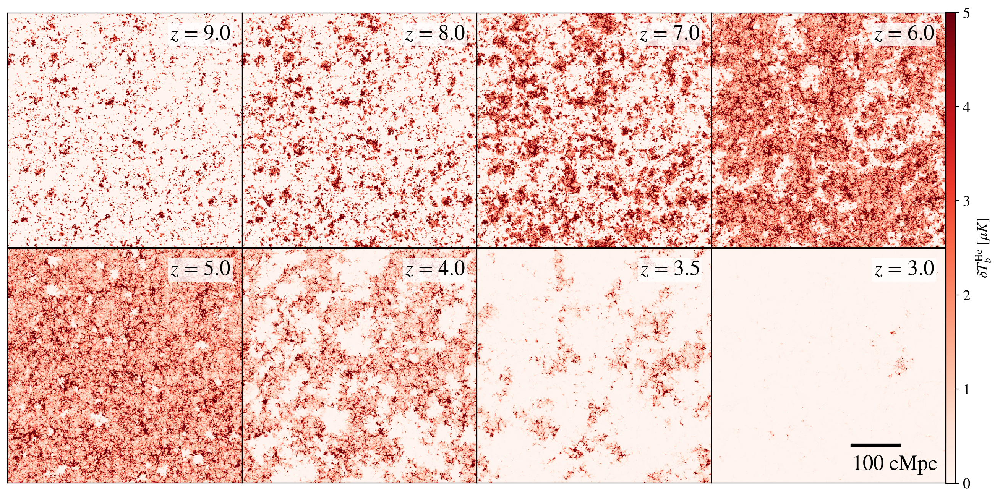

In [6]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import TwoSlopeNorm
import re

def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())

# -----------------------------------
# Extract snapshot numbers from PS files
# -----------------------------------

files = [
    #"./TS_TK/He/Tb/PS_Tb_He_156.out",
    #"./TS_TK/He/Tb/PS_Tb_He_169.out",
    "./TS_TK/He/Tb/PS_Tb_He_181.out",
    #"./TS_TK/He/Tb/PS_Tb_He_195.out",
    "./TS_TK/He/Tb/PS_Tb_He_209.out",
    #"./TS_TK/He/Tb/PS_Tb_He_224.out",
    "./TS_TK/He/Tb/PS_Tb_He_255.out",
    #"./TS_TK/He/Tb/PS_Tb_He_289.out",
    "./TS_TK/He/Tb/PS_Tb_He_325.out",
    #"./TS_TK/He/Tb/PS_Tb_He_364.out",
    "./TS_TK/He/Tb/PS_Tb_He_406.out",
    #"./TS_TK/He/Tb/PS_Tb_He_452.out",
    "./TS_TK/He/Tb/PS_Tb_He_501.out",
    "./TS_TK/He/Tb/PS_Tb_He_582.out",
    "./TS_TK/He/Tb/PS_Tb_He_705.out",
]

# extract snapshot numbers
snaps = [int(re.search(r'_(\d+)\.out', f).group(1)) for f in files]

# take first 8
snaps = snaps[:8]

# -----------------------------------
# Figure layout
# -----------------------------------

fig = plt.figure(figsize=(16,8))

gs = gridspec.GridSpec(
    2,5,
    width_ratios=[1,1,1,1,0.04],
    wspace=0,
    hspace=0
)

axes = []

for i in range(2):
    for j in range(4):
        axes.append(fig.add_subplot(gs[i,j]))

cax = fig.add_subplot(gs[:,4])

# -----------------------------------
# Helium brightness temperature scale
# -----------------------------------

norm = TwoSlopeNorm(
    vmin=0,
    vcenter=2.5,
    vmax=5
)

# -----------------------------------
# Load helium maps
# -----------------------------------

for i, snap in enumerate(snaps[:]):
    
    hdf5_file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/He/Tb/Tb_He_{snap:03d}.hdf5"
    PS_file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/He/Tb/PS_Tb_He_{snap:03d}.out"
    

    z = get_redshift(PS_file)
    

    with h5py.File(hdf5_file,"r") as f:
        Tb_cube = f["/rin"][:]

    N = Tb_cube.shape[0]
    k_slice = N // 2
    Tb = Tb_cube[:,:,k_slice]

    ax = axes[i]

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap="Reds",
        norm=norm,
        extent=[0,500,0,500]
    )

    # remove ticks
    ax.set_xticks([])
    ax.set_yticks([])

    ax.text(
    0.95, 0.95,
    fr"$z$ = {z:.1f}",
    transform=ax.transAxes,
    color="black",
    fontsize=20,
    ha="right",
    va="top",
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=2)
    )

# -----------------------------------
# Outer axis labels
# -----------------------------------

#for ax in axes[4:]:
#    ax.set_xticks([0,100,200,300,400,500])
#    ax.set_xlabel("x [cMpc]")

#axes[0].set_yticks([0,100,200,300,400,500])
#axes[4].set_yticks([0,100,200,300,400,500])

#axes[0].set_ylabel("y [cMpc]")
#axes[4].set_ylabel("y [cMpc]")

# remove ALL ticks and labels
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xticklabels([])
    ax.set_yticklabels([])

# --- scale bar ---
bar_length = 100  # cMpc
x0 = 300           # starting position
y0 = 80          # near top

ax.plot(
    [x0, x0 + bar_length],
    [y0, y0],
    color="black",
    lw=3
)

ax.text(
    x0,
    y0 - 20,
    "100 cMpc",
    color="black",
    fontsize=20,
    va="top"
)

# -----------------------------------
# Colorbar
# -----------------------------------

cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r"$\delta T_b^{\mathrm{He}}\ [\mu K]$")

#plt.savefig("Tb_He_map_grid.png", dpi=300)
plt.show()

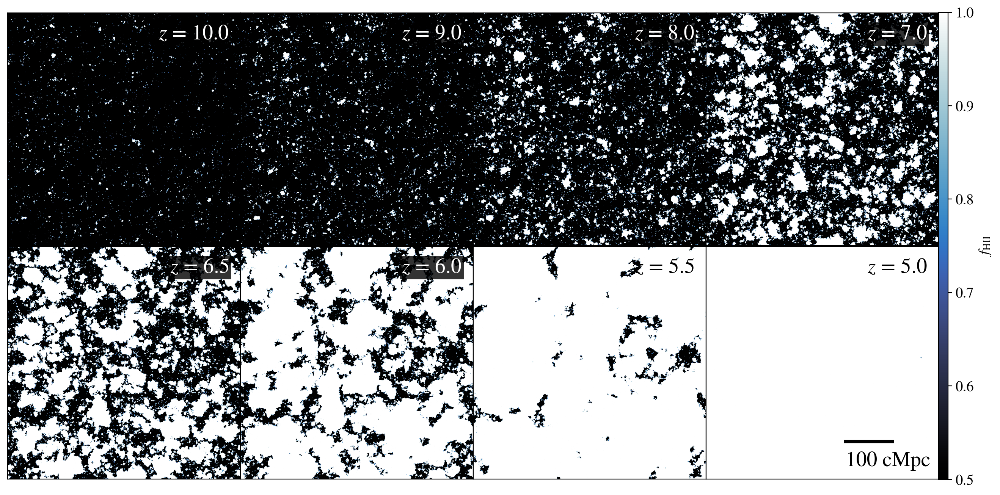

In [74]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize

def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())

# -----------------------------------
# SNAPSHOTS (your selection)
# -----------------------------------

snaps = [156, 181, 209, 255, 289, 325, 364, 406]

#"./TS_TK/H/Tb/PS_Tb_H_156.out",
    #"./TS_TK/H/Tb/PS_Tb_H_169.out",
 #   "./TS_TK/H/Tb/PS_Tb_H_181.out",
    #"./TS_TK/H/Tb/PS_Tb_H_195.out",
  #  "./TS_TK/H/Tb/PS_Tb_H_209.out",
    #"./TS_TK/H/Tb/PS_Tb_H_224.out",
   # "./TS_TK/H/Tb/PS_Tb_H_255.out",
    #"./TS_TK/H/Tb/PS_Tb_H_289.out",
    #"./TS_TK/H/Tb/PS_Tb_H_325.out",
    #"./TS_TK/H/Tb/PS_Tb_H_364.out",
    #"./TS_TK/H/Tb/PS_Tb_H_406.out",

# -----------------------------------
# FIGURE LAYOUT
# -----------------------------------

fig = plt.figure(figsize=(16,8))

gs = gridspec.GridSpec(
    2,5,
    width_ratios=[1,1,1,1,0.04],
    wspace=0,
    hspace=0
)

axes = [fig.add_subplot(gs[i,j]) for i in range(2) for j in range(4)]
cax = fig.add_subplot(gs[:,4])

# -----------------------------------
# NORMALIZATION
# -----------------------------------

threshold = 0.5
norm = Normalize(vmin=threshold, vmax=1.0)

# -----------------------------------
# LOAD HII MAPS
# -----------------------------------

for i, snap in enumerate(snaps):

    # ----------- PATH SWITCH -----------
    if snap <= 428:
        hdf5_file = f"/orcd/data/mvogelsb/005/mkilab001/mvogelsblab003/Lab/Thesan-XL/Flagship_new/postprocessing/ren_640/HII_VolumeFraction/HII_VolumeFraction_{snap:03d}.hdf5"
    else:
        hdf5_file = f"/orcd/data/mvogelsb/005/mkilab001/mvogelsblab003/Lab/Thesan-XL/Flagship_below_z_4p75_new/postprocessing/ren_640/HII_VolumeFraction/HII_VolumeFraction_{snap:03d}.hdf5"

    # ----------- REDSHIFT FILE (still He is fine if same snapshots) -----------
    PS_file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/PS_Tb_H_{snap:03d}.out"
    z = get_redshift(PS_file)

    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/HII_VolumeFraction"][:]   # <-- changed here

    # ----------- SLICE -----------
    N = Tb_cube.shape[0]
    Tb = Tb_cube[:, :, N//2]

    # ----------- MASK LOW VALUES -----------
    Tb_plot = np.ma.masked_less(Tb, threshold)

    ax = axes[i]
    ax.set_facecolor("black")

    im = ax.imshow(
        Tb_plot.T,
        origin="lower",
        cmap=cmr.arctic,  #"cosmic",
        norm=norm,
        extent=[0,500,0,500]
    )

    # remove ticks
    ax.set_xticks([])
    ax.set_yticks([])

    # ----------- TEXT STYLE -----------
    text_color = "white" if i < 6 else "black"
    bbox = dict(facecolor='black', alpha=0.8, edgecolor='none', pad=2) if i < 6 else None

    ax.text(
        0.95, 0.95,
        fr"$z$ = {z:.1f}",
        transform=ax.transAxes,
        color=text_color,
        fontsize=20,
        ha="right",
        va="top",
        bbox=bbox
    )

# -----------------------------------
# REMOVE ALL TICKS
# -----------------------------------

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xticklabels([])
    ax.set_yticklabels([])

# -----------------------------------
# SCALE BAR (LAST PANEL)
# -----------------------------------

ax = axes[-1]

bar_length = 100
x0, y0 = 300, 80

ax.plot([x0, x0 + bar_length], [y0, y0], color="black", lw=3)

ax.text(
    x0,
    y0 - 20,
    "100 cMpc",
    color="black",
    fontsize=20,
    va="top"
)

# -----------------------------------
# COLORBAR
# -----------------------------------

cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r"$f_{\mathrm{HII}}$")
plt.savefig("f_hydro.png", dpi=200, bbox_inches="tight")

plt.show()

In [27]:
HYDROGEN_MASSFRAC = 0.76 # global hydrogen mass fraction
y_frac = (1.0 - HYDROGEN_MASSFRAC) / (4.0 * HYDROGEN_MASSFRAC)

y_frac

0.07894736842105263

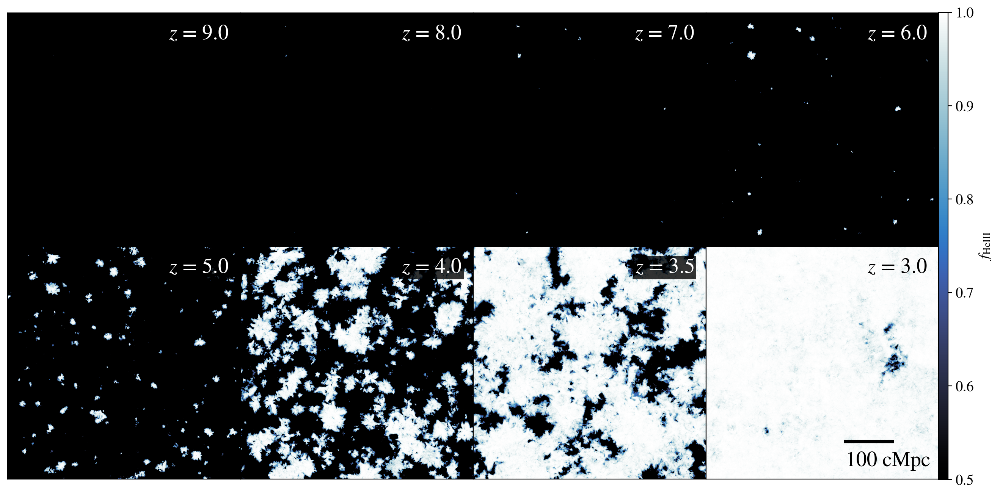

In [73]:
# CONSIDER Y_FRAC!!!
HYDROGEN_MASSFRAC = 0.76 # global hydrogen mass fraction
y_frac = (1.0 - HYDROGEN_MASSFRAC) / (4.0 * HYDROGEN_MASSFRAC)


import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
import re

def get_redshift(ps_file):
    with open(ps_file) as f:
        return float(f.readline().strip())

# -----------------------------------
# Extract snapshot numbers from PS files
# -----------------------------------

files = [
    #"./TS_TK/He/Tb/PS_Tb_He_156.out",
    "./TS_TK/He/Tb/PS_Tb_He_181.out",
    "./TS_TK/He/Tb/PS_Tb_He_209.out",
    "./TS_TK/He/Tb/PS_Tb_He_255.out",
    "./TS_TK/He/Tb/PS_Tb_He_325.out",
    "./TS_TK/He/Tb/PS_Tb_He_406.out",
    "./TS_TK/He/Tb/PS_Tb_He_501.out",
    "./TS_TK/He/Tb/PS_Tb_He_582.out",
    "./TS_TK/He/Tb/PS_Tb_He_705.out",
]

snaps = [int(re.search(r'_(\d+)\.out', f).group(1)) for f in files]
snaps = snaps[:8]

# -----------------------------------
# Figure layout
# -----------------------------------

fig = plt.figure(figsize=(16,8))

gs = gridspec.GridSpec(
    2,5,
    width_ratios=[1,1,1,1,0.04],
    wspace=0,
    hspace=0
)

axes = []

for i in range(2):
    for j in range(4):
        axes.append(fig.add_subplot(gs[i,j]))

cax = fig.add_subplot(gs[:,4])

# -----------------------------------
# Load helium maps
# -----------------------------------

threshold = 0.5

for i, snap in enumerate(snaps[:]):

    if snap <= 428:
        hdf5_file = f"/orcd/data/mvogelsb/005/mkilab001/mvogelsblab003/Lab/Thesan-XL/Flagship_new/postprocessing/ren_640/HeIII_VolumeFraction/HeIII_VolumeFraction_{snap:03d}.hdf5"
    else:
        hdf5_file = f"/orcd/data/mvogelsb/005/mkilab001/mvogelsblab003/Lab/Thesan-XL/Flagship_below_z_4p75_new/postprocessing/ren_640/HeIII_VolumeFraction/HeIII_VolumeFraction_{snap:03d}.hdf5"

    PS_file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/He/Tb/PS_Tb_He_{snap:03d}.out"
    z = get_redshift(PS_file)

    with h5py.File(hdf5_file,"r") as f:
        Tb_cube = f["/HeIII_VolumeFraction"][:]/y_frac

    N = Tb_cube.shape[0]
    k_slice = N // 2
    Tb = Tb_cube[:,:,k_slice]

    # ---------------------------
    # APPLY THRESHOLD HERE
    # ---------------------------
    Tb_plot = np.ma.masked_less(Tb, threshold)

    norm = Normalize(vmin=threshold, vmax=1.0)

    ax = axes[i]
    ax.set_facecolor("black")

    im = ax.imshow(
        Tb_plot.T,
        origin="lower",
        cmap=cmr.arctic,
        norm=norm,
        extent=[0,500,0,500]
    )

    ax.set_xticks([])
    ax.set_yticks([])

    # ---------------------------
    # FONT COLOR CONTROL
    # ---------------------------
    text_color = "white" if i < 7 else "black"
    bbox=dict(facecolor='black', alpha=0.8, edgecolor='none', pad=2) if i < 7 else None
    
    ax.text(
        0.95, 0.95,
        fr"$z$ = {z:.1f}",
        transform=ax.transAxes,
        color=text_color,
        fontsize=20,
        ha="right",
        va="top",
        bbox=bbox
    )

# -----------------------------------
# remove ALL ticks and labels
# -----------------------------------

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xticklabels([])
    ax.set_yticklabels([])

# -----------------------------------
# scale bar (only on last panel)
# -----------------------------------

ax = axes[-1]

bar_length = 100
x0 = 300
y0 = 80

ax.plot(
    [x0, x0 + bar_length],
    [y0, y0],
    color="black",
    lw=3
)

ax.text(
    x0,
    y0 - 20,
    "100 cMpc",
    color="black",
    fontsize=20,
    va="top"
)

# -----------------------------------
# Colorbar
# -----------------------------------

cbar = fig.colorbar(im, cax=cax)
cbar.set_label(r"$f_\mathrm{He III}$")

plt.savefig("f_helium.png", dpi=200, bbox_inches="tight")
plt.show()

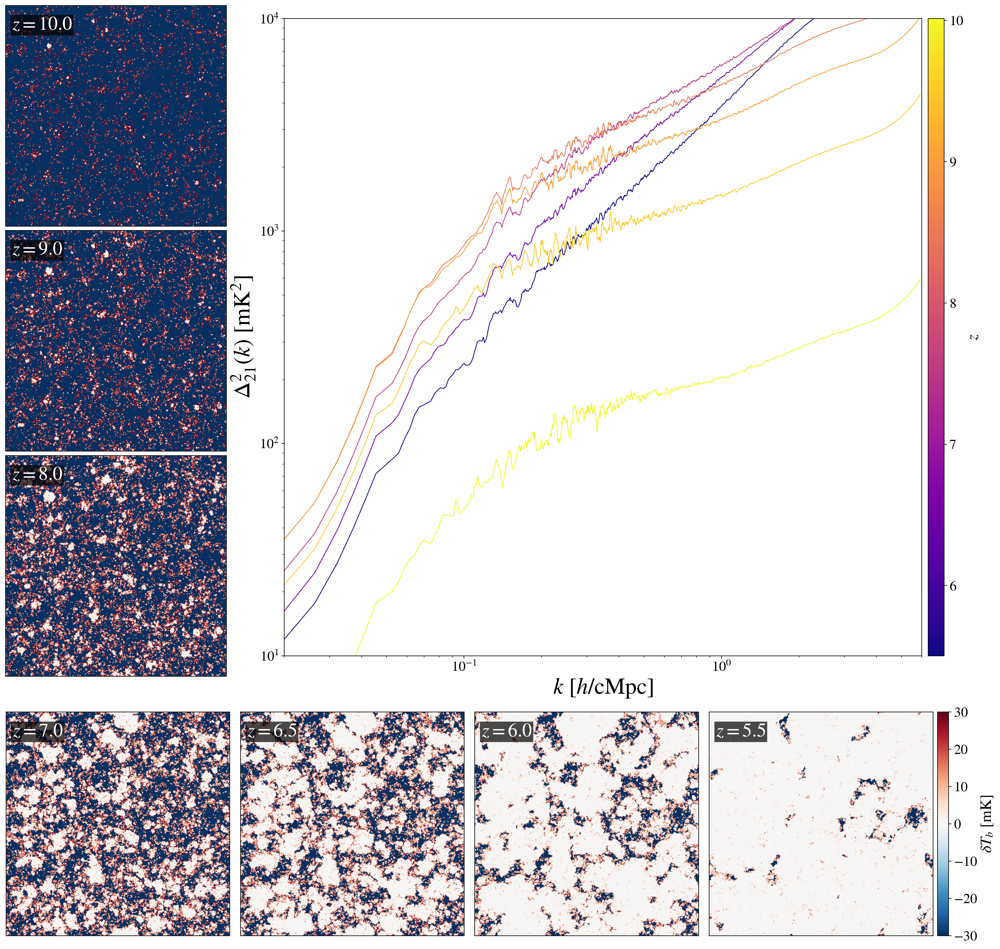

In [72]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import TwoSlopeNorm, Normalize
from matplotlib.cm import ScalarMappable
import matplotlib as mpl
from scipy.signal import savgol_filter
import h5py
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# -----------------------------------
# snapshots
# -----------------------------------

snaps = [156, 181, 209, 255, 289, 325, 364]
z_labels = [10.0, 9.0, 8.0, 7.0, 6.5, 6.0, 5.5]

# -----------------------------------
# normalization
# -----------------------------------

norm = TwoSlopeNorm(vmin=-30, vcenter=0, vmax=30)

# -----------------------------------
# FIGURE LAYOUT (CRITICAL FIX)
# -----------------------------------

fig = plt.figure(figsize=(18.5,18.5))

gs = gridspec.GridSpec(
    2, 2,
    height_ratios=[3, 1],   # ← THIS is the correct relationship
    width_ratios=[1, 3],
    hspace=0.08,
    wspace=0.08
)

# -----------------------------------
# LEFT COLUMN (top-left)
# -----------------------------------

gs_left = gs[0,0].subgridspec(3,1, hspace=0.02)
axes_left = [fig.add_subplot(gs_left[i,0]) for i in range(3)]

# -----------------------------------
# PS PANEL
# -----------------------------------

ax_ps = fig.add_subplot(gs[0,1])

# -----------------------------------
# BOTTOM ROW (4 maps)
# -----------------------------------

gs_bottom = gs[1,:].subgridspec(1,4, wspace=0.03)
axes_bottom = [fig.add_subplot(gs_bottom[0,i]) for i in range(4)]

# -----------------------------------
# LOAD SLICE (HDF5)
# -----------------------------------

def load_slice(snap):
    file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TK_ad/H/Tb/RIN_H_ad_{snap:03d}.out"
    
    with h5py.File(file, "r") as f:
        Tb_cube = f["rin"][:]

    if Tb_cube.ndim == 1:
        N = int(round(len(Tb_cube)**(1/3)))
        Tb_cube = Tb_cube.reshape((N, N, N))
    else:
        N = Tb_cube.shape[0]

    return Tb_cube[:, :, N//2]

# -----------------------------------
# LOAD PS
# -----------------------------------

def load_ps(filename, skiprows=5):
    with open(filename) as f:
        lines = f.readlines()
        z = float(lines[0])
        mean = float(lines[2]) / float(lines[3])

    data = np.loadtxt(filename, skiprows=skiprows)

    k = data[:,0]
    delta2 = data[:,1]
    nmodes = data[:,3]

    delta2 *= mean**2
    k *= 1e3

    mask = nmodes > 0
    return z, k[mask], delta2[mask]

# -----------------------------------
# MAPS
# -----------------------------------

# left column
for i, snap in enumerate(snaps[:3]):
    Tb = load_slice(snap)

    axes_left[i].imshow(
        Tb.T,
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        extent=[0,500,0,500]
    )

    axes_left[i].set_xticks([])
    axes_left[i].set_yticks([])
    #axes_left[i].text(0.03, 0.95, f"{snap}",
    #                  color="white", transform=axes_left[i].transAxes, va="top")
    axes_left[i].text(
    0.03, 0.95, rf"$z={z_labels[i]:.1f}$",
    color="white",
    fontsize=25,
    transform=axes_left[i].transAxes,
    va="top",
    bbox=dict(facecolor='black', alpha=0.7, edgecolor='none', pad=2)
    )
    
# bottom row
for i, snap in enumerate(snaps[3:]):
    Tb = load_slice(snap)

    axes_bottom[i].imshow(
        Tb.T,
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        extent=[0,500,0,500]
    )

    axes_bottom[i].set_xticks([])
    axes_bottom[i].set_yticks([])
    #axes_bottom[i].text(0.03, 0.95, f"{snap}",
    #                    color="white", transform=axes_bottom[i].transAxes, va="top")
    axes_bottom[i].text(
    0.03, 0.95, rf"$z={z_labels[i+3]:.1f}$",
    color="white",
    fontsize=25,
    transform=axes_bottom[i].transAxes,
    va="top",
    bbox=dict(facecolor='black', alpha=0.7, edgecolor='none', pad=2)
)

# -----------------------------------
# 🔥 CRITICAL: FORCE IDENTICAL SQUARE PANELS
# -----------------------------------

for ax in axes_left + axes_bottom:
    ax.set_box_aspect(1)

# -----------------------------------
# POWER SPECTRUM
# -----------------------------------

ps_files = [
    "./TK_ad/H/Tb/PS_H_ad_156.out",
    "./TK_ad/H/Tb/PS_H_ad_181.out",
    "./TK_ad/H/Tb/PS_H_ad_209.out",
    "./TK_ad/H/Tb/PS_H_ad_255.out",
    "./TK_ad/H/Tb/PS_H_ad_289.out",
    "./TK_ad/H/Tb/PS_H_ad_325.out",
    "./TK_ad/H/Tb/PS_H_ad_364.out",
]

ps_data = []
for f in ps_files:
    z, k, d = load_ps(f)
    ps_data.append((z, k, d))

ps_data.sort(key=lambda x: x[0], reverse=True)
zs = np.array([x[0] for x in ps_data])

cmap_ps = plt.get_cmap("plasma_r")
norm_ps = Normalize(vmin=zs.min(), vmax=zs.max())

for z, k, d in ps_data:
    logd = np.log10(d)
    smooth = savgol_filter(logd, 11, 2)
    d_smooth = 10**smooth

    ax_ps.loglog(k, d_smooth, color=cmap_ps(norm_ps(z)), lw=1)



ax_ps.set_xlabel(r"$k\ [h/\mathrm{cMpc}]$", fontsize=30)
ax_ps.set_ylabel(r"$\Delta^2_{21}(k)\ [\mathrm{mK}^2]$", fontsize=30)
ax_ps.set_xlim(0.02, 6)
ax_ps.set_ylim(10, 1e4)

#ax_ps.tick_params(which='both', direction='in', top=True, right=True)
ax_ps.tick_params(axis='both', labelsize=18)
ax_ps.minorticks_on()

# -----------------------------------
# COLORBAR: z (PS)
# -----------------------------------

cax_z = inset_axes(
    ax_ps,
    width="2.5%",
    height="100%",
    loc="lower left",
    bbox_to_anchor=(1.01, 0., 1, 1),   # ← push outside to the right
    bbox_transform=ax_ps.transAxes,
    borderpad=0
)

sm_z = ScalarMappable(norm=norm_ps, cmap="plasma")
cb_z = fig.colorbar(sm_z, cax=cax_z)
cb_z.set_label(r"$z$", fontsize=20)
cb_z.ax.tick_params(labelsize=18)

# -----------------------------------
# COLORBAR: Tb (maps)
# -----------------------------------

ax_last = axes_bottom[-1]

cax_tb = inset_axes(
    ax_last,
    width="5%",
    height="100%",
    loc="lower left",
    bbox_to_anchor=(1.02, 0., 1, 1),   # ← same logic
    bbox_transform=ax_last.transAxes,
    borderpad=0
)

sm = ScalarMappable(norm=norm, cmap="RdBu_r")
cb_tb = fig.colorbar(sm, cax=cax_tb)
cb_tb.set_label(r"$\delta T_b\ [\mathrm{mK}]$", fontsize=20)
cb_tb.ax.tick_params(labelsize=18)

# -----------------------------------
# FINAL SPACING
# -----------------------------------

plt.subplots_adjust(left=0.06, right=0.97, top=0.97, bottom=0.06)

# -----------------------------------
# FINAL: shrink PS panel (AFTER layout is fixed)
# -----------------------------------

pos = ax_ps.get_position()

ax_ps.set_position([
    pos.x0 + 0.02,    # shift right → helps y-label
    pos.y0 + 0.02,    # shift up → helps x-label
    pos.width * 0.95,
    pos.height * 0.95
])

plt.savefig("adiabatic.png", dpi=200, bbox_inches="tight")
plt.show()

In [2]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import h5py
from matplotlib.colors import TwoSlopeNorm


def T_map_hdf5(hdf5_file, plot_file, box_size=500.0):

    # ---------------------------
    # Read HDF5 cube
    # ---------------------------
    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/rin"][:]   # shape (N, N, N)

    N = Tb_cube.shape[0]

    # ---------------------------
    # Choose central k slice
    # ---------------------------
    k_slice = N // 2
    Tb = Tb_cube[:, :, k_slice]

    # ---------------------------
    # Plot
    # ---------------------------
    fig, ax = plt.subplots(figsize=(6, 7))

    norm = TwoSlopeNorm(
        vmin=-10,
        vcenter=0.0,
        vmax=30
    )

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        extent=[0, box_size, 0, box_size],
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        pad=0.08,
        fraction=0.04,
        shrink=0.8,
        aspect=30
    )

    cbar.set_ticks([-5, 0, 10, 20])
    cbar.set_ticklabels([
        r"$-5$",
        r"$0$",
        r"$10$",
        r"$20$",
    ])

    cbar.set_label(r"$\delta T\ [\mathrm{mK}]$")

    ax.set_xlabel(r"$x$ [cMpc]")
    ax.set_ylabel(r"$y$ [cMpc]")

    ax.tick_params(which="both", direction="in", top=True, right=True)

    plt.tight_layout()
    fig.savefig(plot_file, dpi=300, bbox_inches="tight")
    #plt.show()
    plt.close(fig)

In [5]:
for snap in range(576, 709):   # 709 because upper bound is exclusive
    
    hdf5_file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_{snap:03d}.hdf5"
    png_file  = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_map_{snap:03d}.png"

    T_map_hdf5(
        hdf5_file,
        png_file,
        box_size=500
    )

In [3]:
def T_map_He_hdf5(hdf5_file, plot_file, box_size=500.0):

    # ---------------------------
    # Read HDF5 cube
    # ---------------------------
    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/rin"][:]   # shape (N, N, N)

    N = Tb_cube.shape[0]

    # ---------------------------
    # Choose central k slice
    # ---------------------------
    k_slice = N // 2
    Tb = Tb_cube[:, :, k_slice]

    # ---------------------------
    # Plot
    # ---------------------------
    fig, ax = plt.subplots(figsize=(6, 7))

    norm = TwoSlopeNorm(
        vmin=-1.0e-4,
        vcenter=0.0,
        vmax=10
    )

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        extent=[0, box_size, 0, box_size],
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        pad=0.08,
        fraction=0.04,
        shrink=0.8,
        aspect=30
    )

    cbar.set_ticks([-1.0e-4, 0, 2.5, 5])
    cbar.set_ticklabels([
        r"$-10^{-4}$",
        r"$0$",
        r"$2.5$",
        r"$5$",
    ])

    cbar.set_label(r"$\delta T\ [\mu\mathrm{K}]$")

    ax.set_xlabel(r"$x$ [cMpc]")
    ax.set_ylabel(r"$y$ [cMpc]")

    ax.tick_params(which="both", direction="in", top=True, right=True)

    plt.tight_layout()
    fig.savefig(plot_file, dpi=300, bbox_inches="tight")
    #plt.show()
    plt.close(fig)

In [4]:
for snap in range(578, 709):   # 709 because upper bound is exclusive
    print(f"Processing {snap}...")

    hdf5_file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/He/Tb/Tb_He_{snap:03d}.hdf5"
    png_file  = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/He/Tb/Tb_He_map_{snap:03d}.png"

    T_map_He_hdf5(
        hdf5_file,
        png_file,
        box_size=500
    )

Processing 578...
Processing 579...
Processing 580...
Processing 581...
Processing 582...
Processing 583...
Processing 584...
Processing 585...
Processing 586...
Processing 587...
Processing 588...
Processing 589...
Processing 590...
Processing 591...
Processing 592...
Processing 593...
Processing 594...
Processing 595...
Processing 596...
Processing 597...
Processing 598...
Processing 599...
Processing 600...
Processing 601...
Processing 602...
Processing 603...
Processing 604...
Processing 605...
Processing 606...
Processing 607...
Processing 608...
Processing 609...
Processing 610...
Processing 611...
Processing 612...
Processing 613...
Processing 614...
Processing 615...
Processing 616...
Processing 617...
Processing 618...
Processing 619...
Processing 620...
Processing 621...
Processing 622...
Processing 623...
Processing 624...
Processing 625...
Processing 626...
Processing 627...
Processing 628...
Processing 629...
Processing 630...
Processing 631...
Processing 632...
Processing

## Zoomed

In [3]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm


def T_map_hdf5_zoom(hdf5_file, plot_file, zoom_pix=128, box_size=500.0):

    # ---------------------------
    # Read HDF5 cube
    # ---------------------------
    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/rin"][:]   # shape (N, N, N)

    N = Tb_cube.shape[0]

    # ---------------------------
    # Central slice
    # ---------------------------
    c = N // 2
    k_slice = c
    half = zoom_pix // 2

    Tb = Tb_cube[c-half:c+half, c-half:c+half, k_slice]

    # ---------------------------
    # Physical zoom size
    # ---------------------------
    dx = box_size / N
    zoom_size = zoom_pix * dx

    # ---------------------------
    # Plot
    # ---------------------------
    fig, ax = plt.subplots(figsize=(6,7))

    norm = TwoSlopeNorm(
        vmin=-10,
        vcenter=0.0,
        vmax=30
    )

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        extent=[0, zoom_size, 0, zoom_size]
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        pad=0.08,
        fraction=0.04,
        shrink=0.8,
        aspect=30
    )

    cbar.set_ticks([-5, 0, 10, 20])
    cbar.set_ticklabels([
        r"$-5$",
        r"$0$",
        r"$10$",
        r"$20$",
    ])

    cbar.set_label(r"$\delta T\ [\mathrm{mK}]$")

    ax.set_xlabel(r"$x$ [cMpc]")
    ax.set_ylabel(r"$y$ [cMpc]")

    ax.tick_params(which="both", direction="in", top=True, right=True)

    plt.tight_layout()
    fig.savefig(plot_file, dpi=300, bbox_inches="tight")
    plt.close(fig)

In [4]:
for snap in range(573, 709):   # 709 because upper bound is exclusive
    
    hdf5_file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_{snap:03d}.hdf5"
    png_file  = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Zoom_Tb_map_{snap:03d}.png"
    print(f"Processing {hdf5_file}")
    T_map_hdf5_zoom(
        hdf5_file,
        png_file,
        box_size=500
    )

Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_573.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_574.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_575.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_576.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_577.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_578.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_579.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_580.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_581.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_582.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_583.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_584.hdf5
Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/H/Tb/Tb_H_585.hdf5
Processing /orcd/data/mvogelsb/004/chc

In [2]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm


def T_map_He_hdf5_zoom(hdf5_file, plot_file, zoom_pix=128, box_size=500.0):

    # ---------------------------
    # Read HDF5 cube
    # ---------------------------
    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/rin"][:]   # shape (N,N,N)

    N = Tb_cube.shape[0]

    # ---------------------------
    # Choose central slice
    # ---------------------------
    c = N // 2
    k_slice = c
    half = zoom_pix // 2

    Tb = Tb_cube[c-half:c+half, c-half:c+half, k_slice]

    # ---------------------------
    # Physical zoom size
    # ---------------------------
    dx = box_size / N
    zoom_size = zoom_pix * dx

    # ---------------------------
    # Plot
    # ---------------------------
    fig, ax = plt.subplots(figsize=(6, 7))

    norm = TwoSlopeNorm(
        vmin=-1.0e-4,
        vcenter=0.0,
        vmax=10
    )

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        extent=[0, zoom_size, 0, zoom_size],
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        pad=0.08,
        fraction=0.04,
        shrink=0.8,
        aspect=30
    )

    cbar.set_ticks([-1.0e-4, 0, 2.5, 5])
    cbar.set_ticklabels([
        r"$-10^{-4}$",
        r"$0$",
        r"$2.5$",
        r"$5$",
    ])

    cbar.set_label(r"$\delta T\ [\mu\mathrm{K}]$")

    ax.set_xlabel(r"$x$ [cMpc]")
    ax.set_ylabel(r"$y$ [cMpc]")

    ax.tick_params(which="both", direction="in", top=True, right=True)

    plt.tight_layout()
    fig.savefig(plot_file, dpi=300, bbox_inches="tight")
    plt.close(fig)

In [ ]:
for snap in range(632, 709):   # 709 because upper bound is exclusive
    
    hdf5_file = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/He/Tb/Tb_He_{snap:03d}.hdf5"
    png_file  = f"/orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/He/Tb/Zoom_Tb_He_map_{snap:03d}.png"
    print(f"Processing {hdf5_file}")

    T_map_He_hdf5_zoom(
        hdf5_file,
        png_file,
        box_size=500
    )

Processing /orcd/data/mvogelsb/004/chcho/PS_21cm/TS_TK/He/Tb/Tb_He_632.hdf5


## Old


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm


def T_map_also_old(output_file, plot_file):

    cols = ["i", "j", "k", "rin"]

    df = pd.read_csv(
        output_file,
        sep=r"\s+",          # replaces deprecated delim_whitespace
        names=cols,
        comment="#"
    )

    # choose slice
    k_slice = int(df["k"].median())
    sl = df[df["k"] == k_slice]

    N = int(df["i"].max() + 1)

    Tb = np.full((N, N), np.nan)
    Tb[sl["i"].values, sl["j"].values] = sl["rin"].values

    box_size = 500.0  # cMpc

    fig, ax = plt.subplots(figsize=(6, 7))

    from matplotlib.colors import TwoSlopeNorm
    
    norm = TwoSlopeNorm(
        vmin=-2e-4,
        vcenter=0.0,
        vmax=20
    )

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        extent=[0, box_size, 0, box_size],
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        pad=0.08,
        fraction=0.04,
        shrink=0.8,
        aspect=30
    )
    
    cbar.set_ticks([-1e-4, 0, 5, 10])
    
    cbar.set_ticklabels([
        r"$-10^{-4}$",
        r"$0$",
        r"$5$",
        r"$0$",
    ])
    
    cbar.set_label(r"$\delta T_{3.46}\ [\mu\mathrm{K}]$")
    
    ax.set_xlabel(r"$x$ [cMpc]")
    ax.set_ylabel(r"$y$ [cMpc]")

    # Optional: inward ticks like your PS plots
    ax.tick_params(which='both', direction='in', top=True, right=True)

    plt.tight_layout()

    # Save
    fig.savefig(plot_file, dpi=300, bbox_inches="tight")

    # Show in notebook
    plt.show()

    plt.close(fig)

In [ ]:
import glob
import os

# get all matching files
files = sorted(glob.glob("./output/RIN_H_z*.out"))

for infile in files:
    
    # Extract "zX" part
    base = os.path.basename(infile)            # RIN_H_z4.out
    z_part = base.replace("RIN_H_", "")       # z4.out
    z_part = z_part.replace(".out", "")        # z4
    
    # Create output filename
    outfile = f"Map_H_{z_part}.png"
    
    print(f"Processing {infile} → {outfile}")
    
    T_map(infile, outfile)

In [ ]:
import glob
import os

# get all matching files
files = sorted(glob.glob("./output/RIN_He_z*.out"))

for infile in files:
    
    # Extract "zX" part
    base = os.path.basename(infile)            # RIN_H_z4.out
    z_part = base.replace("RIN_He_", "")       # z4.out
    z_part = z_part.replace(".out", "")        # z4
    
    # Create output filename
    outfile = f"Map_He_{z_part}.png"
    
    print(f"Processing {infile} → {outfile}")
    
    T_map(infile, outfile)

## Histogram

In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm


def T_map_hist_hdf5(hdf5_file, plot_file, hist_plot_file, box_size=500.0):

    # ---------------------------
    # Read cube
    # ---------------------------
    with h5py.File(hdf5_file, "r") as f:
        Tb_cube = f["/rin"][:]

    N = Tb_cube.shape[0]

    # ---------------------------
    # Slice for visualization
    # ---------------------------
    k_slice = N // 2
    Tb = Tb_cube[:, :, k_slice]

    # ---------------------------
    # MAP PLOT
    # ---------------------------
    fig, ax = plt.subplots(figsize=(6,7))

    norm = TwoSlopeNorm(vmin=-2e-4, vcenter=0.0, vmax=50)

    im = ax.imshow(
        Tb.T,
        origin="lower",
        cmap="RdBu_r",
        norm=norm,
        extent=[0, box_size, 0, box_size],
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
        orientation="horizontal",
        pad=0.08,
        fraction=0.04,
        shrink=0.8,
        aspect=30
    )

    cbar.set_label(r"$\delta T\ [\mathrm{mK}]$")

    ax.set_xlabel(r"$x$ [cMpc]")
    ax.set_ylabel(r"$y$ [cMpc]")
    ax.tick_params(which="both", direction="in", top=True, right=True)

    plt.tight_layout()
    fig.savefig(plot_file, dpi=300)
    plt.close(fig)

    # ---------------------------
    # HISTOGRAM PLOT
    # ---------------------------
    Tb_all = Tb_cube.flatten()

    fig, ax = plt.subplots(figsize=(6,5))

    ax.hist(Tb_all, bins=200)

    ax.set_xlabel(r"$\delta T\ [\mathrm{mK}]$")
    ax.set_ylabel("Number of cells")

    ax.set_yscale("log")   # useful for wide distributions
    ax.tick_params(direction="in", top=True, right=True)

    plt.tight_layout()
    fig.savefig(hist_plot_file, dpi=300)
    plt.close(fig)

    del Tb_cube
    del Tb_all